In [1]:
import os
import re
import sys
import math
import pickle
import hashlib
import itertools
import warnings
import contextlib
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.figure import Figure
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.ndimage import maximum_filter, label as _label_cc
from scipy.stats import gaussian_kde
from scipy.interpolate import RegularGridInterpolator
import tkinter as tk
from tkinter import filedialog, simpledialog, messagebox

try:
    from tqdm import tqdm  # pip install tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None, **kwargs):
        """
        Fallback mínimo si la librería 'tqdm' no está instalada: imprime el
        progreso como porcentaje sobre la misma línea de la terminal.
        """
        if total is None:
            try:
                total = len(iterable)
            except TypeError:
                total = None
        prefijo = f"{desc}: " if desc else ""
        for i, item in enumerate(iterable, start=1):
            yield item
            if total:
                pct = 100 * i / total
                print(f"\r{prefijo}{pct:5.1f}% ({i}/{total})", end="", flush=True)
        if total:
            print()

# ---------------------------------------------------------------------------
# PARÁMETROS GLOBALES Y UTILIDADES
# ---------------------------------------------------------------------------
N_BOOTSTRAP_INCERTIDUMBRE = 10000   # número de réplicas bootstrap por panel
BOOTSTRAP_GRID_RES = 250j          # malla del bootstrap

# ---- pesos del KDE ---------------------------------------------------------
#   "area"     : log10(A_estable + 1)
#   "fraccion" : A_est / (A_est + A_inest + A_colisión m2)   <- usa las tres regiones
#   "neto"     : log10(max(A_est - (A_inest + A_col), 0) + 1)
MODO_PESO_DEFECTO = "fraccion"

# ---- incertidumbre 1σ / 2σ / 3σ ---------------------------------------------
SIGMAS = (1, 2, 3)                 # k-sigma que se calculan y exportan a CSV
SIGMAS_DIBUJAR = (1, 2, 3)         # k-sigma que se dibujan como bandas anidadas
# "std": centro ± k·std(réplicas)  |  "percentil": cobertura gaussiana de k·σ
METODO_SIGMA_DIBUJO = "percentil"
ALPHA_BANDA_SIGMA = 0.07           # alpha de cada banda si se dibuja más de una
DIBUJAR_BANDAS_SIGMA = False       # False = sin franjas sombreadas 1σ/2σ/3σ (el bootstrap y los CSV siguen igual)

# ---- regiones de máxima densidad ---------------------------------------------
# Dos islas se consideran la MISMA región solo si están cerca en distancia (x) Y en masa (y):
# las separa un hueco < GAP_REGIONES_DEX en ambos ejes (log10).
GAP_REGIONES_DEX = 0.08
COLOR_LIMITES = "lime"             # color por defecto (verde)
# Color de las líneas a_min / a_max de cada región, en orden de distancia:
# 1ª región = verde, 2ª = roja, 3ª = azul (la 4ª, si existe, magenta)
COLORES_REGIONES = ["lime", "red", "dodgerblue", "magenta"]
# (estilo a_min, estilo a_max) por región; el estilo distingue la región
LS_REGIONES = [("-", "--"),
               ("-.", ":"),
               ((0, (5, 1.5)), (0, (1, 1))),
               ((0, (3, 1, 1, 1, 1, 1)), (0, (5, 5)))]

# ---- robustez de la incertidumbre de las regiones ----------------------------
BOOT_POR_SISTEMAS = True      # remuestrea SISTEMAS completos (los planetas de un sistema no son independientes)
KDE_COV_FIJA = True           # en el bootstrap, el kernel del KDE usa la covarianza del ajuste nominal
                              # (con bw_method escalar el ancho cambia en cada réplica y mete ruido)
METODO_ERROR_REGION = "percentil"   # "percentil": (P84-P16)/2 en log a  |  "std": desviación estándar
MODO_UMBRAL_REGION = "pico"   # "pico": densidad >= NIVEL_REGION_ESTABLE % del máximo
                              # "hdr" : región que encierra MASA_HDR de la probabilidad (no depende del pico)
MASA_HDR = 0.50

# Límites de ejes (log10) de la figura única del Sistema Solar.
# None = automático a partir de los datos. (y = (-2, 2) recortaría Júpiter, log10 M = 2.5)
LIM_SISTEMA_SOLAR_X = (-1.0, 2.0)   # log10(distancia / AU)
MARCA_X_SISTEMA_SOLAR = math.log10(46.0)   # log10(AU) de la región a resaltar: 46 AU (None = sin marca)
LIM_SISTEMA_SOLAR_Y = None          # log10(masa / M_Tierra)

# ---- regiones estables como ISLAS (picos locales) y su incertidumbre ----------
# "picos"  : cada isla de densidad (máximo local >= NIVEL_MIN_PICO %) es una región.
# "umbral" : método anterior (todo >= NIVEL_REGION_ESTABLE % del máximo global).
MODO_REGIONES = "picos"
NIVEL_MIN_PICO = 20.0          # % del máximo global: islas más débiles no se marcan (antes 30; bájalo para marcar más islas)
NIVEL_MIN_PICO_SOLAR = 10.0    # idem, solo en la figura del Sistema Solar (capta la región de ~1.6)
PICO_VENTANA_DEX = 0.4         # un máximo local debe ser el mayor en una ventana de esta anchura (dex)
TOL_ASIGNACION_DEX = 0.5       # bootstrap: tolerancia en log distancia para asignar un tramo a una región nominal
TOL_ASIGNACION_Y_DEX = 1.0     # idem en log masa (la asignación es en el plano a-m, no solo en a)
ERROR_ASIMETRICO = True        # a_min = a (+up / -dn) en UA; evita límites inferiores negativos
# Color de las franjas 1σ/2σ/3σ de cada región (la 1ª blanca; las demás con otro color)
COLORES_BANDAS_REGION = ["white", "cyan", "gold", "orchid"]

# [NUEVO] Umbral de cada isla según la altura de su pico (evita que una isla difusa se "inunde" hacia
# el núcleo más alto y se fusione con él, que era la causa de la región G expandida a ~3.2 AU):
#   True : umbral = nivel de NIVELES_REGIONES inmediatamente inferior a la altura del pico
#          (núcleo 100 % -> 90.9 | segundo pico ~85 % -> 80.8 | ~65 % -> 60.6 ...). Además, si la
#          componente conexa aún contiene el pico de una isla más alta, el umbral se sube hasta separarlas.
#   False: método anterior (NIVEL_REGION_ESTABLE % del pico propio).
NIVELES_POR_ALTURA = True

# [NUEVO] Número de regiones (islas de mayor densidad) por figura. None / no listado = todas las que
# detecte el método. Figura en fila (Spectral Type X):
REGIONES_FILA = {"F": 2,       # isla de ~1 M_Tierra + isla de masas neptunianas
                 "G": 2,       # región principal (90.9 %) + isla cercana a Júpiter
                 "K": 3,
                 "M": 1}       # solo la región acotada al 90.9 %
# Figuras por multiplicidad: (tipo, nº de planetas) -> nº de regiones
REGIONES_MULT = {("F", 3): 3,
                 ("K", 3): 3, ("K", 4): 3, ("K", 5): 1,
                 ("M", 3): 1, ("M", 4): 1, ("M", 5): 1, ("M", 7): 1}

DIBUJAR_ISOLINEAS = True           # isolíneas blancas difuminadas (False = sin isolíneas)

# ---- límites de masa de cada región (líneas horizontales / "cuadrados de masa") ---------------
# Para cada región se dibuja el RECTÁNGULO de la isla: las líneas verticales a_min / a_max (de altura
# completa) y las horizontales m_min / m_max entre a_min y a_max, con un relleno tenue del color de la región.
DIBUJAR_LIMITES_MASA = True
LIMITES_MASA_ANCHO_COMPLETO = False   # False: la línea cubre solo [a_min, a_max]; True: cruza todo el panel
RELLENO_CAJA_MASA = 0.08              # alpha del relleno del rectángulo de cada región (0 = sin relleno)

# ---- salida y ejecución --------------------------------------------------------
SALIDA_CARPETA = "graficos_magma_con_sistemas_azules"

# ---- método de detección -------------------------------------------------------
# Se lee del README de cada planeta ("Método de detección: Radial Velocity" / "Transit").
# nombre canónico -> subcarpeta de salida (cada método tiene sus figuras, CSV y caché propios)
METODOS_DETECCION = {"Radial Velocity": "Radial_Velocity", "Transit": "Transit"}
POR_METODO_DEFECTO = True          # True = figuras separadas por método | False = todos juntos (como antes)
RE_METODO_DETECCION = re.compile(r"M[eé]todo\s+de\s+detecci[oó]n[\s*_`]*:\s*([^\r\n]+)", re.IGNORECASE)
MOSTRAR_FIGURAS = True             # False = solo guarda (útil sin pantalla)

# ---- caché del KDE ------------------------------------------------------------
# El KDE + las regiones + el bootstrap de cada panel se guardan en <salida>/cache_kde/*.pkl.
# La clave del archivo es un hash de los datos del panel y de TODOS los parámetros que afectan
# al resultado: si cambias datos, pesos, ancho de banda, niveles, etc., se recalcula solo.
USAR_CACHE_KDE = True
FORZAR_RECALCULO_KDE = False       # True = ignora la caché y la sobrescribe
CACHE_KDE_NOMBRE = "cache_kde"
SEMILLA_BOOTSTRAP = 12345          # semilla fija -> resultados reproducibles (None = aleatoria)
_CACHE_VERSION = "v4"              # v4: umbral de cada isla por altura del pico + nº de regiones por figura
_CACHE_DIR = None

# ---- leyendas (tamaño y posición) ---------------------------------------------
# fs: fuente | ms: marcadores Tierra/Júpiter | ncol: columnas | y: posición vertical bajo el eje
# fs_cajas: cajas de a_min / a_max sobre el panel
LEYENDA_DEFECTO = {"fs": 9.0, "ms": 7, "ncol": 2, "y": -0.16, "fs_cajas": 8.5}
LEYENDA_POR_TIPO = {                # ajustes por tipo espectral (se suman a LEYENDA_DEFECTO)
    "F": {"fs": 9.5, "ncol": 2, "y": -0.18},
}
LEYENDA_SOLAR = {"fs": 12, "ms": 8, "ncol": 3, "y": -0.15, "fs_cajas": 10}
LEYENDA_COMPARACION_FS = 10.5      # leyenda de la figura Sistema Solar vs. G
ANCHO_PANEL_TIPO = 7.4             # ancho (pulgadas) por panel en plot_figuras_por_tipo
ANCHO_PANEL_MATRIZ = 7.2           # ídem en plot_matriz_tipo_multiplicidad
ANCHO_PANEL_FILA = 7.6             # ídem en plot_tipos_espectrales_fila

# ---- Sistema Solar -----------------------------------------------------------------
# Ya NO se mezcla con las estrellas tipo G: las figuras F, G, K, M se hacen sin él y el
# Sistema Solar tiene su propia figura unificada (etapa "solar").
SISTEMA_SOLAR = {
    "activo": True,
    "preguntar": True,             # True = pregunta con un diálogo si lo incluye
    "tipo_estrella": "G",          # solo se usa en la etapa "comparar" (Sistema Solar vs. G)
    "nombre_sistema": "Solar System",
    "n_planetas_total": 8,
    "marcador": "*", "color": "gold",
    # nombre: (a [UA], masa [M_tierra], A_estable, A_inestable, A_colisión_m2 [km²],
    #          zonas_estables, zonas_inestables, zonas_colisión_m2)   (colisión m1 = 0)
    "planetas": {
        "Mercury": (0.387, 0.0553, 3.01e12, 5.33e14, 2.15e12,  56, 9904, 40),
        "Venus":   (0.723, 0.815,  1.27e13, 1.85e15, 4.29e12,  68, 9909, 23),
        "Earth":   (1.000, 1.000,  2.59e13, 3.57e15, 7.92e12,  72, 9906, 22),
        "Mars":    (1.524, 0.107,  5.16e13, 8.24e15, 2.58e13,  62, 9907, 31),
        "Jupiter": (5.203, 317.8,  6.82e15, 9.00e16, 9.68e12, 704, 9295,  1),
        "Saturn":  (9.537, 95.16,  1.29e16, 3.13e17, 2.61e14, 397, 9595,  8),
        "Uranus":  (19.19, 14.54,  2.03e16, 1.30e18, 1.85e15, 154, 9832, 14),
        "Neptune": (30.07, 17.15,  5.57e16, 3.18e18, 4.53e15, 172, 9814, 14),
    },
}


def _mostrar_o_cerrar(fig):
    if MOSTRAR_FIGURAS:
        plt.show()
    plt.close(fig)


def _safe_log10(x):
    """log10 blindado: retorna log10(x + 1) para evitar log(0) = -inf."""
    return np.log10(np.asarray(x, dtype=float) + 1.0)


def _calcular_pesos(df_sub: pd.DataFrame, modo=None) -> np.ndarray:
    """
    Peso de cada planeta para el KDE, a partir de las áreas del resumen.txt.
      "area"     : log10(A_estable + 1)
      "fraccion" : A_estable / (A_estable + A_inestable + A_colisión_m2)
      "neto"     : log10(max(A_estable - (A_inestable + A_colisión_m2), 0) + 1)
    """
    modo = modo or MODO_PESO_DEFECTO
    est = df_sub["Area_Estable_km2"].to_numpy(dtype=float)
    ine = (df_sub["Area_Inestable"].to_numpy(dtype=float)
           if "Area_Inestable" in df_sub.columns else np.zeros_like(est))
    col = (df_sub["Area_Colision_m2"].to_numpy(dtype=float)
           if "Area_Colision_m2" in df_sub.columns else np.zeros_like(est))
    if modo == "area":
        return _safe_log10(est)
    if modo == "fraccion":
        total = est + ine + col
        return np.divide(est, total, out=np.zeros_like(est), where=total > 0)
    if modo == "neto":
        return _safe_log10(np.clip(est - (ine + col), 0.0, None))
    raise ValueError(f"modo_peso desconocido: {modo!r} (usa 'area', 'fraccion' o 'neto')")


def _pesos_validos(w) -> bool:
    w = np.asarray(w, dtype=float)
    return bool(np.isfinite(w).all() and w.sum() > 0 and np.ptp(w) >= 0)


def _asignar_estilos_sistema(df: pd.DataFrame) -> dict:
    """
    Genera combinaciones únicas de marcador/color para cada sistema estelar.
    Devuelve un dict {nombre_sistema: {'marker': ..., 'color': ...}}.
    El Sistema Solar siempre usa su estilo propio (estrella dorada).
    """
    if "Sistema" not in df.columns:
        df = df.copy()
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    sistemas_unicos = df["Sistema"].unique()
    marcadores_base = ["o", "s", "^", "D", "v", "p", "*", "h",
                       "H", "X", "d", "P", "<", ">"]
    colores_base = plt.cm.tab20.colors
    combinaciones = itertools.product(marcadores_base, colores_base)

    estilos = {}
    for sist, (marker, color) in zip(sistemas_unicos, combinaciones):
        estilos[sist] = {"marker": marker, "color": color}

    ss = SISTEMA_SOLAR
    if ss["activo"] and ss["nombre_sistema"] in estilos:
        estilos[ss["nombre_sistema"]] = {"marker": ss["marcador"], "color": ss["color"]}
    return estilos


def _calcular_limites_criticos(Z_pct: np.ndarray, X: np.ndarray):
    """
    Dado el campo de densidad KDE normalizado en porcentaje (0 a 100%) y su malla X,
    determina los límites críticos de la región más estable (por ejemplo, >= 85% / 90.9%).
    """
    Z_flat = Z_pct.flatten()
    niveles = np.linspace(np.percentile(Z_flat, 10), np.percentile(Z_flat, 98), 25)
    umbral = niveles[-4]
    indices_alta_densidad = np.where(Z_pct >= umbral)
    x_alta_densidad = X[indices_alta_densidad]
    if len(x_alta_densidad) == 0:
        return None, None
    return float(np.min(x_alta_densidad)), float(np.max(x_alta_densidad))


def _bootstrap_limites_criticos(x, y, weights, xlims, ylims,
                                n_bootstrap=None, grid_res=None, rng=None):
    """
    Estima la incertidumbre asociada al modelo (KDE) en la determinación de
    las distancias críticas a_min y a_max mediante bootstrap no paramétrico.
    """
    n_bootstrap = n_bootstrap or N_BOOTSTRAP_INCERTIDUMBRE
    grid_res = grid_res or BOOTSTRAP_GRID_RES
    if rng is None:
        rng = np.random.default_rng()

    n = len(x)
    log_min_boot, log_max_boot = [], []

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    positions_b = np.vstack([Xb.ravel(), Yb.ravel()])

    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap a_min/a_max", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]

        if x_b.var() == 0 or y_b.var() == 0 or w_b.sum() <= 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=0.6)
            Z_b = np.reshape(kde_b(positions_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue

        log_min_b, log_max_b = _calcular_limites_criticos(Z_b, Xb)
        if log_min_b is not None:
            log_min_boot.append(log_min_b)
            log_max_boot.append(log_max_b)

    return log_min_boot, log_max_boot


# ---------------------------------------------------------------------------
# INTERVALOS 1σ / 2σ / 3σ A PARTIR DEL BOOTSTRAP
# ---------------------------------------------------------------------------
def _sigma_log(valores, metodo=None):
    """Incertidumbre de un límite en dex (log10 UA) a partir de sus réplicas bootstrap."""
    v = np.asarray(valores, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5:
        return 0.0
    metodo = metodo or METODO_ERROR_REGION
    if metodo == "std":
        return float(np.std(v))
    p16, p84 = np.percentile(v, [15.865, 84.135])
    return float((p84 - p16) / 2.0)


def _umbral_region(Z_pct, nivel_pico):
    """Umbral de densidad (%) que define la región estable según MODO_UMBRAL_REGION."""
    if MODO_UMBRAL_REGION != "hdr":
        return nivel_pico
    z = np.sort(np.asarray(Z_pct).ravel())[::-1]
    tot = z.sum()
    if tot <= 0:
        return nivel_pico
    i = min(int(np.searchsorted(np.cumsum(z) / tot, MASA_HDR)), z.size - 1)
    return float(z[i])


def _kde_cov_fija(x, y, w, cov, Xb, Yb):
    """KDE gaussiano ponderado con covarianza de kernel FIJA (sin normalizar)."""
    Hi = np.linalg.inv(np.asarray(cov, dtype=float))
    Z = np.zeros_like(Xb)
    for xi, yi, wi in zip(x, y, w):
        if wi <= 0:
            continue
        dx, dy = Xb - xi, Yb - yi
        Z += wi * np.exp(-0.5 * (Hi[0, 0] * dx * dx + 2.0 * Hi[0, 1] * dx * dy + Hi[1, 1] * dy * dy))
    return Z


def _cobertura_gauss(k):
    """Cobertura de una gaussiana en ±kσ: 0.6827, 0.9545, 0.9973 para k = 1, 2, 3."""
    return math.erf(k / math.sqrt(2.0))


def _intervalo_sigma(valores_log, k, central=None, metodo=None):
    """
    Intervalo k-sigma (en log10 UA) de un límite a partir de sus réplicas bootstrap.
      "std"       : central ± k·std(réplicas)
      "percentil" : percentiles de las réplicas con la cobertura gaussiana de k·σ
    Devuelve (inf_log, sup_log) o None si hay menos de 5 réplicas válidas.
    """
    v = np.asarray(valores_log, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5:
        return None
    metodo = metodo or METODO_SIGMA_DIBUJO
    if metodo == "std":
        c = float(np.mean(v)) if central is None else float(central)
        s = float(np.std(v))
        return c - k * s, c + k * s
    cob = _cobertura_gauss(k)
    lo, hi = np.percentile(v, [50.0 * (1.0 - cob), 50.0 * (1.0 + cob)])
    return float(lo), float(hi)


def _dibujar_bandas_sigma(ax, valores_log, central, color, zorder, alpha_unico):
    """Bandas anidadas k-sigma (las más anchas primero). Con un solo k usa alpha_unico.
    Si DIBUJAR_BANDAS_SIGMA es False no dibuja nada (el bootstrap y los CSV no cambian)."""
    if not DIBUJAR_BANDAS_SIGMA:
        return
    ks = sorted(SIGMAS_DIBUJAR, reverse=True)
    alpha = alpha_unico if len(ks) == 1 else ALPHA_BANDA_SIGMA
    for k in ks:
        iv = _intervalo_sigma(valores_log, k, central)
        if iv is not None:
            ax.axvspan(iv[0], iv[1], color=color, alpha=alpha, zorder=zorder, linewidth=0)


def _filas_sigma(contexto: dict, boot: dict, ks=None):
    """
    boot: {nombre_limite: (centro_log10, réplicas_log10)}.
    Devuelve filas en formato largo con los intervalos k-sigma por ambos métodos
    ("std" y "percentil"), para comparar y detectar no-gaussianidad.
    (Los límites de masa "m_min_k"/"m_max_k" se expresan en M_Tierra, no en UA.)
    """
    ks = ks or SIGMAS
    filas = []
    for nombre, (central, vals) in boot.items():
        v = np.asarray(vals, dtype=float)
        v = v[np.isfinite(v)]
        if central is None or v.size < 5:
            continue
        valor_ua = 10 ** central
        sigma_ua = valor_ua * np.log(10) * float(np.std(v))
        for metodo in ("std", "percentil"):
            for k in ks:
                iv = _intervalo_sigma(v, k, central, metodo)
                filas.append({**contexto,
                              "Limite": nombre, "Valor_UA": valor_ua,
                              "Sigma_std_UA": sigma_ua, "N_replicas": int(v.size),
                              "Mediana_UA": 10 ** float(np.median(v)),
                              "Sigma_robusta_UA": valor_ua * np.log(10) * _sigma_log(v, "percentil"),
                              "Metodo": metodo, "k_sigma": k,
                              "Cobertura_%": 100.0 * _cobertura_gauss(k),
                              "Inf_UA": 10 ** iv[0], "Sup_UA": 10 ** iv[1]})
    return filas


def _guardar_tabla_sigma(filas, ruta):
    if not filas:
        return
    pd.DataFrame(filas).to_csv(ruta, index=False, encoding="utf-8-sig")
    print(f"Intervalos σ guardados en: {ruta}")
    n_rep = min(f["N_replicas"] for f in filas)
    if max(SIGMAS) >= 3:
        cola = n_rep * (1 - _cobertura_gauss(3)) / 2
        if cola < 10:
            print(f"   Aviso: con {n_rep} réplicas cada cola de 3σ queda apoyada en ~{cola:.1f} "
                  f"réplicas; el 3σ por percentil es poco fiable. Sube N_BOOTSTRAP_INCERTIDUMBRE "
                  f"a 5000-10000 si lo vas a reportar.")


def _con_sufijo(nombre, sufijo):
    base, ext = os.path.splitext(nombre)
    return f"{base}{sufijo}{ext}"


# ---------------------------------------------------------------------------
# CACHÉ DEL KDE (guardar / cargar resultados en una carpeta local)
# ---------------------------------------------------------------------------
def _set_cache_dir(base_dir):
    """Fija (y crea) la carpeta de caché: <base_dir>/cache_kde. Sin caché => None."""
    global _CACHE_DIR
    if not USAR_CACHE_KDE:
        _CACHE_DIR = None
        return None
    _CACHE_DIR = os.path.join(base_dir, CACHE_KDE_NOMBRE)
    os.makedirs(_CACHE_DIR, exist_ok=True)
    return _CACHE_DIR


def _hash_cache(*partes):
    """Hash estable de arrays y valores simples: identifica un cálculo de KDE."""
    h = hashlib.sha1()
    h.update(_CACHE_VERSION.encode())
    for p in partes:
        if isinstance(p, np.ndarray):
            h.update(np.ascontiguousarray(p).tobytes())
            h.update(str(p.shape).encode())
        else:
            h.update(repr(p).encode())
    return h.hexdigest()[:16]


def _cache_obtener(etiqueta, clave, calcular):
    """
    Si existe <cache>/kde_<etiqueta>_<clave>.pkl lo carga; si no, ejecuta calcular() y lo guarda.
    Con USAR_CACHE_KDE = False (o sin carpeta fijada) simplemente calcula.
    """
    if not USAR_CACHE_KDE or _CACHE_DIR is None:
        return calcular()
    nombre = re.sub(r"[^\w\-]+", "_", str(etiqueta)).strip("_")[:60]
    ruta = os.path.join(_CACHE_DIR, f"kde_{nombre}_{clave}.pkl")
    if os.path.exists(ruta) and not FORZAR_RECALCULO_KDE:
        try:
            with open(ruta, "rb") as f:
                res = pickle.load(f)
            print(f"   ✔ KDE cargado desde caché: {os.path.basename(ruta)}")
            return res
        except Exception as e:
            print(f"   ⚠ Caché ilegible ({e}); se recalcula.")
    res = calcular()
    try:
        with open(ruta, "wb") as f:
            pickle.dump(res, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f"   💾 KDE guardado en caché: {os.path.basename(ruta)}")
    except Exception as e:
        print(f"   ⚠ No se pudo guardar la caché ({e}).")
    return res


# ---------------------------------------------------------------------------
# LEYENDAS: configuración y tamaño de las figuras
# ---------------------------------------------------------------------------
def _cfg_leyenda(tipo=None, extra=None):
    """Configuración de leyenda: defecto + ajuste del tipo espectral + extra."""
    cfg = dict(LEYENDA_DEFECTO)
    cfg.update(LEYENDA_POR_TIPO.get(tipo, {}))
    cfg.update(extra or {})
    return cfg


def _n_entradas_leyenda(d, lineas_extra=None):
    """Estimación conservadora: sistemas + Tierra y Júpiter + hasta 3 regiones
    (a_min/a_max y m_min/m_max = 12 entradas)."""
    return d["Sistema"].nunique() + 2 + 12 + len(lineas_extra or [])


def _filas_leyenda(n_ent, cfg):
    ncol = cfg.get("ncol") or (2 if n_ent <= 8 else 3)
    return math.ceil(n_ent / ncol)


def _alto_leyenda(filas, cfg):
    """Altura (pulgadas) que ocupa una leyenda de `filas` filas con la fuente de cfg."""
    return 0.2 * filas * cfg["fs"] / 6.3


# ---------------------------------------------------------------------------
# MÉTODO DE DETECCIÓN
# ---------------------------------------------------------------------------
def _normalizar_metodo(texto):
    """'Radial Velocity', 'radial velocity', 'RV' -> 'Radial Velocity'; 'Transit', 'Transity' -> 'Transit'."""
    if not texto:
        return "Desconocido"
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().lower()
    t = t.strip(" *_`\t")
    if "radial" in t or t in ("rv", "rvs"):
        return "Radial Velocity"
    if "transit" in t:
        return "Transit"
    return str(texto).strip(" *_`\t") or "Desconocido"


@contextlib.contextmanager
def _rotular_figuras(metodo):
    """Mientras está activo, cada figura que se guarda lleva 'Detection method: <metodo>' en su título."""
    original = Figure.savefig

    def savefig(self, *args, **kwargs):
        if not getattr(self, "_rotulada_metodo", False):
            self._rotulada_metodo = True
            previo = self._suptitle.get_text() if getattr(self, "_suptitle", None) is not None else ""
            if previo:      # figuras con título general: segunda línea con el método
                self.suptitle(f"{previo}\nDetection method: {metodo}", fontsize=18)
            else:           # figura en fila: no tiene título general
                self.suptitle(f"Detection method: {metodo}", fontsize=18, fontweight="bold",
                              y=0.995, va="top")
        return original(self, *args, **kwargs)

    Figure.savefig = savefig
    try:
        yield
    finally:
        Figure.savefig = original


_CACHE_METODO_DIR = {}


def _metodo_en_directorio(directorio):
    """Busca 'Método de detección: ...' en los .txt de UNA carpeta (resultado en caché)."""
    if directorio in _CACHE_METODO_DIR:
        return _CACHE_METODO_DIR[directorio]
    res = None
    try:
        for f in sorted(os.listdir(directorio)):
            ruta = os.path.join(directorio, f)
            if not (f.lower().endswith(".txt") and os.path.isfile(ruta)) or os.path.getsize(ruta) > 2_000_000:
                continue
            with open(ruta, "r", encoding="utf-8", errors="ignore") as fh:
                m = RE_METODO_DETECCION.search(fh.read())
            if m:
                res = (_normalizar_metodo(m.group(1)), f"{f}")
                break
    except OSError:
        pass
    _CACHE_METODO_DIR[directorio] = res
    return res


def _buscar_metodo(carpeta_planeta, carpeta_raiz, contenido_readme):
    """
    Método de detección de un planeta. Orden de búsqueda:
      1) README del planeta;
      2) cualquier .txt de la carpeta del planeta, luego de la del sistema y de las carpetas
         superiores hasta la carpeta raíz elegida (el método puede estar a nivel de sistema);
      3) el nombre de alguna subcarpeta de la ruta (p. ej. .../Radial_Velocity/<sistema>/<planeta>).
    Devuelve (método, fuente); ("Desconocido", "ninguna") si no se encuentra.
    """
    m = RE_METODO_DETECCION.search(contenido_readme or "")
    if m:
        return _normalizar_metodo(m.group(1)), "README planeta"
    raiz = os.path.normpath(carpeta_raiz)
    actual = os.path.normpath(carpeta_planeta)
    while True:
        r = _metodo_en_directorio(actual)
        if r:
            return r[0], f"{r[1]} ({os.path.basename(actual)})"
        if actual == raiz or os.path.dirname(actual) == actual:
            break
        actual = os.path.dirname(actual)
    try:
        partes = os.path.relpath(carpeta_planeta, carpeta_raiz).replace("\\", "/").split("/")
    except ValueError:
        partes = []
    for parte in [os.path.basename(raiz)] + partes[:-1]:
        t = unicodedata.normalize("NFKD", parte).encode("ascii", "ignore").decode().lower()
        if "radial" in t or re.search(r"(^|[^a-z])rv([^a-z]|$)", t):
            return "Radial Velocity", f"nombre de carpeta ({parte})"
        if "transit" in t:
            return "Transit", f"nombre de carpeta ({parte})"
    return "Desconocido", "ninguna"


# ---------------------------------------------------------------------------
# EXTRACCIÓN DE DATOS
# ---------------------------------------------------------------------------
def extraer_datos_personalizados():
    """
    Combina la selección manual de carpetas con el escaneo profundo
    usando expresiones regulares para extraer parámetros físicos y estabilidad.
    """
    root_tk = tk.Tk()
    root_tk.withdraw()
    root_tk.attributes("-topmost", True)

    num_carpetas = simpledialog.askinteger(
        "Cantidad de carpetas",
        "¿Cuántas carpetas principales vas a seleccionar en total?",
        minvalue=1, maxvalue=10, parent=root_tk
    )

    if not num_carpetas:
        root_tk.destroy()
        return pd.DataFrame(), ""

    datos_recopilados = []
    primer_directorio = ""

    for i in range(num_carpetas):
        tipo_estrella = simpledialog.askstring(
            "Tipo de Estrella",
            f"Carpeta {i+1} de {num_carpetas}:\n¿Qué tipo de estrella contiene? (Ej: F, G, K, M)",
            parent=root_tk
        )

        if not tipo_estrella:
            root_tk.destroy()
            return pd.DataFrame(), ""

        tipo_estrella = tipo_estrella.upper().strip()
        directorio_raiz = filedialog.askdirectory(
            title=f"Selecciona la carpeta para los datos de estrellas {tipo_estrella}",
            parent=root_tk
        )

        if not directorio_raiz:
            root_tk.destroy()
            return pd.DataFrame(), ""

        if i == 0:
            primer_directorio = directorio_raiz

        print(f"\n🔍 Escaneando directorio: {directorio_raiz} (Tipo {tipo_estrella})...")

        for root, dirs, files in os.walk(directorio_raiz):
            resumen_file = None
            readme_file = None

            for file in files:
                if file.endswith(" resumen.txt") or file.endswith("_resumen.txt"):
                    resumen_file = file
                elif file.startswith("README") and file.endswith(".txt"):
                    readme_file = file

            if resumen_file and readme_file:
                nombre_planeta = os.path.basename(root).replace("_", " ")
                nombre_sistema = os.path.basename(os.path.dirname(root)).replace("_", " ")

                ruta_resumen = os.path.join(root, resumen_file)
                ruta_readme = os.path.join(root, readme_file)

                try:
                    # 1. LEER RESUMEN
                    with open(ruta_resumen, 'r', encoding='utf-8', errors='ignore') as f:
                        contenido_resumen = f.read()

                    z_est_match = re.search(r'Total estables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_inest_match = re.search(r'Total inestables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_m1_match = re.search(r'Total colisi[oó]n m1:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_m2_match = re.search(r'Total colisi[oó]n m2:\s*(\d+)', contenido_resumen, re.IGNORECASE)

                    z_est = int(z_est_match.group(1)) if z_est_match else 0
                    z_inest = int(z_inest_match.group(1)) if z_inest_match else 0
                    z_m1 = int(z_m1_match.group(1)) if z_m1_match else 0
                    z_m2 = int(z_m2_match.group(1)) if z_m2_match else 0

                    a_est_match = re.search(r'[AÁaá]rea estable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                    a_inest_match = re.search(r'[AÁaá]rea inestable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                    a_col_match = re.search(r'[AÁaá]rea.*colisi[oó]n.*m2:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)

                    a_est = float(a_est_match.group(1).replace(',', '.')) if a_est_match else 0.0
                    a_inest = float(a_inest_match.group(1).replace(',', '.')) if a_inest_match else 0.0
                    a_col = float(a_col_match.group(1).replace(',', '.')) if a_col_match else 0.0

                    # 2. LEER README
                    with open(ruta_readme, 'r', encoding='utf-8', errors='ignore') as f:
                        contenido_readme = f.read()

                    dist_match = re.search(r'Semi-eje mayor.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                    masa_p_match = re.search(r'Masa del Planeta.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                    masa_e_match = re.search(r'Masa de.*estrella.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                    metodo_det, metodo_fuente = _buscar_metodo(root, directorio_raiz, contenido_readme)

                    distancia = float(dist_match.group(1).replace(',', '.')) if dist_match else 0.0
                    masa_planeta = float(masa_p_match.group(1).replace(',', '.')) if masa_p_match else 0.0
                    masa_estel = float(masa_e_match.group(1).replace(',', '.')) if masa_e_match else 1.0

                    datos_recopilados.append({
                        "Sistema": nombre_sistema,
                        "Planeta": nombre_planeta,
                        "Tipo_Estrella": tipo_estrella,
                        "Metodo_Deteccion": metodo_det,
                        "Metodo_Fuente": metodo_fuente,
                        "Distancia_UA": distancia,
                        "Masa_Tierra": masa_planeta,
                        "Masa_Estrella": masa_estel,
                        "Num_Planetas": 0,
                        "Zonas Estables": z_est,
                        "Zonas Inestables": z_inest,
                        "Zonas Colisión m1": z_m1,
                        "Zonas Colisión m2": z_m2,
                        "Area_Estable_km2": a_est,
                        "Area_Inestable": a_inest,
                        "Area_Colision_m2": a_col
                    })
                except Exception as e:
                    print(f"❌ Error interno procesando {nombre_planeta}: {e}")

    root_tk.destroy()
    df_resultados = pd.DataFrame(datos_recopilados)
    if not df_resultados.empty:
        df_resultados["Num_Planetas"] = df_resultados.groupby("Sistema")["Planeta"].transform("count")
        df_resultados = df_resultados.sort_values(by=["Sistema", "Planeta"]).reset_index(drop=True)
        print(f"✅ Lectura completada. Se extrajeron datos de {len(df_resultados)} planetas.")
        print("\nMétodo de detección encontrado (planetas):")
        print(df_resultados.groupby(["Metodo_Deteccion", "Metodo_Fuente"]).size().to_string())

    return df_resultados, primer_directorio


# ---------------------------------------------------------------------------
# SISTEMA SOLAR: datos (independientes de las estrellas tipo G)
# ---------------------------------------------------------------------------
def construir_sistema_solar() -> pd.DataFrame:
    """DataFrame con los 8 planetas del Sistema Solar en el formato de extraer_datos_personalizados()."""
    ss = SISTEMA_SOLAR
    nombre, tipo = ss["nombre_sistema"], ss["tipo_estrella"]
    registros = []
    omitidos = []
    for pl, (a, m, a_est, a_in, a_col, z_e, z_i, z_c) in ss["planetas"].items():
        if a_est is None or a_est <= 0:
            omitidos.append(pl)
            continue
        registros.append({
            "Sistema": nombre, "Planeta": f"{nombre} {pl}", "Tipo_Estrella": tipo,
            "Distancia_UA": float(a), "Masa_Tierra": float(m), "Masa_Estrella": 1.0,
            "Num_Planetas": ss["n_planetas_total"],
            "Zonas Estables": z_e, "Zonas Inestables": z_i,
            "Zonas Colisión m1": 0, "Zonas Colisión m2": z_c,
            "Area_Estable_km2": float(a_est), "Area_Inestable": float(a_in),
            "Area_Colision_m2": float(a_col),
        })
    if omitidos:
        print(f"⚠️  Sistema Solar: sin área estable para {', '.join(omitidos)}; se omiten.")
    return pd.DataFrame(registros)


def preparar_sistema_solar() -> pd.DataFrame:
    """
    Devuelve el DataFrame del Sistema Solar (vacío si está desactivado o el usuario dice que no).
    NO lo mezcla con el DataFrame de estrellas: las figuras F, G, K, M quedan sin el Sistema Solar.
    """
    ss = SISTEMA_SOLAR
    if not ss["activo"]:
        return pd.DataFrame()
    if ss["preguntar"]:
        root_tk = tk.Tk()
        root_tk.withdraw()
        root_tk.attributes("-topmost", True)
        ok = messagebox.askyesno(
            "Sistema Solar",
            "¿Generar la figura única del Sistema Solar?\n"
            "(las figuras F, G, K, M se hacen sin el Sistema Solar)",
            parent=root_tk)
        root_tk.destroy()
        if not ok:
            return pd.DataFrame()
    df_ss = construir_sistema_solar()
    if not df_ss.empty:
        print(f"✅ Sistema Solar preparado ({len(df_ss)} planetas), aparte de las estrellas tipo G.")
    return df_ss


# ---------------------------------------------------------------------------
# FUNCIÓN AUXILIAR DE DIBUJO DE PANELES (estilo "islas", etapa opcional)
# ---------------------------------------------------------------------------
def _dibujar_panel_islas(fig, ax, df_subset, titulo, metrica, metrica_label,
                         estilos_sistema, xlims, ylims, cmap="magma",
                         mostrar_sistemas_en_leyenda=True,
                         color_rocoso="brown", color_neptuniano="purple",
                         mostrar_colorbar=True, modo_peso=None):
    boot_out = {}
    if df_subset.empty:
        ax.set_title(titulo + " (No data)", fontsize=18, fontweight="bold", pad=15)
        ax.axis("off")
        return {"boot": boot_out}

    mask_valid = (df_subset["Distancia_UA"] > 0) & (df_subset["Masa_Tierra"] > 0)
    df_valid = df_subset[mask_valid].copy()

    if df_valid.empty:
        ax.set_title(titulo + " (No valid data)", fontsize=18, fontweight="bold", pad=15)
        ax.axis("off")
        return {"boot": boot_out}

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    w_raw = _calcular_pesos(df_valid, modo_peso)
    weights = np.maximum(w_raw, 1e-12)

    if (len(df_valid) >= 3 and x.var() > 0 and y.var() > 0
            and np.isfinite(w_raw).all() and w_raw.sum() > 0):
        try:
            xy = np.vstack([x, y])
            kde = gaussian_kde(xy, weights=weights, bw_method=0.5)

            X, Y = np.mgrid[xlims[0]:xlims[1]:150j, ylims[0]:ylims[1]:150j]
            positions = np.vstack([X.ravel(), Y.ravel()])
            Z = np.reshape(kde(positions).T, X.shape)

            # NORMALIZACIÓN A DENSIDAD DE PROBABILIDAD RELATIVA (0% a 100%)
            if Z.max() > 0:
                Z_pct = (Z / Z.max()) * 100.0
            else:
                Z_pct = Z

            niveles_contour = np.linspace(0.0, 100.0, 100)
            ticks_barra = np.linspace(0.0, 90.9, 10)

            contour = ax.contourf(X, Y, Z_pct, levels=niveles_contour, cmap=cmap, extend='min')

            if mostrar_colorbar:
                cbar = fig.colorbar(contour, ax=ax, pad=0.02, aspect=35, fraction=0.046, ticks=ticks_barra)
                cbar.ax.set_yticklabels([f"{val:.1f}" for val in ticks_barra], fontsize=10)
                cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

            log_dist_minima, log_dist_maxima = _calcular_limites_criticos(Z_pct, X)

            if log_dist_minima is not None:
                log_min_boot, log_max_boot = _bootstrap_limites_criticos(
                    x, y, weights, xlims, ylims
                )

                dist_minima_ua = 10 ** log_dist_minima
                dist_maxima_ua = 10 ** log_dist_maxima

                # --- Límite inferior (a_min) ---
                if len(log_min_boot) >= 5:
                    sigma_log_min = np.std(log_min_boot)
                    sigma_min_ua = dist_minima_ua * np.log(10) * sigma_log_min
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} $\\pm$ {sigma_min_ua:.2f} AU"
                else:
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} AU"
                _dibujar_bandas_sigma(ax, log_min_boot, log_dist_minima, "white", 3, 0.15)
                boot_out["a_min"] = (log_dist_minima, log_min_boot)

                ax.axvline(x=log_dist_minima, color="white", linestyle="-", linewidth=2.5,
                           label=f"Lower Critical Limit ({dist_minima_ua:.2f} AU)", zorder=6)
                ax.text(log_dist_minima - 0.05, 0.92, texto_min,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=11, fontweight="bold", zorder=7, ha="right",
                        bbox=dict(facecolor="white", alpha=0.9, edgecolor="black", boxstyle="round,pad=0.3"))

                # --- Límite superior (a_max) ---
                if len(log_max_boot) >= 5:
                    sigma_log_max = np.std(log_max_boot)
                    sigma_max_ua = dist_maxima_ua * np.log(10) * sigma_log_max
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} $\\pm$ {sigma_max_ua:.2f} AU"
                else:
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} AU"
                _dibujar_bandas_sigma(ax, log_max_boot, log_dist_maxima, "white", 3, 0.15)
                boot_out["a_max"] = (log_dist_maxima, log_max_boot)

                ax.axvline(x=log_dist_maxima, color="white", linestyle="--", linewidth=2.5,
                           label=f"Upper Critical Limit ({dist_maxima_ua:.2f} AU)", zorder=6)
                ax.text(log_dist_maxima + 0.05, 0.92, texto_max,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=11, fontweight="bold", zorder=7, ha="left",
                        bbox=dict(facecolor="white", alpha=0.9, edgecolor="black", boxstyle="round,pad=0.3"))

        except (np.linalg.LinAlgError, ValueError):
            pass

    # Dibujar todos los sistemas del subconjunto con su etiqueta siempre activa
    for sist in df_valid["Sistema"].unique():
        df_sist = df_valid[df_valid["Sistema"] == sist]
        props = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        label_sist = sist if mostrar_sistemas_en_leyenda else None
        ax.scatter(np.log10(df_sist["Distancia_UA"]),
                   np.log10(df_sist["Masa_Tierra"]),
                   marker=props["marker"], color=props["color"],
                   s=110, edgecolor="white", linewidth=1.0,
                   label=label_sist, zorder=5)

    ax.axhline(y=np.log10(2.0), color=color_rocoso, linestyle='--', label='Rocky Limit')
    ax.axhline(y=np.log10(10.0), color=color_neptuniano, linestyle='-.', label='Neptunian Limit')
    ax.scatter(0, 0, marker="*", color="gold", s=400, edgecolor="black",
               linewidth=1.2, label=r"Earth (1 AU, 1 $M_\oplus$, $A_{stab}=1.27 \times 10^{13}$ km$^2$)", zorder=10)

    ax.set_title(titulo, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)

    ax.set_xlabel("log[Distance] (AU)", fontsize=15)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=15)

    ax.grid(True, which="both", ls="--", color="white", alpha=0.3, zorder=0)

    handles, labels = ax.get_legend_handles_labels()
    criterios_referencia = ["Limit", "Earth"]

    if mostrar_sistemas_en_leyenda:
        sys_handles = [h for h, l in zip(handles, labels) if not any(c in l for c in criterios_referencia)]
        sys_labels = [l for l in labels if not any(c in l for c in criterios_referencia)]
        if sys_handles:
            n_sistemas = len(sys_labels)
            if n_sistemas > 20:
                ncol = 4
                fsize = 8.5
            elif n_sistemas > 10:
                ncol = 3
                fsize = 9.5
            elif n_sistemas > 5:
                ncol = 2
                fsize = 10
            else:
                ncol = 1
                fsize = 10.5

            ax.legend(sys_handles, sys_labels, loc="upper center", bbox_to_anchor=(0.5, -0.14),
                      frameon=True, shadow=True,
                      title="Systems", ncol=ncol, fontsize=fsize)
    else:
        line_handles = [h for h, l in zip(handles, labels) if any(c in l for c in criterios_referencia)]
        line_labels = [l for l in labels if any(c in l for c in criterios_referencia)]
        if line_handles:
            ax.legend(line_handles, line_labels, loc="upper center",
                      bbox_to_anchor=(0.5, -0.14),
                      frameon=True, shadow=True, fontsize=10.5)
    return {"boot": boot_out}


# ---------------------------------------------------------------------------
# 1. FUNCIÓN: F EN FILA (1xN) Y G, K, M EN CUADRADOS (2x2) POR MULTIPLICIDAD
# ---------------------------------------------------------------------------
def plot_sistemas_f_horizontal_gkm_cuadrados(df: pd.DataFrame, base_dir: str,
                                             cmap: str = "magma",
                                             color_rocoso="brown",
                                             color_neptuniano="purple",
                                             modo_peso=None):
    """
    Separa los gráficos por cada Tipo de Estrella (F, G, K, M) y multiplicidad:
    - Sistemas F: van de izquierda a derecha en una sola fila (1 x N).
    - Sistemas G, K y M: van en formato cuadrado 2x2.
    - Densidad relativa normalizada (0 a 100%, marca superior en 90.9%).
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerando mapas separados (F horizontal, G-K-M en cuadrados 2x2) para: {metrica} "
          f"[pesos: {modo_peso}]...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"No hay suficientes datos válidos (>0) para generar el mapa de {metrica}.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("No hay suficientes datos positivos de Distancia/Masa para el KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    tipos_orden = [t for t in ("F", "G", "K", "M") if t in df_f["Tipo_Estrella"].unique()]
    filas_sigma = []

    for tipo in tipos_orden:
        df_tipo = df_f[df_f["Tipo_Estrella"] == tipo].copy()
        multiplicidades = sorted(df_tipo["Num_Planetas"].unique())
        n_paneles = len(multiplicidades)

        if n_paneles == 0:
            continue

        if tipo == "F":
            nrows, ncols = 1, n_paneles
            figsize = (7.8 * ncols, 9.5)
        else:
            ncols = 2
            nrows = math.ceil(n_paneles / 2)
            figsize = (16.5, 10.5 * nrows)

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=24, fontweight="bold", y=0.99)

        axes_flat = axes.flatten()

        tareas = [
            (idx, axes_flat[idx], df_tipo[df_tipo["Num_Planetas"] == pnum].copy(),
             f"Type {tipo} Stars - {pnum}-Planet Systems", pnum)
            for idx, pnum in enumerate(multiplicidades)
        ]

        for idx, ax, df_sub, titulo, pnum in tqdm(tareas, desc=f"Generando paneles Tipo {tipo}", unit="panel"):
            r_p = _dibujar_panel_islas(
                fig=fig, ax=ax, df_subset=df_sub, titulo=titulo,
                metrica=metrica, metrica_label=metrica_label,
                estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
                cmap=cmap, mostrar_sistemas_en_leyenda=True,
                color_rocoso=color_rocoso, color_neptuniano=color_neptuniano,
                modo_peso=modo_peso
            )
            filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": pnum}, r_p["boot"])

        for idx in range(n_paneles, len(axes_flat)):
            axes_flat[idx].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        if nrows > 1:
            plt.subplots_adjust(hspace=0.55, wspace=0.28)

        nombre_base = metrica.replace(" ", "_")
        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}_{modo_peso}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}_{modo_peso}.pdf")
        plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
        plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        _mostrar_o_cerrar(fig)

    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_islas_{modo_peso}.csv"))


# ---------------------------------------------------------------------------
# 2. FUNCIÓN: TODOS LOS SISTEMAS POR TIPO DE ESTRELLA
# ---------------------------------------------------------------------------
def plot_islands_por_tipo_estrella(df: pd.DataFrame, base_dir: str,
                                   tipos=("F", "G", "K", "M"), cmap: str = "magma",
                                   color_rocoso="brown", color_neptuniano="purple",
                                   modo_peso=None):
    """
    Genera el gráfico 2x2 con un panel por cada tipo espectral ("All systems — Type X").
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map by stellar type for: {metrica} [weights: {modo_peso}]...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map by stellar type.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    num_paneles = len(tipos)
    ncols = 2 if num_paneles > 1 else 1
    nrows = math.ceil(num_paneles / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(17.0, 11.5 * nrows), squeeze=False)
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Stellar Type",
                 fontsize=26, fontweight="bold", y=0.99)

    axes_flat = axes.flatten()

    tareas_paneles = [
        (i, axes_flat[i], df_f[df_f["Tipo_Estrella"] == tipo].copy(), f"All systems — Type {tipo}", tipo)
        for i, tipo in enumerate(tipos)
    ]

    filas_sigma = []
    for i, ax, df_subset, titulo, tipo in tqdm(tareas_paneles, desc="Generando paneles por tipo", unit="panel"):
        r_p = _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=True,
            color_rocoso=color_rocoso, color_neptuniano=color_neptuniano,
            modo_peso=modo_peso
        )
        filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": "todos"}, r_p["boot"])

    for idx in range(num_paneles, len(axes_flat)):
        axes_flat[idx].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    if nrows > 1:
        plt.subplots_adjust(hspace=0.65, wspace=0.28)

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella_{modo_peso}.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_por_tipo_{modo_peso}.csv"))


# ---------------------------------------------------------------------------
# 3. FUNCIÓN: GRÁFICO HORIZONTAL POR MULTIPLICIDAD GENERAL
# ---------------------------------------------------------------------------
def plot_islands_zonas_estables2(df: pd.DataFrame, base_dir: str, cmap: str = "magma",
                                 modo_peso=None):
    """
    Gráfico general horizontal por multiplicidad (sin separar por tipo estelar),
    con densidad normalizada (0 a 100%) y todos los sistemas en la leyenda.
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map for: {metrica} [weights: {modo_peso}]...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    estilos_sistema = _asignar_estilos_sistema(df)
    df_f = df[df[metrica] > 0].copy()

    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map.")
        return

    pnums_unicos = sorted(df_f["Num_Planetas"].unique())
    num_paneles = len(pnums_unicos) + 1

    fig, axes = plt.subplots(1, num_paneles, figsize=(7.8 * num_paneles, 10.0))
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Multiplicity",
                 fontsize=26, fontweight="bold", y=0.99)

    if num_paneles == 1:
        axes = [axes]

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]

    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    tareas_paneles = [(axes[0], df_f, "Global View: All systems", True)]
    for i, pnum in enumerate(pnums_unicos):
        df_sub = df_f[df_f["Num_Planetas"] == pnum].copy()
        tareas_paneles.append((axes[i + 1], df_sub, f"Systems with {pnum} planets", True))

    for ax, df_subset, titulo, mostrar_sist in tqdm(tareas_paneles, desc="Generando paneles", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=mostrar_sist,
            color_rocoso="brown", color_neptuniano="purple", modo_peso=modo_peso
        )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal_{modo_peso}.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)


# ---------------------------------------------------------------------------
# PARÁMETROS DE LOS PANELES COMPACTOS
# ---------------------------------------------------------------------------
JUPITER_UA, JUPITER_MASA = 5.2, 317.8
COLOR_TIERRA = "#1e90ff"
COLOR_JUPITER = "#e08a3c"

# Región más estable (líneas de región a_min / a_max): densidad relativa >= 90.9 %
NIVEL_REGION_ESTABLE = 90.9

# Zoom por tipo espectral en plot_figuras_por_tipo: {tipo: (margen_x, margen_y)} en dex.
# Para quitar el zoom: ZOOM_POR_TIPO = {}
ZOOM_POR_TIPO = {"F": (0.6, 0.8)}

# ISOLÍNEAS DIFUMINADAS: se desvanecen (menor opacidad y grosor) lejos del centro.
NIVELES_REGIONES = (90.9, 80.8, 70.7, 60.6, 50.5, 40.4, 30.3, 20.2, 10.1)
ALPHA_CENTRO, ALPHA_BORDE = 0.95, 0.15
LW_CENTRO, LW_BORDE = 1.6, 0.6


def _dibujar_isolineas_difuminadas(ax, X, Y, Z_pct, niveles=NIVELES_REGIONES,
                                   color="white"):
    """
    Dibuja una isolínea por nivel de densidad relativa (%). El nivel más alto
    (centro) es el más nítido y los niveles bajos se van desvaneciendo.
    """
    n = len(niveles)
    zmin, zmax = float(Z_pct.min()), float(Z_pct.max())
    for k, nv in enumerate(sorted(niveles, reverse=True)):
        if not (zmin < nv < zmax):
            continue
        t = k / (n - 1) if n > 1 else 0.0
        alpha = ALPHA_CENTRO + (ALPHA_BORDE - ALPHA_CENTRO) * t
        lw = LW_CENTRO + (LW_BORDE - LW_CENTRO) * t
        ax.contour(X, Y, Z_pct, levels=[nv], colors=[color],
                   linewidths=lw, alpha=alpha, zorder=4)


def _limites_por_nivel(Z_pct: np.ndarray, X: np.ndarray, nivel: float):
    """Mínimo y máximo de log(distancia) donde la densidad relativa >= nivel (%)."""
    xs = X[Z_pct >= nivel]
    if xs.size == 0:
        return None, None
    return float(xs.min()), float(xs.max())


def _regiones_por_umbral(Z_pct, X, umbral, gap_dex=None):
    """
    Tramos de log10(distancia) donde la densidad relativa >= umbral.
    Si la región de alta densidad se parte en dos (o más) tramos separados por un hueco
    de al menos gap_dex, se devuelven como regiones distintas: [(lo1, hi1), (lo2, hi2), ...].
    (Método "umbral": solo distancia; devuelve tuplas de 2 elementos.)
    """
    gap_dex = GAP_REGIONES_DEX if gap_dex is None else gap_dex
    xs = X[:, 0]
    cols = np.where((Z_pct >= umbral).any(axis=1))[0]
    if cols.size == 0:
        return []
    regiones = []
    ini = prev = cols[0]
    for i in cols[1:]:
        if (xs[i] - xs[prev]) > gap_dex + 1e-12:
            regiones.append((float(xs[ini]), float(xs[prev])))
            ini = i
        prev = i
    regiones.append((float(xs[ini]), float(xs[prev])))
    return regiones


def _fusionar_islas(tramos, gap_dex):
    """
    Fusiona islas SOLO si están cerca en distancia (x) Y en masa (y).
    Cada tramo: [lo, hi, ylo, yhi, ypico, zpico]. Dos islas con el mismo rango de distancia pero
    en masas distintas (p. ej. F: isla principal e isla cercana a gigantes gaseosos) NO se fusionan.
    """
    fusion = [list(t) for t in tramos]
    cambio = True
    while cambio:
        cambio = False
        for i, j in itertools.combinations(range(len(fusion)), 2):
            a, b = fusion[i], fusion[j]
            gx = max(a[0], b[0]) - min(a[1], b[1])      # < 0 si se solapan en x
            gy = max(a[2], b[2]) - min(a[3], b[3])      # < 0 si se solapan en y
            if gx <= gap_dex and gy <= gap_dex:
                fusion[i] = [min(a[0], b[0]), max(a[1], b[1]),
                             min(a[2], b[2]), max(a[3], b[3]),
                             a[4] if a[5] >= b[5] else b[4], max(a[5], b[5])]
                del fusion[j]
                cambio = True
                break
    return fusion


def _nivel_isla(h):
    """Mayor nivel de NIVELES_REGIONES que no supera la altura h (% del máximo global)."""
    for nv in sorted(NIVELES_REGIONES, reverse=True):
        if nv <= h + 1e-9:
            return float(nv)
    return float(min(NIVELES_REGIONES))


def _regiones_por_picos(Z_pct, X, Y, nivel_local=None, nivel_min=None, gap_dex=None, n_max=None):
    """
    Regiones estables como ISLAS de densidad. Para cada máximo local con Z >= nivel_min (%):
      - umbral = nivel de NIVELES_REGIONES inmediatamente inferior a la altura del pico
        (NIVELES_POR_ALTURA = True) o nivel_local % del pico propio (modo anterior);
      - isla = componente conexa de {Z >= umbral} que contiene al pico; si esa componente llegara
        a contener el pico de una isla MÁS ALTA (se "inundó" hacia ella) el umbral se sube hasta
        separarlas. Así una isla difusa (p. ej. cerca de Júpiter en G) no se expande sobre el núcleo.
    n_max: se conservan solo las n_max islas más altas (None = todas).
    Devuelve, ordenadas por distancia, tuplas (lo, hi, ylo, yhi, ypico): extensión en log10(distancia)
    y en log10(masa) de cada isla. Islas distintas no se fusionan aunque compartan rango de
    distancia (ver _fusionar_islas).
    """
    nivel_local = NIVEL_REGION_ESTABLE if nivel_local is None else nivel_local
    nivel_min = NIVEL_MIN_PICO if nivel_min is None else nivel_min
    gap_dex = GAP_REGIONES_DEX if gap_dex is None else gap_dex
    paso = float(abs(X[1, 0] - X[0, 0])) or 1e-3
    ventana = max(3, int(round(PICO_VENTANA_DEX / paso)))
    es_pico = (Z_pct == maximum_filter(Z_pct, size=ventana, mode="nearest")) & (Z_pct >= nivel_min)
    ij = np.argwhere(es_pico)
    if ij.size == 0:
        return []
    ij = ij[np.argsort(-Z_pct[ij[:, 0], ij[:, 1]])]
    cubiertos = np.zeros(Z_pct.shape, dtype=bool)
    picos_previos = []
    tramos = []
    for i, j in ij:
        if n_max is not None and len(tramos) >= n_max:
            break
        if cubiertos[i, j]:
            continue
        h = float(Z_pct[i, j])
        t = _nivel_isla(h) if NIVELES_POR_ALTURA else (nivel_local / 100.0) * h
        while True:
            lab, _n = _label_cc(Z_pct >= t)
            comp = lab == lab[i, j]
            if t >= h or not any(comp[p] for p in picos_previos):
                break
            t = min(t + 0.25, h)          # separar de la isla más alta
        cubiertos |= comp
        picos_previos.append((int(i), int(j)))
        xs, ys = X[comp], Y[comp]
        tramos.append([float(xs.min()), float(xs.max()), float(ys.min()), float(ys.max()),
                       float(Y[i, j]), h])
    fusion = _fusionar_islas(tramos, gap_dex)
    fusion.sort(key=lambda t: (t[0], t[2]))
    return [tuple(t[:5]) for t in fusion]


def _error_asimetrico(valor_ua, replicas_log):
    """(dn, up) en UA (o M_Tierra si es una masa) a partir de las réplicas bootstrap (log10); ambos >= 0.
    Con METODO_ERROR_REGION = "percentil" los percentiles 15.9 / 84.1 se miden respecto a la MEDIANA de
    las réplicas (antes respecto al valor nominal: si este caía fuera del intervalo, un lado daba 0)."""
    v = np.asarray(replicas_log, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5 or valor_ua <= 0:
        return 0.0, 0.0
    if METODO_ERROR_REGION == "std":
        la = np.log10(valor_ua)
        sg = float(np.std(v))
        lo, hi = la - sg, la + sg
        return max(0.0, valor_ua - 10 ** lo), max(0.0, 10 ** hi - valor_ua)
    lo, med, hi = np.percentile(v, [15.865, 50.0, 84.135])
    return max(0.0, 10 ** med - 10 ** lo), max(0.0, 10 ** hi - 10 ** med)


def _txt_lim(nombre, a, dn, up):
    """Etiqueta de un límite: a (+up/-dn) AU, o a ± σ AU si ERROR_ASIMETRICO = False."""
    if dn <= 0 and up <= 0:
        return f"$a_{{{nombre}}}$ = {a:.3f} AU"
    if ERROR_ASIMETRICO:
        return f"$a_{{{nombre}}}$ = ${a:.3f}^{{+{up:.3f}}}_{{-{dn:.3f}}}$ AU"
    return f"$a_{{{nombre}}}$ = {a:.3f} $\\pm$ {(dn + up) / 2:.3f} AU"


# ---------------------------------------------------------------------------
# LÍMITES EN MASA DE CADA REGIÓN
# ---------------------------------------------------------------------------
def _limites_masa_region(Z_pct, X, Y, lo, hi):
    """
    (Solo para el modo "umbral" o tramos sin información de masa.)
    Extensión en log10(masa) de la isla de densidad cuya distancia está en [lo, hi].
    Mismo criterio que las regiones en distancia: Z >= NIVEL_REGION_ESTABLE % del pico
    de la isla ("picos") o del máximo global ("umbral").
    Devuelve (ymin, ymax, y_del_pico) o None.
    En modo "picos" los límites de masa vienen directamente de la componente conexa de cada isla.
    """
    banda = (X >= lo - 1e-9) & (X <= hi + 1e-9)
    if not banda.any():
        return None
    zb = np.where(banda, Z_pct, -np.inf)
    pico = float(zb.max())
    ref = pico if MODO_REGIONES == "picos" else 100.0
    mask = banda & (Z_pct >= NIVEL_REGION_ESTABLE / 100.0 * ref)
    if not mask.any():
        return None
    ys = Y[mask]
    y_pico = float(Y[np.unravel_index(np.argmax(zb), zb.shape)])
    return float(ys.min()), float(ys.max()), y_pico


def _masa_region_nominal(malla, lmin, lmax):
    """(log m_min, log m_max) de la región con distancia en [lmin, lmax], desde la malla guardada.
    (Ya no se usa al dibujar: las masas de cada isla vienen en el resultado de calcular_kde_panel.)"""
    X, Y, Z = malla
    m = _limites_masa_region(Z, X, Y, lmin, lmax)
    return None if m is None else (m[0], m[1])


def _txt_masa(nombre, m, dn=None, up=None):
    """Etiqueta de un límite de masa: m (+up/-dn) M_Tierra (sin error si no hay réplicas)."""
    if dn is None or up is None or (dn <= 0 and up <= 0):
        return f"$m_{{{nombre}}}$ = {m:.2f} $M_\\oplus$"
    return f"$m_{{{nombre}}}$ = ${m:.2f}^{{+{up:.2f}}}_{{-{dn:.2f}}}$ $M_\\oplus$"


def _region_principal(regs, malla):
    """
    Región que contiene el máximo global de densidad (la "principal"). Si ninguna lo contiene,
    la más cercana en distancia. Las cajas sobre el panel muestran a_min / a_max de ESTA región,
    no el a_min de la primera y el a_max de la última (que mezclaba regiones distintas).
    """
    if not regs:
        return None
    if malla is None:
        return regs[0]
    X, Y, Z = malla
    i, j = np.unravel_index(np.argmax(Z), Z.shape)
    px, py = float(X[i, j]), float(Y[i, j])
    for r in regs:
        if r["lmin"] - 1e-9 <= px <= r["lmax"] + 1e-9:
            if r.get("m_min") is None or (math.log10(r["m_min"]) - 1e-9 <= py
                                          <= math.log10(r["m_max"]) + 1e-9):
                return r
    return min(regs, key=lambda r: abs((r["lmin"] + r["lmax"]) / 2.0 - px))


def _centro_tramo(t):
    """Centro (log a, log m) de un tramo; log m = None si el tramo solo trae distancia (modo umbral)."""
    cx = (t[0] + t[1]) / 2.0
    cy = (t[2] + t[3]) / 2.0 if len(t) >= 5 else None
    return cx, cy


def _dist_norm(c, c0):
    """Distancia normalizada entre dos centros: 1.0 = borde de la elipse de tolerancia."""
    d = abs(c[0] - c0[0]) / TOL_ASIGNACION_DEX
    if c[1] is not None and c0[1] is not None:
        d = math.hypot(d, (c[1] - c0[1]) / TOL_ASIGNACION_Y_DEX)
    return d


def _bootstrap_regiones(x, y, weights, xlims, ylims, umbral, regiones_nom,
                        n_bootstrap=None, grid_res=None, rng=None, bw=0.55,
                        grupos=None, cov=None, buscador=None):
    """
    Bootstrap de los bordes de CADA región nominal (distancia y masa). En cada réplica se recalculan
    los tramos y cada uno se asigna a la región nominal más cercana EN EL PLANO (log a, log m);
    si queda fuera de la elipse de tolerancia se descarta (si varios tramos caen en la misma
    región se fusionan). Devuelve una lista, una entrada por región nominal:
    {"min": [...], "max": [...], "ymin": [...], "ymax": [...]}  (log10;
    "min"/"max" en UA y "ymin"/"ymax" en M_Tierra).
      grupos : etiqueta de sistema de cada planeta -> se remuestrean SISTEMAS completos.
      buscador : callable(Z_pct, X, Y) -> [tramos]; por defecto el umbral global.
      cov    : covarianza del kernel del ajuste nominal -> ancho de banda fijo en todas las
               réplicas (si KDE_COV_FIJA). Sin ella se usa gaussian_kde(bw_method=bw).
    """
    n_bootstrap = n_bootstrap or N_BOOTSTRAP_INCERTIDUMBRE
    grid_res = grid_res or BOOTSTRAP_GRID_RES
    if rng is None:
        rng = np.random.default_rng()
    n = len(x)
    out = [{"min": [], "max": [], "ymin": [], "ymax": []} for _ in regiones_nom]
    centros = [_centro_tramo(t) for t in regiones_nom]

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    pos_b = np.vstack([Xb.ravel(), Yb.ravel()])
    usar_cov = bool(KDE_COV_FIJA and cov is not None)

    miembros = None
    if grupos is not None:
        _, inv = np.unique(np.asarray(grupos).astype(str), return_inverse=True)
        miembros = [np.where(inv == g)[0] for g in range(inv.max() + 1)]
        if len(miembros) < 3:
            miembros = None

    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap regiones", leave=False, unit="rep"):
        if miembros is not None:
            sel = rng.integers(0, len(miembros), size=len(miembros))
            idx = np.concatenate([miembros[s] for s in sel])
        else:
            idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]
        if x_b.var() == 0 or y_b.var() == 0 or w_b.sum() <= 0:
            continue
        try:
            if usar_cov:
                mult = np.bincount(idx, minlength=n)
                Z_b = _kde_cov_fija(x, y, weights * mult, cov, Xb, Yb)
            else:
                kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=bw)
                Z_b = np.reshape(kde_b(pos_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue

        if buscador is not None:
            tramos = buscador(Z_b, Xb, Yb)
        else:
            tramos = _regiones_por_umbral(Z_b, Xb, _umbral_region(Z_b, umbral))
        asign = {}
        for t in tramos:
            c = _centro_tramo(t)
            dist = [_dist_norm(c, c0) for c0 in centros]
            k = int(np.argmin(dist))
            if buscador is not None and dist[k] > 1.0:
                continue          # tramo que no corresponde a ninguna región nominal
            lo, hi = t[0], t[1]
            ylo, yhi = (t[2], t[3]) if len(t) >= 5 else (None, None)
            if k in asign:
                a = asign[k]
                con_y = a[2] is not None and ylo is not None
                asign[k] = (min(a[0], lo), max(a[1], hi),
                            min(a[2], ylo) if con_y else None,
                            max(a[3], yhi) if con_y else None)
            else:
                asign[k] = (lo, hi, ylo, yhi)
        for k, (lo, hi, ylo, yhi) in asign.items():
            out[k]["min"].append(lo)
            out[k]["max"].append(hi)
            if ylo is None:           # modo umbral: masa por banda en x
                m = _limites_masa_region(Z_b, Xb, Yb, lo, hi)
                if m is None:
                    continue
                ylo, yhi = m[0], m[1]
            out[k]["ymin"].append(ylo)
            out[k]["ymax"].append(yhi)
    return out


# ===========================================================================
# CAPA 1 — CÁLCULO (KDE + regiones + bootstrap), con caché en disco
#          No dibuja nada: devuelve un dict serializable.
# ===========================================================================
def calcular_kde_panel(df_subset, xlims, ylims, modo_peso=None, n_bootstrap=None,
                       nivel_min_pico=None, etiqueta="panel", n_regiones=None):
    """
    Calcula todo lo que necesita un panel y lo guarda en la caché (<salida>/cache_kde/).
    Si ya existe un resultado con los mismos datos y parámetros, lo carga sin recalcular.
    n_regiones: None = todas las islas detectadas; N = solo las N de mayor densidad
    (ver REGIONES_FILA / REGIONES_MULT; solo aplica con MODO_REGIONES = "picos").

    Devuelve un dict:
      "malla"    : (X, Y, Z_pct) o None
      "regiones" : [{"region", "lmin", "lmax", "a_min", "a_max", "s_min", "s_max",
                     "dn_min", "up_min", "dn_max", "up_max",
                     "m_min", "m_max", "m_pico", "dnm_min", "upm_min", "dnm_max", "upm_max",
                     "m_min_en_borde", "m_max_en_borde"}, ...]     (masas en M_Tierra)
      "boot"     : {"a_min_k": (centro_log, réplicas), "a_max_k": (...),
                    "m_min_k": (...), "m_max_k": (...), ...}
    """
    modo = modo_peso or MODO_PESO_DEFECTO
    nb = n_bootstrap or N_BOOTSTRAP_INCERTIDUMBRE
    nmp = NIVEL_MIN_PICO if nivel_min_pico is None else nivel_min_pico
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()
    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = _calcular_pesos(df_valid, modo)
    grupos = (np.asarray(df_valid["Sistema"].to_numpy(), dtype=str)
              if BOOT_POR_SISTEMAS and "Sistema" in df_valid.columns else None)

    clave = _hash_cache(
        x, y, weights, tuple(float(v) for v in xlims), tuple(float(v) for v in ylims),
        modo, nb, nmp, MODO_REGIONES, NIVEL_REGION_ESTABLE, PICO_VENTANA_DEX,
        GAP_REGIONES_DEX, TOL_ASIGNACION_DEX, TOL_ASIGNACION_Y_DEX, MODO_UMBRAL_REGION,
        MASA_HDR, KDE_COV_FIJA,
        BOOT_POR_SISTEMAS, METODO_ERROR_REGION, repr(BOOTSTRAP_GRID_RES), SEMILLA_BOOTSTRAP,
        NIVELES_POR_ALTURA, tuple(NIVELES_REGIONES), n_regiones,
        grupos if grupos is not None else "sin_grupos")

    def _calc():
        res = {"malla": None, "regiones": [], "boot": {}}
        if not (len(df_valid) >= 3 and x.var() > 0 and y.var() > 0
                and np.isfinite(weights).all() and weights.sum() > 0):
            return res
        try:
            kde = gaussian_kde(np.vstack([x, y]), weights=weights, bw_method=0.55)
            X, Y = np.mgrid[xlims[0]:xlims[1]:150j, ylims[0]:ylims[1]:150j]
            Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])).T, X.shape)
            Z_pct = (Z / Z.max()) * 100.0 if Z.max() > 0 else Z
            res["malla"] = (X, Y, Z_pct)

            if MODO_REGIONES == "picos":
                buscador = lambda Zg, Xg, Yg: _regiones_por_picos(
                    Zg, Xg, Yg, nivel_min=nmp, n_max=n_regiones)
            else:
                buscador = lambda Zg, Xg, Yg: _regiones_por_umbral(
                    Zg, Xg, _umbral_region(Zg, NIVEL_REGION_ESTABLE))
            regs = buscador(Z_pct, X, Y)
            if regs:
                boot_reg = _bootstrap_regiones(
                    x, y, weights, xlims, ylims, NIVEL_REGION_ESTABLE, regs,
                    n_bootstrap=nb, rng=np.random.default_rng(SEMILLA_BOOTSTRAP),
                    grupos=grupos, cov=np.asarray(kde.covariance), buscador=buscador)
                for k, t in enumerate(regs, start=1):
                    lmin, lmax = t[0], t[1]
                    bmin, bmax = boot_reg[k - 1]["min"], boot_reg[k - 1]["max"]
                    a_min, a_max = 10 ** lmin, 10 ** lmax
                    dn_min, up_min = _error_asimetrico(a_min, bmin)
                    dn_max, up_max = _error_asimetrico(a_max, bmax)
                    res["boot"][f"a_min_{k}"] = (lmin, bmin)
                    res["boot"][f"a_max_{k}"] = (lmax, bmax)

                    # --- límites en masa de la región (nominal + bootstrap) ---
                    # En modo "picos" vienen de la propia isla (t[2], t[3], t[4]);
                    # en modo "umbral" se calculan por banda en distancia.
                    extra = {}
                    mm = (t[2], t[3], t[4]) if len(t) >= 5 \
                        else _limites_masa_region(Z_pct, X, Y, lmin, lmax)
                    if mm is not None:
                        m_min, m_max = 10 ** mm[0], 10 ** mm[1]
                        bym, byM = boot_reg[k - 1]["ymin"], boot_reg[k - 1]["ymax"]
                        dnm_min, upm_min = _error_asimetrico(m_min, bym)
                        dnm_max, upm_max = _error_asimetrico(m_max, byM)
                        res["boot"][f"m_min_{k}"] = (mm[0], bym)
                        res["boot"][f"m_max_{k}"] = (mm[1], byM)
                        extra = {"m_min": m_min, "m_max": m_max, "m_pico": 10 ** mm[2],
                                 "dnm_min": dnm_min, "upm_min": upm_min,
                                 "dnm_max": dnm_max, "upm_max": upm_max,
                                 "m_min_en_borde": bool(mm[0] <= ylims[0] + 0.03),
                                 "m_max_en_borde": bool(mm[1] >= ylims[1] - 0.03)}

                    res["regiones"].append({
                        "region": k, "lmin": lmin, "lmax": lmax,
                        "a_min": a_min, "a_max": a_max,
                        "s_min": (dn_min + up_min) / 2.0, "s_max": (dn_max + up_max) / 2.0,
                        "dn_min": dn_min, "up_min": up_min,
                        "dn_max": dn_max, "up_max": up_max, **extra})
        except (np.linalg.LinAlgError, ValueError):
            pass
        return res

    return _cache_obtener(etiqueta, clave, _calc)


# ===========================================================================
# CAPA 2 — DISEÑO (solo dibuja a partir del resultado de la capa 1)
#          No calcula ningún KDE ni bootstrap.
# ===========================================================================
def dibujar_panel_kde(ax, df_subset, res, titulo, estilos_sistema, xlims, ylims,
                      cmap="magma", mostrar_ylabel=True, lineas_extra=None, leyenda=None):
    """
    Dibuja un panel compacto con los resultados `res` de calcular_kde_panel:
    mapa de densidad + isolíneas difuminadas, líneas de a_min / a_max por región (verticales, de altura
    completa), RECTÁNGULO de masas de cada región (líneas horizontales m_min / m_max entre a_min y
    a_max + relleno tenue), cajas con los valores de la región principal, puntos por sistema,
    Tierra y Júpiter y una leyenda debajo.
    `leyenda` es un dict como LEYENDA_DEFECTO (fs, ms, ncol, y, fs_cajas).
    """
    cfg = {**LEYENDA_DEFECTO, **(leyenda or {})}
    ax.set_facecolor("black")
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()

    # ---------------- Mapa de densidad ----------------
    if res["malla"] is not None:
        X, Y, Z_pct = res["malla"]
        ax.contourf(X, Y, Z_pct, levels=np.linspace(0.0, 100.0, 100),
                    cmap=cmap, extend="min", zorder=1)
        if DIBUJAR_ISOLINEAS:
            _dibujar_isolineas_difuminadas(ax, X, Y, Z_pct)

    # ---------------- Regiones (líneas a_min / a_max y m_min / m_max) ----------------
    regs, boot = res["regiones"], res["boot"]
    multi = len(regs) > 1
    handles_lim = []
    handles_masa = []
    for r in regs:
        k = r["region"]
        ls_min, ls_max = LS_REGIONES[(k - 1) % len(LS_REGIONES)]
        col_banda = COLORES_BANDAS_REGION[(k - 1) % len(COLORES_BANDAS_REGION)]
        col_reg = COLORES_REGIONES[(k - 1) % len(COLORES_REGIONES)]
        for lval, nom, ls in ((r["lmin"], "a_min", ls_min), (r["lmax"], "a_max", ls_max)):
            _dibujar_bandas_sigma(ax, boot[f"{nom}_{k}"][1], lval, col_banda, 3, 0.15)
            ax.axvline(lval, color=col_reg, linestyle=ls, linewidth=1.6, zorder=6)

        # límites en masa (líneas horizontales) de la propia isla: cierran el rectángulo de la región
        mm = ((math.log10(r["m_min"]), math.log10(r["m_max"]))
              if (DIBUJAR_LIMITES_MASA and r.get("m_min") is not None) else None)
        if mm is not None:
            if RELLENO_CAJA_MASA > 0 and not LIMITES_MASA_ANCHO_COMPLETO:
                ax.add_patch(Rectangle((r["lmin"], mm[0]), r["lmax"] - r["lmin"], mm[1] - mm[0],
                                       facecolor=col_reg, edgecolor="none",
                                       alpha=RELLENO_CAJA_MASA, zorder=3))
            for yv, ls in ((mm[0], ls_min), (mm[1], ls_max)):
                if LIMITES_MASA_ANCHO_COMPLETO:
                    ax.axhline(yv, color=col_reg, linestyle=ls, linewidth=1.6, zorder=6)
                else:
                    ax.hlines(yv, r["lmin"], r["lmax"], colors=col_reg, linestyles=ls,
                              linewidth=1.8, zorder=6)
            s_min = f"min,{k}" if multi else "min"
            s_max = f"max,{k}" if multi else "max"
            handles_masa += [
                Line2D([], [], color=col_reg, ls=ls_min, lw=1.6,
                       label=_txt_masa(s_min, 10 ** mm[0], r.get("dnm_min"), r.get("upm_min"))),
                Line2D([], [], color=col_reg, ls=ls_max, lw=1.6,
                       label=_txt_masa(s_max, 10 ** mm[1], r.get("dnm_max"), r.get("upm_max"))),
            ]

        sub_min = f"min,{k}" if multi else "min"
        sub_max = f"max,{k}" if multi else "max"
        handles_lim += [
            Line2D([], [], color=col_reg, ls=ls_min, lw=1.6,
                   label=_txt_lim(sub_min, r["a_min"], r["dn_min"], r["up_min"])),
            Line2D([], [], color=col_reg, ls=ls_max, lw=1.6,
                   label=_txt_lim(sub_max, r["a_max"], r["dn_max"], r["up_max"])),
        ]

    if regs:
        # Cajas sobre el panel: a_min y a_max de la región PRINCIPAL (la que contiene el máximo
        # global de densidad). Las demás regiones están en la leyenda.
        caja = dict(facecolor="white", alpha=0.95, edgecolor="black",
                    boxstyle="square,pad=0.2", linewidth=0.6)
        rp = _region_principal(regs, res["malla"])
        ax.text(0.0, 1.015, _txt_lim("min", rp["a_min"], rp["dn_min"], rp["up_min"]),
                transform=ax.transAxes, ha="left", va="bottom", fontsize=cfg["fs_cajas"],
                fontweight="bold", bbox=caja)
        ax.text(1.0, 1.015, _txt_lim("max", rp["a_max"], rp["dn_max"], rp["up_max"]),
                transform=ax.transAxes, ha="right", va="bottom", fontsize=cfg["fs_cajas"],
                fontweight="bold", bbox=caja)

    # ---------------- Líneas verticales extra opcionales ----------------
    handles_extra = []
    for etiqueta, ua, color, ls in (lineas_extra or []):
        ax.axvline(np.log10(ua), color=color, linestyle=ls, linewidth=1.4, zorder=6)
        handles_extra.append(Line2D([], [], color=color, ls=ls, lw=1.4,
                                    label=f"{etiqueta} = {ua:.3f} AU"))

    # ---------------- Puntos por sistema ----------------
    nombre_ss = SISTEMA_SOLAR["nombre_sistema"]
    handles_sis = []
    for sist in df_valid["Sistema"].unique():
        d = df_valid[df_valid["Sistema"] == sist]
        p = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        es_ss = (sist == nombre_ss)
        h = ax.scatter(np.log10(d["Distancia_UA"]), np.log10(d["Masa_Tierra"]),
                       marker=p["marker"], color=p["color"], s=95 if es_ss else 38,
                       edgecolor="black" if es_ss else "white",
                       linewidth=0.7 if es_ss else 0.5, label=sist,
                       zorder=10 if es_ss else 5)
        handles_sis.append(h)

    # ---------------- Tierra y Júpiter ----------------
    ax.scatter(0, 0, s=150, color=COLOR_TIERRA, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(0, -0.38, "Earth", color=COLOR_TIERRA, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9, clip_on=True)
    xj, yj = np.log10(JUPITER_UA), np.log10(JUPITER_MASA)
    ax.scatter(xj, yj, s=150, color=COLOR_JUPITER, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(xj, yj - 0.38, "Jupiter", color=COLOR_JUPITER, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9, clip_on=True)
    handles_ref = [
        Line2D([], [], marker="o", ls="", color=COLOR_TIERRA, markeredgecolor="white",
               markersize=cfg["ms"], label=r"Earth (1 AU, 1 $M_\oplus$)"),
        Line2D([], [], marker="o", ls="", color=COLOR_JUPITER, markeredgecolor="white",
               markersize=cfg["ms"], label=r"Jupiter (5.2 AU, 317.8 $M_\oplus$)"),
    ]

    # ---------------- Formato ----------------
    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=24)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")                       # alinear arriba; la leyenda cae debajo
    ax.set_xlabel("log[Distance] (AU)", fontsize=10)
    if mostrar_ylabel:
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(True, ls="--", color="white", alpha=0.15, zorder=2)

    # ---------------- Leyenda (tamaño y posición desde cfg) ----------------
    handles = handles_sis + handles_ref + handles_lim + handles_masa + handles_extra
    n = len(handles)
    ncol = cfg.get("ncol") or (2 if n <= 8 else 3)
    esc = cfg["fs"] / 6.3                     # los espaciados escalan con la fuente
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, cfg["y"]),
              ncol=ncol, fontsize=cfg["fs"], frameon=True, framealpha=0.95,
              handletextpad=0.3 * esc, columnspacing=0.8 * esc, borderpad=0.4 * esc,
              labelspacing=0.25 * esc, markerscale=max(1.0, 0.8 * esc))

    return {"regiones": regs, "boot": boot, "malla": res["malla"], "n_leyenda": n}


def _dibujar_panel_matriz(ax, df_subset, titulo, estilos_sistema, xlims, ylims,
                          cmap="magma", mostrar_ylabel=True, lineas_extra=None,
                          color_limites=COLOR_LIMITES, modo_peso=None, n_bootstrap=None,
                          nivel_min_pico=None, leyenda=None, etiqueta=None, n_regiones=None):
    """
    Atajo: capa 1 (calcular_kde_panel, con caché) + capa 2 (dibujar_panel_kde).
    Mantiene la firma que usan las funciones de figuras.
    n_regiones: None = todas las islas; N = las N de mayor densidad (REGIONES_FILA / REGIONES_MULT).
    """
    res = calcular_kde_panel(df_subset, xlims, ylims, modo_peso=modo_peso,
                             n_bootstrap=n_bootstrap, nivel_min_pico=nivel_min_pico,
                             etiqueta=etiqueta or titulo, n_regiones=n_regiones)
    return dibujar_panel_kde(ax, df_subset, res, titulo, estilos_sistema, xlims, ylims,
                             cmap=cmap, mostrar_ylabel=mostrar_ylabel,
                             lineas_extra=lineas_extra, leyenda=leyenda)


def _filas_resumen(tipo, pn, r_p):
    """Una fila por región (o una fila vacía si el panel no tiene región). Incluye masas."""
    regs = r_p["regiones"]
    if not regs:
        return [{"Tipo": tipo, "Num_Planetas": pn, "Region": np.nan, "N_regiones": 0,
                 "a_min_UA": np.nan, "sigma_a_min": np.nan,
                 "a_max_UA": np.nan, "sigma_a_max": np.nan}]
    return [{"Tipo": tipo, "Num_Planetas": pn, "Region": r["region"], "N_regiones": len(regs),
             "a_min_UA": r["a_min"], "sigma_a_min": r["s_min"],
             "a_min_menos": r["dn_min"], "a_min_mas": r["up_min"],
             "a_max_UA": r["a_max"], "sigma_a_max": r["s_max"],
             "a_max_menos": r["dn_max"], "a_max_mas": r["up_max"],
             "m_min_Mt": r.get("m_min"), "m_min_menos": r.get("dnm_min"), "m_min_mas": r.get("upm_min"),
             "m_max_Mt": r.get("m_max"), "m_max_menos": r.get("dnm_max"), "m_max_mas": r.get("upm_max"),
             "m_pico_Mt": r.get("m_pico"),
             "m_min_en_borde": r.get("m_min_en_borde"), "m_max_en_borde": r.get("m_max_en_borde")}
            for r in regs]


def _escribir_texto_regiones(res, ruta, titulo):
    """Texto con las regiones de mayor densidad: distancia y masa, con errores 1σ asimétricos."""
    def fmt(v, dn, up, d=3):
        if dn is None or up is None or pd.isna(dn) or pd.isna(up):
            return f"{v:.{d}f} (sin error)"
        return f"{v:.{d}f} (+{up:.{d}f} / -{dn:.{d}f})"
    L = [titulo, "=" * len(titulo),
         "Región = isla de densidad (umbral = nivel de la barra de color inmediatamente inferior "
         "a la altura de su pico; 90.9% para el núcleo). "
         f"Errores: 1σ (percentiles 16-84) de {N_BOOTSTRAP_INCERTIDUMBRE} réplicas bootstrap.", ""]
    for _, f in res.iterrows():
        if pd.isna(f["Region"]):
            L.append(f"Tipo {f['Tipo']} | {f['Num_Planetas']} planetas: sin región definida.")
            continue
        L.append(f"Tipo {f['Tipo']} | {f['Num_Planetas']} planetas | región {int(f['Region'])} de {int(f['N_regiones'])}")
        L.append(f"   Distancia: de {fmt(f['a_min_UA'], f['a_min_menos'], f['a_min_mas'])} "
                 f"a {fmt(f['a_max_UA'], f['a_max_menos'], f['a_max_mas'])} AU")
        if pd.notna(f.get("m_min_Mt")):
            L.append(f"   Masa:      de {fmt(f['m_min_Mt'], f['m_min_menos'], f['m_min_mas'], 2)} "
                     f"a {fmt(f['m_max_Mt'], f['m_max_menos'], f['m_max_mas'], 2)} M_Tierra "
                     f"(pico en ≈ {f['m_pico_Mt']:.2f} M_Tierra)")
            if f.get("m_min_en_borde") or f.get("m_max_en_borde"):
                L.append("   ⚠ un borde de masa coincide con el límite de la malla: es una cota, no un borde real.")
        L.append("")
    texto = "\n".join(L)
    with open(ruta, "w", encoding="utf-8") as fh:
        fh.write(texto)
    print(f"Texto de regiones guardado en: {ruta}")


def plot_matriz_tipo_multiplicidad(df: pd.DataFrame, base_dir: str,
                                   cmap: str = "magma",
                                   tipos=("F", "G", "K", "M"),
                                   lineas_extra=None,
                                   modo_peso=None):
    """
    Una sola figura:
      - una fila por tipo espectral (F, G, K, M),
      - una columna por multiplicidad (cada fila usa solo las que existen),
      - barra de color única y compartida (Relative Probability Density, %),
      - isolíneas difuminadas, líneas a_min / a_max (verticales) y m_min / m_max (horizontales),
      - leyenda individual bajo cada panel.

    Devuelve un DataFrame con a_min, a_max, m_min, m_max y sus σ por panel y región.
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar la matriz.")
        return pd.DataFrame()

    # Límites comunes a todos los paneles (incluyen Tierra y Júpiter)
    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    filas = []
    for tipo in tipos:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        if d_t.empty:
            continue
        filas.append((tipo, d_t, sorted(d_t["Num_Planetas"].unique())))
    if not filas:
        print("Ningún tipo espectral con datos.")
        return pd.DataFrame()

    nrows = len(filas)
    ncols = max(len(f[2]) for f in filas)

    # Altura de cada fila según el tamaño de su leyenda más grande
    alturas = []
    for tipo, d_t, mults in filas:
        cfg = _cfg_leyenda(tipo)
        max_filas_leyenda = 0
        for pn in mults:
            n_ent = _n_entradas_leyenda(d_t[d_t["Num_Planetas"] == pn], lineas_extra)
            max_filas_leyenda = max(max_filas_leyenda, _filas_leyenda(n_ent, cfg))
        alturas.append(6.0 + _alto_leyenda(max_filas_leyenda, cfg))

    fig = plt.figure(figsize=(ANCHO_PANEL_MATRIZ * ncols + 1.4, sum(alturas) + 1.0))
    gs = fig.add_gridspec(nrows, ncols + 1,
                          width_ratios=[1.0] * ncols + [0.05],
                          height_ratios=alturas,
                          left=0.05, right=0.95, top=0.955, bottom=0.01,
                          hspace=0.05, wspace=0.28)
    fig.suptitle("Stability Regions for Trojan Bodies by Spectral Type and Multiplicity",
                 fontsize=20, fontweight="bold", y=0.995)

    # Barra de color única y compartida
    cax = fig.add_subplot(gs[:, ncols])
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
    cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
    cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

    tareas = [(r, c, tipo, pn, d_t[d_t["Num_Planetas"] == pn].copy())
              for r, (tipo, d_t, mults) in enumerate(filas)
              for c, pn in enumerate(mults)]

    resumen = []
    filas_sigma = []
    for r, c, tipo, pn, d_sub in tqdm(tareas, desc="Generando paneles", unit="panel"):
        ax = fig.add_subplot(gs[r, c])
        r_p = _dibujar_panel_matriz(
            ax, d_sub, f"Type {tipo} Stars - {pn}-Planet Systems", estilos,
            xlims, ylims, cmap=cmap, mostrar_ylabel=(c == 0),
            lineas_extra=lineas_extra, modo_peso=modo_peso,
            leyenda=_cfg_leyenda(tipo), etiqueta=f"matriz_{tipo}_{pn}pl_{modo_peso}",
            n_regiones=REGIONES_MULT.get((tipo, int(pn))))
        resumen += _filas_resumen(tipo, pn, r_p)
        filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": pn}, r_p["boot"])

    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_Matriz_Tipo_Multiplicidad_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_Matriz_Tipo_Multiplicidad_{modo_peso}.pdf")
    fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
    fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_matriz_{modo_peso}.csv"))
    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# UNA FIGURA POR TIPO ESPECTRAL (siempre SIN el Sistema Solar)
#   - F: todos los paneles en una fila, de izquierda a derecha (1 x N)
#   - G, K, M: paneles en cuadrícula de 2 columnas
#   - Cada panel lleva sus propios nombres de eje X e Y
#   - Una barra de color compartida por figura
# ---------------------------------------------------------------------------
def plot_figuras_por_tipo(df: pd.DataFrame, base_dir: str,
                          cmap: str = "magma",
                          tipos=("F", "G", "K", "M"),
                          lineas_extra=None,
                          modo_peso=None):
    """
    Genera una figura por tipo espectral (Map_2D_Islands_Tipo_<X>_<modo>.png / .pdf).
    Los límites de ejes son comunes a todas las figuras para que sean comparables.
    El Sistema Solar NO forma parte de estas figuras (tiene la suya: analizar_kde_sistema_solar).
    Devuelve un DataFrame con a_min, a_max, m_min, m_max y sus σ por panel y región.
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    print(f"\nGenerando una figura por tipo espectral [pesos: {modo_peso}]...")
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    # Seguridad: el Sistema Solar nunca entra en las figuras por tipo
    df = df[df["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]]
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar las figuras.")
        return pd.DataFrame()

    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    resumen = []
    filas_sigma = []
    for tipo in tipos:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        if d_t.empty:
            continue
        mults = sorted(d_t["Num_Planetas"].unique())
        n_pan = len(mults)
        cfg = _cfg_leyenda(tipo)

        # Zoom: límites propios de este tipo espectral (si está en ZOOM_POR_TIPO)
        xlims_t, ylims_t = xlims, ylims
        if tipo in ZOOM_POR_TIPO:
            mx, my = ZOOM_POR_TIPO[tipo]
            xt = np.log10(d_t["Distancia_UA"])
            yt = np.log10(d_t["Masa_Tierra"])
            xlims_t = (max(xt.min() - mx, xlims[0]), min(xt.max() + mx, xlims[1]))
            ylims_t = (max(yt.min() - my, ylims[0]), min(yt.max() + my, ylims[1]))

        # Disposición: F en una fila; G, K, M en cuadrícula de 2 columnas
        if tipo == "F":
            nrows, ncols = 1, n_pan
        else:
            ncols = 2 if n_pan > 1 else 1
            nrows = math.ceil(n_pan / ncols)

        # Altura de cada fila según su leyenda más grande
        alturas = []
        for r in range(nrows):
            max_filas_leyenda = 0
            for pn in mults[r * ncols:(r + 1) * ncols]:
                n_ent = _n_entradas_leyenda(d_t[d_t["Num_Planetas"] == pn], lineas_extra)
                max_filas_leyenda = max(max_filas_leyenda, _filas_leyenda(n_ent, cfg))
            alturas.append(6.0 + _alto_leyenda(max_filas_leyenda, cfg) + 1.1)

        fig_h = sum(alturas) + 1.3
        fig = plt.figure(figsize=(ANCHO_PANEL_TIPO * ncols + 1.6, fig_h))
        gs = fig.add_gridspec(nrows, ncols + 1,
                              width_ratios=[1.0] * ncols + [0.05],
                              height_ratios=alturas,
                              left=0.06, right=0.94,
                              top=1 - 1.15 / fig_h, bottom=0.01,
                              hspace=0.05, wspace=0.38)
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=20, fontweight="bold", y=1 - 0.1 / fig_h, va="top")

        # Barra de color compartida por la figura
        cax = fig.add_subplot(gs[:, ncols])
        sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
        ticks_barra = np.linspace(0.0, 90.9, 10)
        cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
        cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
        cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

        for idx, pn in enumerate(tqdm(mults, desc=f"Paneles tipo {tipo}", unit="panel")):
            r, c = divmod(idx, ncols)
            ax = fig.add_subplot(gs[r, c])
            d_pn = d_t[d_t["Num_Planetas"] == pn].copy()
            r_p = _dibujar_panel_matriz(
                ax, d_pn,
                f"Type {tipo} Stars - {pn}-Planet Systems", estilos,
                xlims_t, ylims_t, cmap=cmap,
                mostrar_ylabel=True,
                lineas_extra=lineas_extra, modo_peso=modo_peso,
                leyenda=cfg, etiqueta=f"tipo_{tipo}_{pn}pl_{modo_peso}",
                n_regiones=REGIONES_MULT.get((tipo, int(pn))))
            resumen += _filas_resumen(tipo, pn, r_p)
            filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": pn}, r_p["boot"])

        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_Tipo_{tipo}_{modo_peso}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_Tipo_{tipo}_{modo_peso}.pdf")
        fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
        fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        _mostrar_o_cerrar(fig)

    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_{modo_peso}.csv"))
    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# FIGURA ÚNICA DEL SISTEMA SOLAR (los 8 planetas en un solo gráfico unificado)
# ---------------------------------------------------------------------------
def analizar_kde_sistema_solar(df=None, base_dir=None, cmap="magma", modo_peso=None,
                               n_bootstrap=5000):
    """
    Figura única e independiente de las estrellas tipo G: KDE ponderado de los 8 planetas
    del Sistema Solar, con las líneas de cada región de máxima densidad (bootstrap para los
    errores) y la marca de MARCA_X_SISTEMA_SOLAR. Usa la caché del KDE y la leyenda LEYENDA_SOLAR.
    Guarda figura PNG/PDF, tabla por planeta (densidad relativa en su posición) y tabla σ.
    Con df=None usa los datos de SISTEMA_SOLAR["planetas"].
    """
    ss = SISTEMA_SOLAR
    modo = modo_peso or MODO_PESO_DEFECTO
    nombre = ss["nombre_sistema"]
    base_dir = base_dir or os.path.join(os.getcwd(), "graficos_sistema_solar")
    os.makedirs(base_dir, exist_ok=True)
    if USAR_CACHE_KDE and _CACHE_DIR is None:
        _set_cache_dir(base_dir)
    if df is None:
        df = construir_sistema_solar()

    d = df[(df["Sistema"] == nombre) & (df["Area_Estable_km2"] > 0) &
           (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].sort_values("Distancia_UA")
    if len(d) < 3:
        print("KDE del Sistema Solar omitido: se necesitan al menos 3 planetas con área estable.")
        return None
    w = _calcular_pesos(d, modo)
    if not _pesos_validos(w) or np.ptp(w) < 1e-12:
        print(f"KDE del Sistema Solar omitido con modo_peso=\"{modo}\": todos los pesos son nulos "
              "o iguales (A_inestable + A_colisión supera a A_estable en cada planeta).")
        return None

    # Cada planeta como "sistema" propio: un punto y una entrada de leyenda por planeta
    nombres = [str(p).replace(nombre + " ", "") for p in d["Planeta"]]
    d_plot = d.copy()
    d_plot["Sistema"] = nombres
    estilos = _asignar_estilos_sistema(d_plot)
    cmap_pl = plt.get_cmap("tab10")
    for i, nm in enumerate(nombres):
        estilos[nm] = {"marker": "o", "color": cmap_pl(i)}

    x = np.log10(d["Distancia_UA"].to_numpy(dtype=float))
    y = np.log10(d["Masa_Tierra"].to_numpy(dtype=float))
    xlims = LIM_SISTEMA_SOLAR_X or (x.min() - 0.5, x.max() + 0.5)
    ylims = LIM_SISTEMA_SOLAR_Y or (y.min() - 0.5, y.max() + 0.5)

    fig, ax = plt.subplots(figsize=(11.0, 12.5))
    r_p = _dibujar_panel_matriz(
        ax, d_plot, f"Solar System (weights: {modo})", estilos, xlims, ylims,
        cmap=cmap, modo_peso=modo, n_bootstrap=n_bootstrap,
        nivel_min_pico=NIVEL_MIN_PICO_SOLAR, leyenda=LEYENDA_SOLAR,
        etiqueta=f"SolarSystem_{modo}")
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, ax=ax, ticks=ticks_barra, extend="min", pad=0.02, fraction=0.046)
    cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
    cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")
    for xp, yp, nm in zip(x, y, nombres):
        ax.annotate(nm, (xp, yp), xytext=(6, 6), textcoords="offset points", color="white",
                    fontsize=12, fontweight="bold", zorder=11)
    if MARCA_X_SISTEMA_SOLAR is not None and xlims[0] < MARCA_X_SISTEMA_SOLAR < xlims[1]:
        xm = MARCA_X_SISTEMA_SOLAR
        ax.axvline(xm, color="cyan", ls=":", lw=1.8, zorder=7)
        ax.annotate(f"{10 ** xm:.0f} AU\n(log a={xm:.2f})", xy=(xm, ylims[1]),
                    xytext=(4, -6), textcoords="offset points", ha="left", va="top",
                    color="cyan", fontsize=10, fontweight="bold", zorder=8)

    ruta = os.path.join(base_dir, f"KDE_Sistema_Solar_{modo}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)

    # tabla por planeta
    tabla = pd.DataFrame({"Planeta": nombres, "a_UA": d["Distancia_UA"].values,
                          "Masa_Mtierra": d["Masa_Tierra"].values,
                          "Area_Estable_km2": d["Area_Estable_km2"].values,
                          "Area_Inestable_km2": d["Area_Inestable"].values,
                          "Area_Colision_m2_km2": d["Area_Colision_m2"].values,
                          "Peso_KDE": w})
    if r_p["malla"] is not None:
        X, Y, Z = r_p["malla"]
        interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
        dens = interp(np.column_stack([x, y]))
        bordes = np.append(np.linspace(0.0, 90.9, 10), 100.0)
        idx = np.clip(np.searchsorted(bordes, dens, side="right") - 1, 0, len(bordes) - 2)
        tabla["Densidad_rel_%"] = dens
        tabla["Intervalo_barra_%"] = [f"{bordes[i]:.1f}-{bordes[i + 1]:.1f}" for i in idx]
    tabla.to_csv(ruta.replace("KDE_Sistema_Solar", "kde_sistema_solar_planetas") + ".csv",
                 index=False, encoding="utf-8-sig")
    print(f"\nKDE del Sistema Solar (pesos: {modo})")
    print(tabla.to_string(index=False))
    for r in r_p["regiones"]:
        linea = (f"   Región {r['region']}: a_min = {r['a_min']:.3f} ± {r['s_min']:.3f} AU | "
                 f"a_max = {r['a_max']:.3f} ± {r['s_max']:.3f} AU (1σ)")
        if "m_min" in r:
            linea += (f" | m_min = {r['m_min']:.2f} M_T | m_max = {r['m_max']:.2f} M_T")
        print(linea)
    _guardar_tabla_sigma(_filas_sigma({"Muestra": nombre, "Pesos": modo}, r_p["boot"]),
                         ruta.replace("KDE_Sistema_Solar", "kde_sistema_solar_intervalos_sigma") + ".csv")
    return tabla


# ---------------------------------------------------------------------------
# COMPARACIÓN DEL SISTEMA SOLAR CON LOS SISTEMAS DEL MISMO TIPO (G, sin el Sistema Solar)
# ---------------------------------------------------------------------------
def _malla_kde(x, y, w, xlims, ylims, bw=0.55, res=150j):
    X, Y = np.mgrid[xlims[0]:xlims[1]:res, ylims[0]:ylims[1]:res]
    kde = gaussian_kde(np.vstack([x, y]), weights=w, bw_method=bw)
    Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])).T, X.shape)
    if Z.max() > 0:
        Z = Z / Z.max() * 100.0
    return X, Y, Z


def _ajuste_regiones(x, y, w, xlims, ylims, etiqueta="ajuste"):
    """KDE + regiones de máxima densidad (modo umbral, solo distancia) + bootstrap de sus bordes
    (con caché en disco)."""
    clave = _hash_cache(
        np.asarray(x, dtype=float), np.asarray(y, dtype=float), np.asarray(w, dtype=float),
        tuple(float(v) for v in xlims), tuple(float(v) for v in ylims),
        NIVEL_REGION_ESTABLE, GAP_REGIONES_DEX, MODO_UMBRAL_REGION, MASA_HDR,
        N_BOOTSTRAP_INCERTIDUMBRE, repr(BOOTSTRAP_GRID_RES), KDE_COV_FIJA, SEMILLA_BOOTSTRAP)

    def _calc():
        X, Y, Z = _malla_kde(x, y, w, xlims, ylims)
        regs = _regiones_por_umbral(Z, X, _umbral_region(Z, NIVEL_REGION_ESTABLE))
        boot, boot_reg = {}, []
        if regs:
            boot_reg = _bootstrap_regiones(x, y, w, xlims, ylims, NIVEL_REGION_ESTABLE, regs,
                                           rng=np.random.default_rng(SEMILLA_BOOTSTRAP))
            for k, (lmin, lmax) in enumerate(regs, start=1):
                boot[f"a_min_{k}"] = (lmin, boot_reg[k - 1]["min"])
                boot[f"a_max_{k}"] = (lmax, boot_reg[k - 1]["max"])
        return X, Y, Z, regs, boot_reg, boot

    return _cache_obtener(etiqueta, clave, _calc)


def analizar_sistema_solar(df: pd.DataFrame, base_dir: str, cmap="magma", modo_peso=None):
    """
    Compara el Sistema Solar con el resto de sistemas del mismo tipo espectral (G).
    `df` debe contener las estrellas Y el Sistema Solar (ejecutar() los une solo para esta etapa).
      1) KDE de G SIN el Sistema Solar (referencia) y sus regiones de máxima densidad.
      2) Para cada planeta solar: densidad relativa de esa referencia en su posición,
         intervalo de la barra de color, percentil entre los planetas G y si su distancia
         cae dentro de alguna región (nominal y ampliada a 3σ).
      3) Regiones de G con y sin el Sistema Solar (con 1σ/2σ/3σ) en un CSV.
      4) Figura Solar_System_vs_G_Type_<modo>.png/pdf.
    """
    ss = SISTEMA_SOLAR
    modo = modo_peso or MODO_PESO_DEFECTO
    nombre, tipo = ss["nombre_sistema"], ss["tipo_estrella"]
    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    dG = d[(d["Tipo_Estrella"] == tipo) & (d["Area_Estable_km2"] > 0) &
           (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)].copy()
    d_ss = dG[dG["Sistema"] == nombre]
    d_ref = dG[dG["Sistema"] != nombre]
    if d_ss.empty or len(d_ref) < 3:
        print("Análisis del Sistema Solar omitido: faltan planetas solares o sistemas de referencia.")
        return None
    w_ref = _calcular_pesos(d_ref, modo)
    if not _pesos_validos(w_ref):
        print(f"Análisis del Sistema Solar omitido con modo_peso=\"{modo}\": pesos nulos en la referencia.")
        return None

    xa, ya = np.log10(dG["Distancia_UA"].values), np.log10(dG["Masa_Tierra"].values)
    xlims = (min(xa.min(), 0.0) - 0.4, max(xa.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(ya.min(), 0.0) - 0.4, max(ya.max(), np.log10(JUPITER_MASA)) + 0.4)
    suf = f"_{modo}"

    print(f"\nAnálisis del Sistema Solar frente a estrellas tipo {tipo} (pesos: {modo})...")
    x_r, y_r = np.log10(d_ref["Distancia_UA"].values), np.log10(d_ref["Masa_Tierra"].values)
    X, Y, Z, regs, boot_reg, boot_ref = _ajuste_regiones(
        x_r, y_r, np.maximum(w_ref, 1e-12), xlims, ylims, etiqueta=f"{tipo}_sin_SS_{modo}")

    interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
    dens_ref = interp(np.column_stack([x_r, y_r]))
    xs_p, ys_p = np.log10(d_ss["Distancia_UA"].values), np.log10(d_ss["Masa_Tierra"].values)
    dens_p = interp(np.column_stack([xs_p, ys_p]))
    bordes = np.append(np.linspace(0.0, 90.9, 10), 100.0)
    idx_int = np.clip(np.searchsorted(bordes, dens_p, side="right") - 1, 0, len(bordes) - 2)

    # regiones nominales y ampliadas a 3σ
    reg3 = []
    for k, (lo, hi) in enumerate(regs):
        iv_lo = _intervalo_sigma(boot_reg[k]["min"], 3, lo)
        iv_hi = _intervalo_sigma(boot_reg[k]["max"], 3, hi)
        reg3.append((iv_lo[0] if iv_lo else lo, iv_hi[1] if iv_hi else hi))

    def _en(lx, lista):
        return any(lo <= lx <= hi for lo, hi in lista)

    filas_pl = []
    for i, (_, fila) in enumerate(d_ss.iterrows()):
        lx = xs_p[i]
        filas_pl.append({
            "Planeta": str(fila["Planeta"]).replace(nombre + " ", ""),
            "a_UA": fila["Distancia_UA"], "Masa_Mtierra": fila["Masa_Tierra"],
            "Densidad_rel_G_%": float(dens_p[i]),
            "Intervalo_barra_%": f"{bordes[idx_int[i]]:.1f}-{bordes[idx_int[i] + 1]:.1f}",
            "Percentil_en_planetas_G_%": float((dens_ref <= dens_p[i]).mean() * 100.0),
            "N_regiones_G": len(regs),
            "En_region_nominal": _en(lx, regs) if regs else None,
            "En_region_3sigma": _en(lx, reg3) if regs else None,
        })
    tabla = pd.DataFrame(filas_pl)
    tabla.to_csv(os.path.join(base_dir, f"analisis_sistema_solar_planetas{suf}.csv"),
                 index=False, encoding="utf-8-sig")
    print(tabla.to_string(index=False))

    # con y sin el Sistema Solar
    w_all = _calcular_pesos(dG, modo)
    if _pesos_validos(w_all):
        _, _, _, _, _, boot_con = _ajuste_regiones(
            xa, ya, np.maximum(w_all, 1e-12), xlims, ylims, etiqueta=f"{tipo}_con_SS_{modo}")
        filas = (_filas_sigma({"Muestra": f"{tipo} sin {nombre}", "Pesos": modo}, boot_ref) +
                 _filas_sigma({"Muestra": f"{tipo} con {nombre}", "Pesos": modo}, boot_con))
        if filas:
            pd.DataFrame(filas).to_csv(
                os.path.join(base_dir, f"comparacion_G_con_sin_sistema_solar{suf}.csv"),
                index=False, encoding="utf-8-sig")

    # figura
    fig, ax = plt.subplots(figsize=(10.5, 9.5))
    ax.set_facecolor("black")
    ax.contourf(X, Y, Z, levels=np.linspace(0.0, 100.0, 100), cmap=cmap, extend="min", zorder=1)
    if DIBUJAR_ISOLINEAS:
        _dibujar_isolineas_difuminadas(ax, X, Y, Z)
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, ax=ax, ticks=ticks_barra, extend="min", pad=0.02)
    cbar.set_label(f"Relative Probability Density (%) — {tipo} systems without Solar System",
                   fontsize=10, fontweight="bold")
    handles = []
    multi = len(regs) > 1
    for k, (lo, hi) in enumerate(regs, start=1):
        ls_min, ls_max = LS_REGIONES[(k - 1) % len(LS_REGIONES)]
        col_reg = COLORES_REGIONES[(k - 1) % len(COLORES_REGIONES)]
        for lval, vals, ls, nom in ((lo, boot_reg[k - 1]["min"], ls_min, "min"),
                                    (hi, boot_reg[k - 1]["max"], ls_max, "max")):
            _dibujar_bandas_sigma(ax, vals, lval, "white", 3, 0.15)
            ax.axvline(lval, color=col_reg, linestyle=ls, linewidth=1.6, zorder=6)
            sub = f"{nom},{k}" if multi else nom
            handles.append(Line2D([], [], color=col_reg, ls=ls, lw=1.6,
                                  label=f"$a_{{{sub}}}$ = {10 ** lval:.3f} AU ({tipo} sample)"))
    h1 = ax.scatter(x_r, y_r, s=18, color="white", alpha=0.55, edgecolor="none", zorder=5)
    h2 = ax.scatter(xs_p, ys_p, s=190, marker=ss["marcador"], color=ss["color"],
                    edgecolor="black", linewidth=0.9, zorder=9)
    handles = [h1, h2] + handles
    labels = [f"Type {tipo} planets (reference)", nombre] + [h.get_label() for h in handles[2:]]
    for xp, yp, pl in zip(xs_p, ys_p, tabla["Planeta"]):
        ax.annotate(pl, (xp, yp), xytext=(6, 6), textcoords="offset points",
                    color="white", fontsize=10, fontweight="bold", zorder=10)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_xlabel("log[Distance] (AU)", fontsize=13)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=13)
    ax.set_title(f"Solar System vs. Type {tipo} Stability Regions (weights: {modo})",
                 fontsize=13, fontweight="bold")
    ax.grid(True, ls="--", color="white", alpha=0.15, zorder=2)
    ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2,
              fontsize=LEYENDA_COMPARACION_FS, frameon=True)
    ruta = os.path.join(base_dir, f"Solar_System_vs_G_Type{suf}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    return tabla


# ---------------------------------------------------------------------------
# FIGURA EN FILA: UN PANEL POR TIPO ESPECTRAL (F, G, K, M)
# Reutiliza el atajo _dibujar_panel_matriz (cálculo con caché + dibujo), así que usa los pesos
# A_est/(A_est+A_inest+A_col_m2), las isolíneas y las líneas a_min/a_max y m_min/m_max por región.
# ---------------------------------------------------------------------------
def plot_tipos_espectrales_fila(df: pd.DataFrame, base_dir: str,
                                cmap: str = "magma",
                                tipos=("F", "G", "K", "M"),
                                modo_peso="fraccion",     # A_est / (A_est + A_inest + A_col_m2)
                                n_bootstrap=None,
                                tam_ticks=14,
                                tam_labels=14):
    """
    Una figura 1 x N con un panel por tipo espectral ("Spectral Type X"), sin el Sistema Solar.
      - Todos los paneles muestran eje X, eje Y y sus números (tamaño tam_ticks).
      - Cada panel lleva debajo su propia leyenda, con SOLO los sistemas de ese tipo
        de estrella (los sistemas quedan separados por tipo).
      - Pesos del KDE: modo_peso="fraccion" -> A_est / (A_est + A_inest + A_col_m2).
      - Nº de regiones por tipo: REGIONES_FILA (F 2, G 2, K 3, M 1).
    Devuelve un DataFrame con a_min, a_max, m_min, m_max y sus σ por tipo y región.
    """
    metrica = "Area_Estable_km2"
    print(f"\nGenerando figura en fila por tipo espectral [pesos: {modo_peso}]...")
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    df = df[df["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]]
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar la figura.")
        return pd.DataFrame()

    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    grupos = [(t, df_f[df_f["Tipo_Estrella"] == t]) for t in tipos]
    grupos = [(t, d) for t, d in grupos if not d.empty]
    if not grupos:
        print("Ningún tipo espectral con datos.")
        return pd.DataFrame()
    ncols = len(grupos)

    # Altura según la leyenda más larga
    max_filas = 0
    alto_leyenda = 0.0
    for t, d_t in grupos:
        cfg = _cfg_leyenda(t)
        filas_t = _filas_leyenda(_n_entradas_leyenda(d_t), cfg)
        max_filas = max(max_filas, filas_t)
        alto_leyenda = max(alto_leyenda, _alto_leyenda(filas_t, cfg))
    alto = 6.5 + alto_leyenda

    fig = plt.figure(figsize=(ANCHO_PANEL_FILA * ncols + 1.6, alto))
    gs = fig.add_gridspec(1, ncols + 1, width_ratios=[1.0] * ncols + [0.04],
                          left=0.05, right=0.96, top=0.93, bottom=0.01, wspace=0.35)

    cax = fig.add_subplot(gs[0, ncols])
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
    cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=tam_ticks - 2)
    cbar.set_label("Relative Probability Density (%)", fontsize=tam_labels, fontweight="bold")

    resumen, filas_sigma = [], []
    for c, (tipo, d_t) in enumerate(tqdm(grupos, desc="Paneles por tipo", unit="panel")):
        ax = fig.add_subplot(gs[0, c])
        r_p = _dibujar_panel_matriz(
            ax, d_t.copy(), f"Spectral Type {tipo}", estilos, xlims, ylims,
            cmap=cmap, mostrar_ylabel=True, modo_peso=modo_peso, n_bootstrap=n_bootstrap,
            leyenda=_cfg_leyenda(tipo), etiqueta=f"fila_{tipo}_{modo_peso}",
            n_regiones=REGIONES_FILA.get(tipo))
        # Ejes siempre visibles, con números grandes
        ax.tick_params(axis="both", labelsize=tam_ticks, labelbottom=True, labelleft=True)
        ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
        ax.set_title(f"Spectral Type {tipo}", fontsize=16, fontweight="bold", pad=24)
        leg = ax.get_legend()
        if leg is not None:
            leg.set_title(f"Type {tipo} systems", prop={"size": 9, "weight": "bold"})
        resumen += _filas_resumen(tipo, "todos", r_p)
        filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": "todos"}, r_p["boot"])

    ruta = os.path.join(base_dir, f"Map_2D_Islands_Fila_Tipo_Espectral_{modo_peso}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma,
                         os.path.join(base_dir, f"intervalos_sigma_fila_tipo_{modo_peso}.csv"))
    return pd.DataFrame(resumen)



# ---------------------------------------------------------------------------
# FIGURA ÚNICA 3 x 4: MÉTODOS DE DETECCIÓN EN FILAS, TIPOS ESPECTRALES EN COLUMNAS
# Fila 1: Radial Velocity | fila 2: Transit | fila 3: Transit - Radial Velocity.
# Los cálculos del KDE, pesos, regiones y bootstrap son los ya definidos arriba.
# ---------------------------------------------------------------------------
def _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n,
                                tam_ticks=14, tam_labels=14, comparacion=False):
    """Conserva la posición, escala y números del panel aun con datos insuficientes."""
    ax.set_facecolor("#f7f7f7" if comparacion else "black")
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")
    ax.set_title(titulo, fontsize=15, fontweight="bold", pad=34)
    ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
    ax.tick_params(axis="both", labelsize=tam_ticks, labelbottom=True, labelleft=True)
    ax.grid(True, ls="--", color="gray", alpha=0.25, zorder=0)
    ax.text(0.50, 0.50, f"Insufficient data (n = {n})",
            ha="center", va="center", transform=ax.transAxes,
            fontsize=13, fontweight="bold",
            color="black" if comparacion else "white")


def plot_figura_metodos_en_filas(df, base_dir, modo_peso="fraccion"):
    """
    Figura de 3 filas x 4 columnas, siempre en orden F, G, K, M.

    1) Radial Velocity: KDE, límites de regiones, áreas y leyenda del método.
    2) Transit: idénticos elementos, únicamente los planetas de Transit.
    3) Transit - Radial Velocity: diferencia de densidades relativas (puntos
       porcentuales), isolíneas de ambos métodos y solapamiento de las
       distribuciones discretizadas, cada una normalizada para sumar 1.

    Mantiene los parámetros globales del cálculo: ancho 0.55, pesos definidos
    por _calcular_pesos, bootstrap por sistemas y REGIONES_FILA. Los ejes son
    comunes a los doce paneles. Ni el Sistema Solar ni métodos desconocidos
    intervienen en los KDE de ninguna de las tres filas.

    Salidas en base_dir: PNG, PDF (300 dpi) y CSV de límites y errores 1σ.
    Devuelve: DataFrame con una fila por método, tipo y región (o una fila
    vacía para cada combinación sin región calculable).
    """
    os.makedirs(base_dir, exist_ok=True)
    _set_cache_dir(base_dir)
    modo = modo_peso or MODO_PESO_DEFECTO
    tipos = ("F", "G", "K", "M")
    metodos = ("Radial Velocity", "Transit")
    tam_ticks, tam_labels = 14, 14
    cmap = "magma"

    columnas = ("Sistema", "Tipo_Estrella", "Metodo_Deteccion", "Distancia_UA",
                "Masa_Tierra", "Area_Estable_km2")
    faltan = [col for col in columnas if col not in df.columns]
    if faltan:
        raise ValueError(f"Faltan columnas obligatorias en el DataFrame: {faltan}")

    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    d = d[d["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]].copy()
    # Los límites globales proceden de todos los datos válidos, no de un
    # subconjunto por método. Esto permite comparar todas las columnas.
    validos = (d["Area_Estable_km2"] > 0) & (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)
    d = d.loc[validos].copy()
    if d.empty:
        print("No hay planetas con distancias, masas y áreas estables positivas.")
        return pd.DataFrame()

    x_all = np.log10(d["Distancia_UA"])
    y_all = np.log10(d["Masa_Tierra"])
    xlims = (float(min(x_all.min(), 0.0) - 0.4),
             float(max(x_all.max(), np.log10(JUPITER_UA)) + 0.4))
    ylims = (float(min(y_all.min(), 0.0) - 0.8),
             float(max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5))

    # Únicamente los dos métodos conocidos entran en los paneles y el KDE.
    d = d[d["Metodo_Deteccion"].isin(metodos)].copy()
    estilos = _asignar_estilos_sistema(d)
    conjuntos = {(met, tipo): d[(d["Metodo_Deteccion"] == met) &
                                 (d["Tipo_Estrella"] == tipo)].copy()
                 for met in metodos for tipo in tipos}

    # Reservamos espacio para la leyenda más alta de CADA fila; el número
    # de líneas se estima con las utilidades originales del programa.
    cfgs = {tipo: _cfg_leyenda(tipo, {"y": -0.17, "fs_cajas": 8.0})
            for tipo in tipos}
    alto_panel = 7.15
    alto_leyendas = []
    for met in metodos:
        altos = []
        for tipo in tipos:
            sub = conjuntos[(met, tipo)]
            if len(sub) < 3:
                continue
            cfg = cfgs[tipo]
            # Sistemas + Tierra/Júpiter + 4 entradas por región prevista.
            n_entradas = sub["Sistema"].nunique() + 2 + 4 * REGIONES_FILA[tipo]
            filas = _filas_leyenda(n_entradas, cfg)
            altos.append(_alto_leyenda(filas, cfg))
        alto_leyendas.append(max(1.8, max(altos, default=0.0) + 1.1))

    # La tercera fila tiene leyendas breves de cuatro símbolos, más las
    # referencias Tierra/Júpiter; también ocupa su propio espacio.
    cfg_comp = {"fs": 10.0, "ncol": 2, "y": -0.17}
    alto_leyendas.append(max(1.7, _alto_leyenda(_filas_leyenda(6, cfg_comp), cfg_comp) + 0.9))
    alturas = [alto_panel, alto_leyendas[0], alto_panel, alto_leyendas[1],
               alto_panel, alto_leyendas[2]]
    ancho = ANCHO_PANEL_FILA * 4 + 2.4
    alto = sum(alturas) + 2.8

    print(f"\nGenerando figura 3 × 4 de métodos [pesos: {modo}]...")
    fig = plt.figure(figsize=(ancho, alto))
    gs = fig.add_gridspec(
        6, 5, height_ratios=alturas, width_ratios=[1, 1, 1, 1, 0.045],
        left=0.055, right=0.953, top=0.956, bottom=0.025,
        wspace=0.30, hspace=0.18)
    fig.suptitle("Stability Regions by Detection Method and Spectral Type",
                 fontsize=23, fontweight="bold", y=0.994)

    # Barras independientes: una común a las dos primeras filas y una para
    # Transit-RV. Los porcentajes son relativos al máximo de cada KDE.
    ticks_densidad = np.linspace(0.0, 90.9, 10)
    cax_dens = fig.add_subplot(gs[0:4, 4])
    sm_dens = ScalarMappable(norm=Normalize(vmin=0.0, vmax=100.0), cmap=cmap)
    sm_dens.set_array([])
    cb_dens = fig.colorbar(sm_dens, cax=cax_dens, ticks=ticks_densidad)
    cb_dens.ax.set_yticklabels([f"{v:.1f}" for v in ticks_densidad], fontsize=11)
    cb_dens.set_label("Relative Probability Density (%)",
                      fontsize=tam_labels, fontweight="bold")

    cax_diff = fig.add_subplot(gs[4, 4])
    sm_diff = ScalarMappable(norm=Normalize(vmin=-100.0, vmax=100.0), cmap="RdBu_r")
    sm_diff.set_array([])
    cb_diff = fig.colorbar(sm_diff, cax=cax_diff,
                           ticks=np.arange(-100, 101, 25), extend="neither")
    cb_diff.ax.tick_params(labelsize=11)
    cb_diff.set_label("Transit − Radial Velocity (percentage points)",
                      fontsize=tam_labels - 1, fontweight="bold")

    resumen = []
    filas_sigma = []
    # Se registran paneles computables para decidir la fila de comparación.
    resultados = {}

    for f, met in enumerate(metodos):
        for c, tipo in enumerate(tipos):
            sub = conjuntos[(met, tipo)]
            ax = fig.add_subplot(gs[2 * f, c])
            titulo = f"Spectral Type {tipo} — {met}"
            n = len(sub)
            res_vacio = {"regiones": [], "boot": {}, "malla": None, "n_leyenda": 0}
            resultado = res_vacio
            if n < 3:
                _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n,
                                            tam_ticks, tam_labels)
            else:
                # Caché inequívoca para cada método, tipo espectral y peso.
                # Se invoca el mismo cálculo (KDE + regiones + bootstrap) de
                # plot_tipos_espectrales_fila, sin alterar ningún algoritmo.
                resultado_kde = calcular_kde_panel(
                    sub, xlims, ylims, modo_peso=modo,
                    etiqueta=f"fila_{met}_{tipo}_{modo}",
                    n_regiones=REGIONES_FILA[tipo])
                if resultado_kde["malla"] is None:
                    _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n,
                                                tam_ticks, tam_labels)
                else:
                    resultado = dibujar_panel_kde(
                        ax, sub, resultado_kde, titulo, estilos, xlims, ylims,
                        cmap=cmap, mostrar_ylabel=True, leyenda=cfgs[tipo])
                    ax.set_title(titulo, fontsize=16, fontweight="bold", pad=45)
                    ax.tick_params(axis="both", labelsize=tam_ticks,
                                   labelbottom=True, labelleft=True)
                    ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
                    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
                    leg = ax.get_legend()
                    if leg is not None:
                        leg.set_title(f"Type {tipo} systems — {met}",
                                      prop={"size": 9, "weight": "bold"})
                    resultados[(met, tipo)] = (sub, resultado_kde)

            # El CSV registra cada combinación, aunque no haya regiones:
            # en ese caso los valores físicos aparecen como NaN.
            for fila in _filas_resumen(tipo, "todos", resultado):
                resumen.append({"Metodo_Deteccion": met, "N_planetas": n,
                                "N_sistemas": int(sub["Sistema"].nunique()), **fila})
            filas_sigma.extend(_filas_sigma({"Metodo_Deteccion": met,
                                              "Tipo": tipo, "Num_Planetas": "todos"},
                                             resultado["boot"]))

    # Comparación: se utilizan exactamente la misma malla espacial, pesos y
    # bandwidth de 0.55 para ambos métodos; solo se comparan tipos donde
    # ambos KDE son calculables y cada método tiene al menos 3 planetas.
    leyenda_comparacion = [
        Line2D([], [], color="black", ls="-", lw=1.6,
               label="RV isolines (90.9 / 50.5 %)") ,
        Line2D([], [], color="black", ls="--", lw=1.6,
               label="Transit isolines (90.9 / 50.5 %)"),
        Line2D([], [], marker="o", ls="", mfc="white", mec="black",
               markersize=8, label="RV planets"),
        Line2D([], [], marker="^", ls="", mfc="gold", mec="black",
               markersize=8, label="Transit planets"),
        Line2D([], [], marker="o", ls="", color=COLOR_TIERRA,
               markeredgecolor="white", markersize=8, label="Earth"),
        Line2D([], [], marker="o", ls="", color=COLOR_JUPITER,
               markeredgecolor="white", markersize=8, label="Jupiter"),
    ]
    for c, tipo in enumerate(tipos):
        ax = fig.add_subplot(gs[4, c])
        titulo = f"Spectral Type {tipo} — Transit − RV"
        nrv = len(conjuntos[("Radial Velocity", tipo)])
        ntr = len(conjuntos[("Transit", tipo)])
        if (("Radial Velocity", tipo) not in resultados or
                ("Transit", tipo) not in resultados):
            _panel_insuficiente_metodos(ax, titulo, xlims, ylims,
                                        min(nrv, ntr), tam_ticks, tam_labels,
                                        comparacion=True)
            continue

        campos = {}
        try:
            for met in metodos:
                sub = conjuntos[(met, tipo)]
                x = np.log10(sub["Distancia_UA"].to_numpy(dtype=float))
                y = np.log10(sub["Masa_Tierra"].to_numpy(dtype=float))
                w = _calcular_pesos(sub, modo)
                if not _pesos_validos(w) or x.var() == 0 or y.var() == 0:
                    raise ValueError("Datos insuficientes para KDE bidimensional")
                campos[met] = (sub, x, y,
                               _malla_kde(x, y, np.maximum(w, 1e-12),
                                          xlims, ylims, bw=0.55, res=150j))
        except (ValueError, np.linalg.LinAlgError) as error:
            print(f"   Tipo {tipo}: no se pudo comparar RV y Transit ({error}).")
            _panel_insuficiente_metodos(ax, titulo, xlims, ylims,
                                        min(nrv, ntr), tam_ticks, tam_labels,
                                        comparacion=True)
            continue

        X, Y, Z_rv = campos["Radial Velocity"][3]
        _, _, Z_tr = campos["Transit"][3]
        # Ambos campos ya están normalizados al máximo (0-100%). Para el
        # solapamiento se normaliza INDEPENDIENTEMENTE la masa de cada malla.
        p_rv = Z_rv / Z_rv.sum()
        p_tr = Z_tr / Z_tr.sum()
        overlap = float(np.minimum(p_rv, p_tr).sum())
        diferencia = Z_tr - Z_rv
        ax.set_facecolor("white")
        ax.contourf(X, Y, diferencia, levels=np.linspace(-100.0, 100.0, 81),
                    cmap="RdBu_r", vmin=-100.0, vmax=100.0,
                    extend="neither", zorder=1)
        for Z, estilo in ((Z_rv, "-"), (Z_tr, "--")):
            niveles = [niv for niv in ISOLINEAS_COMPARACION
                       if float(np.min(Z)) < niv < float(np.max(Z))]
            if niveles:
                ax.contour(X, Y, Z, levels=sorted(niveles),
                           colors="black", linestyles=estilo,
                           linewidths=1.6, zorder=4)
        ax.scatter(campos["Radial Velocity"][1], campos["Radial Velocity"][2],
                   marker="o", s=40, color="white", edgecolor="black",
                   linewidth=0.6, zorder=6)
        ax.scatter(campos["Transit"][1], campos["Transit"][2],
                   marker="^", s=43, color="gold", edgecolor="black",
                   linewidth=0.6, zorder=6)
        # Referencias visuales; ni Tierra ni Júpiter entran en los datos KDE.
        ax.scatter(0, 0, s=150, color=COLOR_TIERRA,
                   edgecolor="white", linewidth=0.8, zorder=9)
        ax.scatter(np.log10(JUPITER_UA), np.log10(JUPITER_MASA), s=150,
                   color=COLOR_JUPITER, edgecolor="white", linewidth=0.8, zorder=9)
        ax.set_xlim(xlims)
        ax.set_ylim(ylims)
        ax.set_box_aspect(1)
        ax.set_anchor("N")
        ax.set_title(f"{titulo}\n(overlap = {overlap:.2f})",
                     fontsize=15, fontweight="bold", pad=25)
        ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
        ax.tick_params(axis="both", labelsize=tam_ticks,
                       labelbottom=True, labelleft=True)
        ax.grid(True, ls="--", color="gray", alpha=0.22, zorder=2)
        ax.legend(handles=leyenda_comparacion, loc="upper center",
                  bbox_to_anchor=(0.5, cfg_comp["y"]), ncol=cfg_comp["ncol"],
                  fontsize=cfg_comp["fs"], frameon=True, framealpha=0.96,
                  handletextpad=0.5, columnspacing=1.0, labelspacing=0.3)
        print(f"   Tipo {tipo}: RV={nrv}, Transit={ntr}, overlap={overlap:.3f}")

    ruta = os.path.join(base_dir, f"Map_2D_Islands_Fila_Metodos_{modo}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", dpi=300, bbox_inches="tight")
    _mostrar_o_cerrar(fig)

    # Columnas del CSV originales, incluyendo 1σ, errores asimétricos de los
    # cuatro límites de cada región y el identificador del método.
    tabla = pd.DataFrame(resumen)
    tabla.to_csv(ruta + ".csv", index=False, encoding="utf-8-sig")
    _guardar_tabla_sigma(filas_sigma, os.path.join(
        base_dir, f"intervalos_sigma_filas_metodos_{modo}.csv"))
    print(f"Figura y resumen por método guardados en: {ruta}.[png|pdf|csv]")
    return tabla


# ---------------------------------------------------------------------------
# KDE COMPARATIVO: TRÁNSITO vs. VELOCIDAD RADIAL
#   Por muestra (todos los tipos y cada tipo espectral) una fila con 3 paneles sobre la MISMA malla:
#     1) KDE de Radial Velocity   2) KDE de Transit   (ambos 0-100 %, barra de color compartida)
#     3) Diferencia Transit - Radial Velocity (puntos porcentuales) + isolíneas de cada método
#   Además un CSV con el solapamiento de las dos distribuciones y la posición de cada pico.
# ---------------------------------------------------------------------------
ISOLINEAS_COMPARACION = (90.9, 50.5)     # niveles (%) que se dibujan de cada método en el panel de diferencia


def comparar_metodos(df: pd.DataFrame, base_dir: str, cmap: str = "magma",
                     tipos=("F", "G", "K", "M"), modo_peso=None, n_min=3):
    """
    KDE comparativo Radial Velocity vs. Transit (mismos ejes, mismo ancho de banda y mismos pesos).
    Solo se dibuja una muestra si ambos métodos tienen al menos n_min planetas (con pesos válidos).
    Guarda KDE_comparacion_metodos_<modo>.png/.pdf y comparacion_metodos_<modo>.csv en base_dir.
    Devuelve el DataFrame de métricas (solapamiento = suma de min(P_RV, P_Transit), 0-1).
    """
    modo = modo_peso or MODO_PESO_DEFECTO
    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    d = d[(d["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]) &
          (d["Metodo_Deteccion"].isin(METODOS_DETECCION)) &
          (d["Area_Estable_km2"] > 0) & (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)]
    if d.empty:
        print("\n⚠ Comparación de métodos omitida: ningún planeta tiene método de detección válido.")
        print("  Métodos leídos de los README (cuenta de planetas):")
        print(df["Metodo_Deteccion"].value_counts().to_string())
        print("  Debe existir en cada README una línea tipo 'Método de detección: Radial Velocity' o "
              "'Método de detección: Transit'.")
        return pd.DataFrame()

    xa, ya = np.log10(d["Distancia_UA"]), np.log10(d["Masa_Tierra"])
    xlims = (min(xa.min(), 0.0) - 0.4, max(xa.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(ya.min(), 0.0) - 0.8, max(ya.max(), np.log10(JUPITER_MASA)) + 0.5)

    muestras = [("All spectral types", d)] + [(f"Type {t}", d[d["Tipo_Estrella"] == t]) for t in tipos]
    filas_ok = []
    for nombre, dm in muestras:
        mallas, ok = {}, True
        for met in METODOS_DETECCION:
            dd = dm[dm["Metodo_Deteccion"] == met]
            if len(dd) < n_min:
                ok = False
                break
            x, y = np.log10(dd["Distancia_UA"].values), np.log10(dd["Masa_Tierra"].values)
            w = _calcular_pesos(dd, modo)
            if not _pesos_validos(w) or x.var() == 0 or y.var() == 0:
                ok = False
                break
            try:
                mallas[met] = (dd, x, y, _malla_kde(x, y, np.maximum(w, 1e-12), xlims, ylims))
            except (np.linalg.LinAlgError, ValueError):
                ok = False
                break
        if ok:
            filas_ok.append((nombre, mallas))
        else:
            print(f"   Comparación: se omite '{nombre}' (algún método con < {n_min} planetas o pesos inválidos).")
    if not filas_ok:
        print("\n⚠ Comparación de métodos omitida: ninguna muestra tiene suficientes planetas en ambos métodos.")
        print(d.groupby(["Tipo_Estrella", "Metodo_Deteccion"]).size().unstack(fill_value=0).to_string())
        return pd.DataFrame()

    nrows = len(filas_ok)
    fig, axes = plt.subplots(nrows, 3, figsize=(21.0, 7.2 * nrows), squeeze=False,
                             constrained_layout=True)
    fig.suptitle("Stability Regions for Trojan Bodies: Transit vs. Radial Velocity",
                 fontsize=22, fontweight="bold", y=1.04)
    cm_diff = "RdBu_r"
    niveles = np.linspace(0.0, 100.0, 100)
    niv_dif = np.linspace(-100.0, 100.0, 81)
    est_pts = {"Radial Velocity": dict(marker="o", color="white"),
               "Transit": dict(marker="^", color="cyan")}
    metricas = []
    cs = cd = None

    for r, (nombre, mallas) in enumerate(filas_ok):
        Xg, Yg, Z_rv = mallas["Radial Velocity"][3]
        _, _, Z_tr = mallas["Transit"][3]
        # solapamiento de las dos densidades (cada una normalizada a masa 1)
        P_rv, P_tr = Z_rv / Z_rv.sum(), Z_tr / Z_tr.sum()
        solap = float(np.minimum(P_rv, P_tr).sum())
        pk = {}
        for met, Z in (("Radial Velocity", Z_rv), ("Transit", Z_tr)):
            i, j = np.unravel_index(np.argmax(Z), Z.shape)
            pk[met] = (10 ** float(Xg[i, j]), 10 ** float(Yg[i, j]))
        n_pl = {m: len(mallas[m][0]) for m in mallas}
        n_si = {m: mallas[m][0]["Sistema"].nunique() for m in mallas}
        metricas.append({"Muestra": nombre, "Pesos": modo,
                         "N_planetas_RV": n_pl["Radial Velocity"], "N_planetas_Transit": n_pl["Transit"],
                         "N_sistemas_RV": n_si["Radial Velocity"], "N_sistemas_Transit": n_si["Transit"],
                         "Solapamiento": solap,
                         "Pico_RV_a_UA": pk["Radial Velocity"][0], "Pico_RV_m_Mt": pk["Radial Velocity"][1],
                         "Pico_Transit_a_UA": pk["Transit"][0], "Pico_Transit_m_Mt": pk["Transit"][1]})

        for c, met in enumerate(METODOS_DETECCION):
            ax = axes[r, c]
            dd, x, y, (_, _, Z) = mallas[met]
            ax.set_facecolor("black")
            cs = ax.contourf(Xg, Yg, Z, levels=niveles, cmap=cmap, extend="min", zorder=1)
            if DIBUJAR_ISOLINEAS:
                _dibujar_isolineas_difuminadas(ax, Xg, Yg, Z)
            ax.scatter(x, y, s=34, edgecolor="black" if met == "Transit" else "white",
                       linewidth=0.5, zorder=5, **est_pts[met])
            ax.plot(*np.log10(pk[met]), marker="x", color="lime", ms=11, mew=2.5, ls="", zorder=8)
            ax.set_title(f"{nombre} — {met}\n({n_pl[met]} planets, {n_si[met]} systems)",
                         fontsize=13, fontweight="bold")

        ax = axes[r, 2]
        ax.set_facecolor("white")
        cd = ax.contourf(Xg, Yg, Z_tr - Z_rv, levels=niv_dif, cmap=cm_diff, extend="both", zorder=1)
        for Z, ls in ((Z_rv, "-"), (Z_tr, "--")):
            niv = [v for v in ISOLINEAS_COMPARACION if Z.min() < v < Z.max()]
            if niv:
                ax.contour(Xg, Yg, Z, levels=sorted(niv), colors="black", linestyles=ls,
                           linewidths=1.6, zorder=4)
        for met in METODOS_DETECCION:
            dd, x, y, _ = mallas[met]
            ax.scatter(x, y, s=30, edgecolor="black", linewidth=0.5, zorder=5,
                       marker=est_pts[met]["marker"], color="white" if met == "Radial Velocity" else "gold")
        ax.set_title(f"{nombre} — Transit − Radial Velocity\n(overlap = {solap:.2f})",
                     fontsize=13, fontweight="bold")
        if r == 0:
            ax.legend(handles=[
                Line2D([], [], color="black", ls="-", lw=1.6, label="Radial Velocity (isolines 90.9 / 50.5 %)"),
                Line2D([], [], color="black", ls="--", lw=1.6, label="Transit (isolines 90.9 / 50.5 %)"),
                Line2D([], [], marker="o", ls="", mfc="white", mec="black", label="RV planets"),
                Line2D([], [], marker="^", ls="", mfc="gold", mec="black", label="Transit planets")],
                loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9, frameon=True)

        for c in range(3):
            ax = axes[r, c]
            ax.scatter(0, 0, s=130, color=COLOR_TIERRA, edgecolor="white", linewidth=0.8, zorder=9)
            ax.scatter(np.log10(JUPITER_UA), np.log10(JUPITER_MASA), s=130, color=COLOR_JUPITER,
                       edgecolor="white", linewidth=0.8, zorder=9)
            ax.set_xlim(xlims)
            ax.set_ylim(ylims)
            ax.set_box_aspect(1)
            ax.set_xlabel("log[Distance] (AU)", fontsize=12)
            ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=12)
            ax.tick_params(labelsize=10)
            ax.grid(True, ls="--", color="white" if c < 2 else "gray", alpha=0.2, zorder=2)
        axes[r, 0].legend(handles=[
            Line2D([], [], marker="x", ls="", color="lime", mew=2.5, label="density peak"),
            Line2D([], [], marker="o", ls="", color=COLOR_TIERRA, mec="white", label="Earth"),
            Line2D([], [], marker="o", ls="", color=COLOR_JUPITER, mec="white", label="Jupiter")],
            loc="upper right", fontsize=8, frameon=True, framealpha=0.9)

    tk_ = np.linspace(0.0, 90.9, 10)
    cb = fig.colorbar(cs, ax=axes[:, :2].ravel().tolist(), ticks=tk_, pad=0.01, fraction=0.025, aspect=40)
    cb.ax.set_yticklabels([f"{v:.1f}" for v in tk_], fontsize=10)
    cb.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")
    fig.text(0.5, -0.005, "Each method's KDE is normalized to its own maximum (shape comparison, not abundance). "
             "Same axes, bandwidth and weights for both methods.", ha="center", va="top", fontsize=11)
    cb2 = fig.colorbar(cd, ax=axes[:, 2].tolist(), pad=0.02, fraction=0.05, aspect=40)
    cb2.set_label("Transit − Radial Velocity (percentage points)\nred: Transit denser | blue: RV denser",
                  fontsize=11, fontweight="bold")

    ruta = os.path.join(base_dir, f"KDE_comparacion_metodos_{modo}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    tabla = pd.DataFrame(metricas)
    tabla.to_csv(os.path.join(base_dir, f"comparacion_metodos_{modo}.csv"), index=False, encoding="utf-8-sig")
    print("\nComparación Transit vs. Radial Velocity:")
    print(tabla.to_string(index=False))
    return tabla


# ---------------------------------------------------------------------------
# EJECUCIÓN
# ---------------------------------------------------------------------------
ETAPAS = ("fila", "tipo", "matriz", "islas", "solar", "comparar", "metodos", "filas_metodos")
ETAPAS_DEFECTO = ("fila", "tipo", "solar", "metodos")


def _etapas_figuras(d, sub, etapas, sufijo_txt=""):
    """Ejecuta las etapas de figuras sobre el DataFrame d y escribe todo en la carpeta sub."""
    resumenes = []
    if "fila" in etapas:
        res = plot_tipos_espectrales_fila(d, sub, modo_peso="fraccion")
        if not res.empty:
            res.to_csv(os.path.join(sub, "limites_estabilidad_fila_fraccion.csv"), index=False)
            _escribir_texto_regiones(
                res, os.path.join(sub, "regiones_distancia_masa_fila.txt"),
                "Regiones de mayor probabilidad por tipo espectral (todos los sistemas)" + sufijo_txt)
            resumenes.append(res.assign(Figura="fila"))
    if "tipo" in etapas:
        res = plot_figuras_por_tipo(d, sub)
        if not res.empty:
            res.to_csv(os.path.join(sub, f"limites_estabilidad_{MODO_PESO_DEFECTO}.csv"), index=False)
            _escribir_texto_regiones(
                res, os.path.join(sub, "regiones_distancia_masa_tipo.txt"),
                "Regiones de mayor probabilidad por tipo espectral y multiplicidad" + sufijo_txt)
            resumenes.append(res.assign(Figura="tipo"))
    if "matriz" in etapas:
        res = plot_matriz_tipo_multiplicidad(d, sub)
        if res is not None and not res.empty:
            resumenes.append(res.assign(Figura="matriz"))
    if "islas" in etapas:
        plot_islands_por_tipo_estrella(d, sub)
    return resumenes


def ejecutar(etapas=ETAPAS_DEFECTO, por_metodo=None):
    """
    Lee las carpetas y genera las figuras pedidas. F, G, K, M se hacen SIN el Sistema Solar.
      "fila"     : una fila, un panel por tipo espectral (F, G, K, M)
      "tipo"     : una figura por tipo espectral con sus multiplicidades (3, 4, 5, 6 planetas...)
      "matriz"   : matriz única tipo espectral x multiplicidad
      "islas"    : figuras de islas por tipo de estrella
      "solar"    : figura ÚNICA del Sistema Solar (8 planetas en un solo gráfico)
      "comparar" : Sistema Solar vs. estrellas tipo G (tablas + figura)
      "metodos"  : KDE comparativo Transit vs. Radial Velocity (RV | Transit | diferencia) en
                   <salida>/comparacion_metodos/ (no depende de por_metodo)
      "filas_metodos": figura única 3x4; filas RV, Transit, diferencia y columnas F/G/K/M
                       (no depende de por_metodo, y no incluye el Sistema Solar)
    por_metodo = True  : las etapas fila/tipo/matriz/islas se hacen por separado para cada método de
                         detección (Radial Velocity, Transit), en <salida>_por_metodo/<método>/ con
                         caché propia, y se guarda limites_estabilidad_por_metodo.csv.
    por_metodo = False : todos los sistemas juntos (comportamiento anterior).
    None = POR_METODO_DEFECTO. "solar" y "comparar" no dependen del método (el Sistema Solar no
    tiene método de detección): "comparar" usa todas las estrellas G.
    El KDE de cada panel se guarda en cache_kde/ y se reutiliza en las siguientes ejecuciones.
    Ejemplo en notebook: ejecutar(("tipo",))  |  ejecutar(ETAPAS)  |  ejecutar(("fila",), por_metodo=False)
    (En un notebook, reinicia el kernel o haz importlib.reload si cambiaste este archivo.)
    """
    etapas = tuple(etapas)
    por_metodo = POR_METODO_DEFECTO if por_metodo is None else por_metodo
    df, base = extraer_datos_personalizados()
    if df.empty:
        print("No se encontraron sistemas. Verifica los README y archivos resumen.")
        return
    # Las estrellas (F, G, K, M) quedan siempre sin el Sistema Solar
    df = df[df["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]].reset_index(drop=True)

    df_ss = pd.DataFrame()
    if {"solar", "comparar"} & set(etapas):
        df_ss = preparar_sistema_solar()

    out = os.path.join(base, SALIDA_CARPETA + ("_por_metodo" if por_metodo else ""))
    os.makedirs(out, exist_ok=True)
    df.to_csv(os.path.join(out, "datos_extraidos.csv"), index=False, encoding="utf-8-sig")

    etapas_fig = tuple(e for e in etapas if e in ("fila", "tipo", "matriz", "islas"))
    if etapas_fig:
        if por_metodo:
            print("\nPlanetas / sistemas por método de detección y tipo espectral:")
            print(df.groupby(["Metodo_Deteccion", "Tipo_Estrella"])
                    .agg(Sistemas=("Sistema", "nunique"), Planetas=("Planeta", "count")).to_string())
            fuera = df[~df["Metodo_Deteccion"].isin(METODOS_DETECCION)]
            if not fuera.empty:
                print(f"\n⚠ {len(fuera)} planetas ({fuera['Sistema'].nunique()} sistemas) sin método válido "
                      f"{list(METODOS_DETECCION)} (README sin la línea 'Método de detección' u otro método): "
                      f"no se grafican. Valores: {sorted(fuera['Metodo_Deteccion'].unique())}")
            resumenes = []
            for metodo, carpeta in METODOS_DETECCION.items():
                d = df[df["Metodo_Deteccion"] == metodo].reset_index(drop=True)
                if len(d) < 3:
                    print(f"\n[{metodo}] menos de 3 planetas: se omite.")
                    continue
                sub = os.path.join(out, carpeta)
                os.makedirs(sub, exist_ok=True)
                _set_cache_dir(sub)                       # caché propia de cada método
                print(f"\n{'=' * 70}\nMÉTODO: {metodo}  ({d['Sistema'].nunique()} sistemas, "
                      f"{len(d)} planetas)\n{'=' * 70}")
                with _rotular_figuras(metodo):
                    for r in _etapas_figuras(d, sub, etapas_fig, sufijo_txt=f" — {metodo}"):
                        resumenes.append(r.assign(Metodo_Deteccion=metodo))
            if resumenes:
                ruta = os.path.join(out, "limites_estabilidad_por_metodo.csv")
                pd.concat(resumenes, ignore_index=True).to_csv(ruta, index=False, encoding="utf-8-sig")
                print(f"\nResumen conjunto guardado en: {ruta}")
        else:
            _set_cache_dir(out)
            _etapas_figuras(df, out, etapas_fig)

    if "solar" in etapas and not df_ss.empty:
        sub = os.path.join(out, "sistema_solar")
        _set_cache_dir(sub)
        analizar_kde_sistema_solar(df_ss, sub)
    if "comparar" in etapas and not df_ss.empty:
        _set_cache_dir(out)
        analizar_sistema_solar(pd.concat([df, df_ss], ignore_index=True), out)
    if "metodos" in etapas:
        sub = os.path.join(out, "comparacion_metodos")
        os.makedirs(sub, exist_ok=True)
        comparar_metodos(df, sub)
    if "filas_metodos" in etapas:
        _set_cache_dir(out)
        plot_figura_metodos_en_filas(df, out, modo_peso="fraccion")
    print(f"Gráficos guardados en: {out}")


def ejecutar_sistema_solar(carpeta_salida=None, modos=("area", "fraccion", "neto")):
    """Figura única del Sistema Solar, sin diálogos: python mapas_estabilidad_robusto.py kde_solar"""
    carpeta = carpeta_salida or os.path.join(os.getcwd(), "graficos_sistema_solar")
    os.makedirs(carpeta, exist_ok=True)
    _set_cache_dir(carpeta)
    return {m: analizar_kde_sistema_solar(base_dir=carpeta, modo_peso=m) for m in modos}

if __name__ == "__main__":
    # python mapas_estabilidad_robusto_por_metodo.py [etapas...]   (p. ej.: fila tipo solar)
    ejecutar(tuple(sys.argv[1:]) or ETAPAS_DEFECTO)


🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_F (Tipo F)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_G (Tipo G)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_K (Tipo K)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_M (Tipo M)...
✅ Lectura completada. Se extrajeron datos de 451 planetas.

Método de detección encontrado (planetas):
Metodo_Deteccion  Metodo_Fuente 
Radial Velocity   README planeta    188
Transit           README planeta    263
Gráficos guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_F\graficos_magma_con_sistemas_azules_por_metodo



🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_F (Tipo F)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_G (Tipo G)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_K (Tipo K)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_M (Tipo M)...
✅ Lectura completada. Se extrajeron datos de 451 planetas.

Método de detección encontrado (planetas):
Metodo_Deteccion  Metodo_Fuente 
Radial Velocity   README planeta    188
Transit           README planeta    263


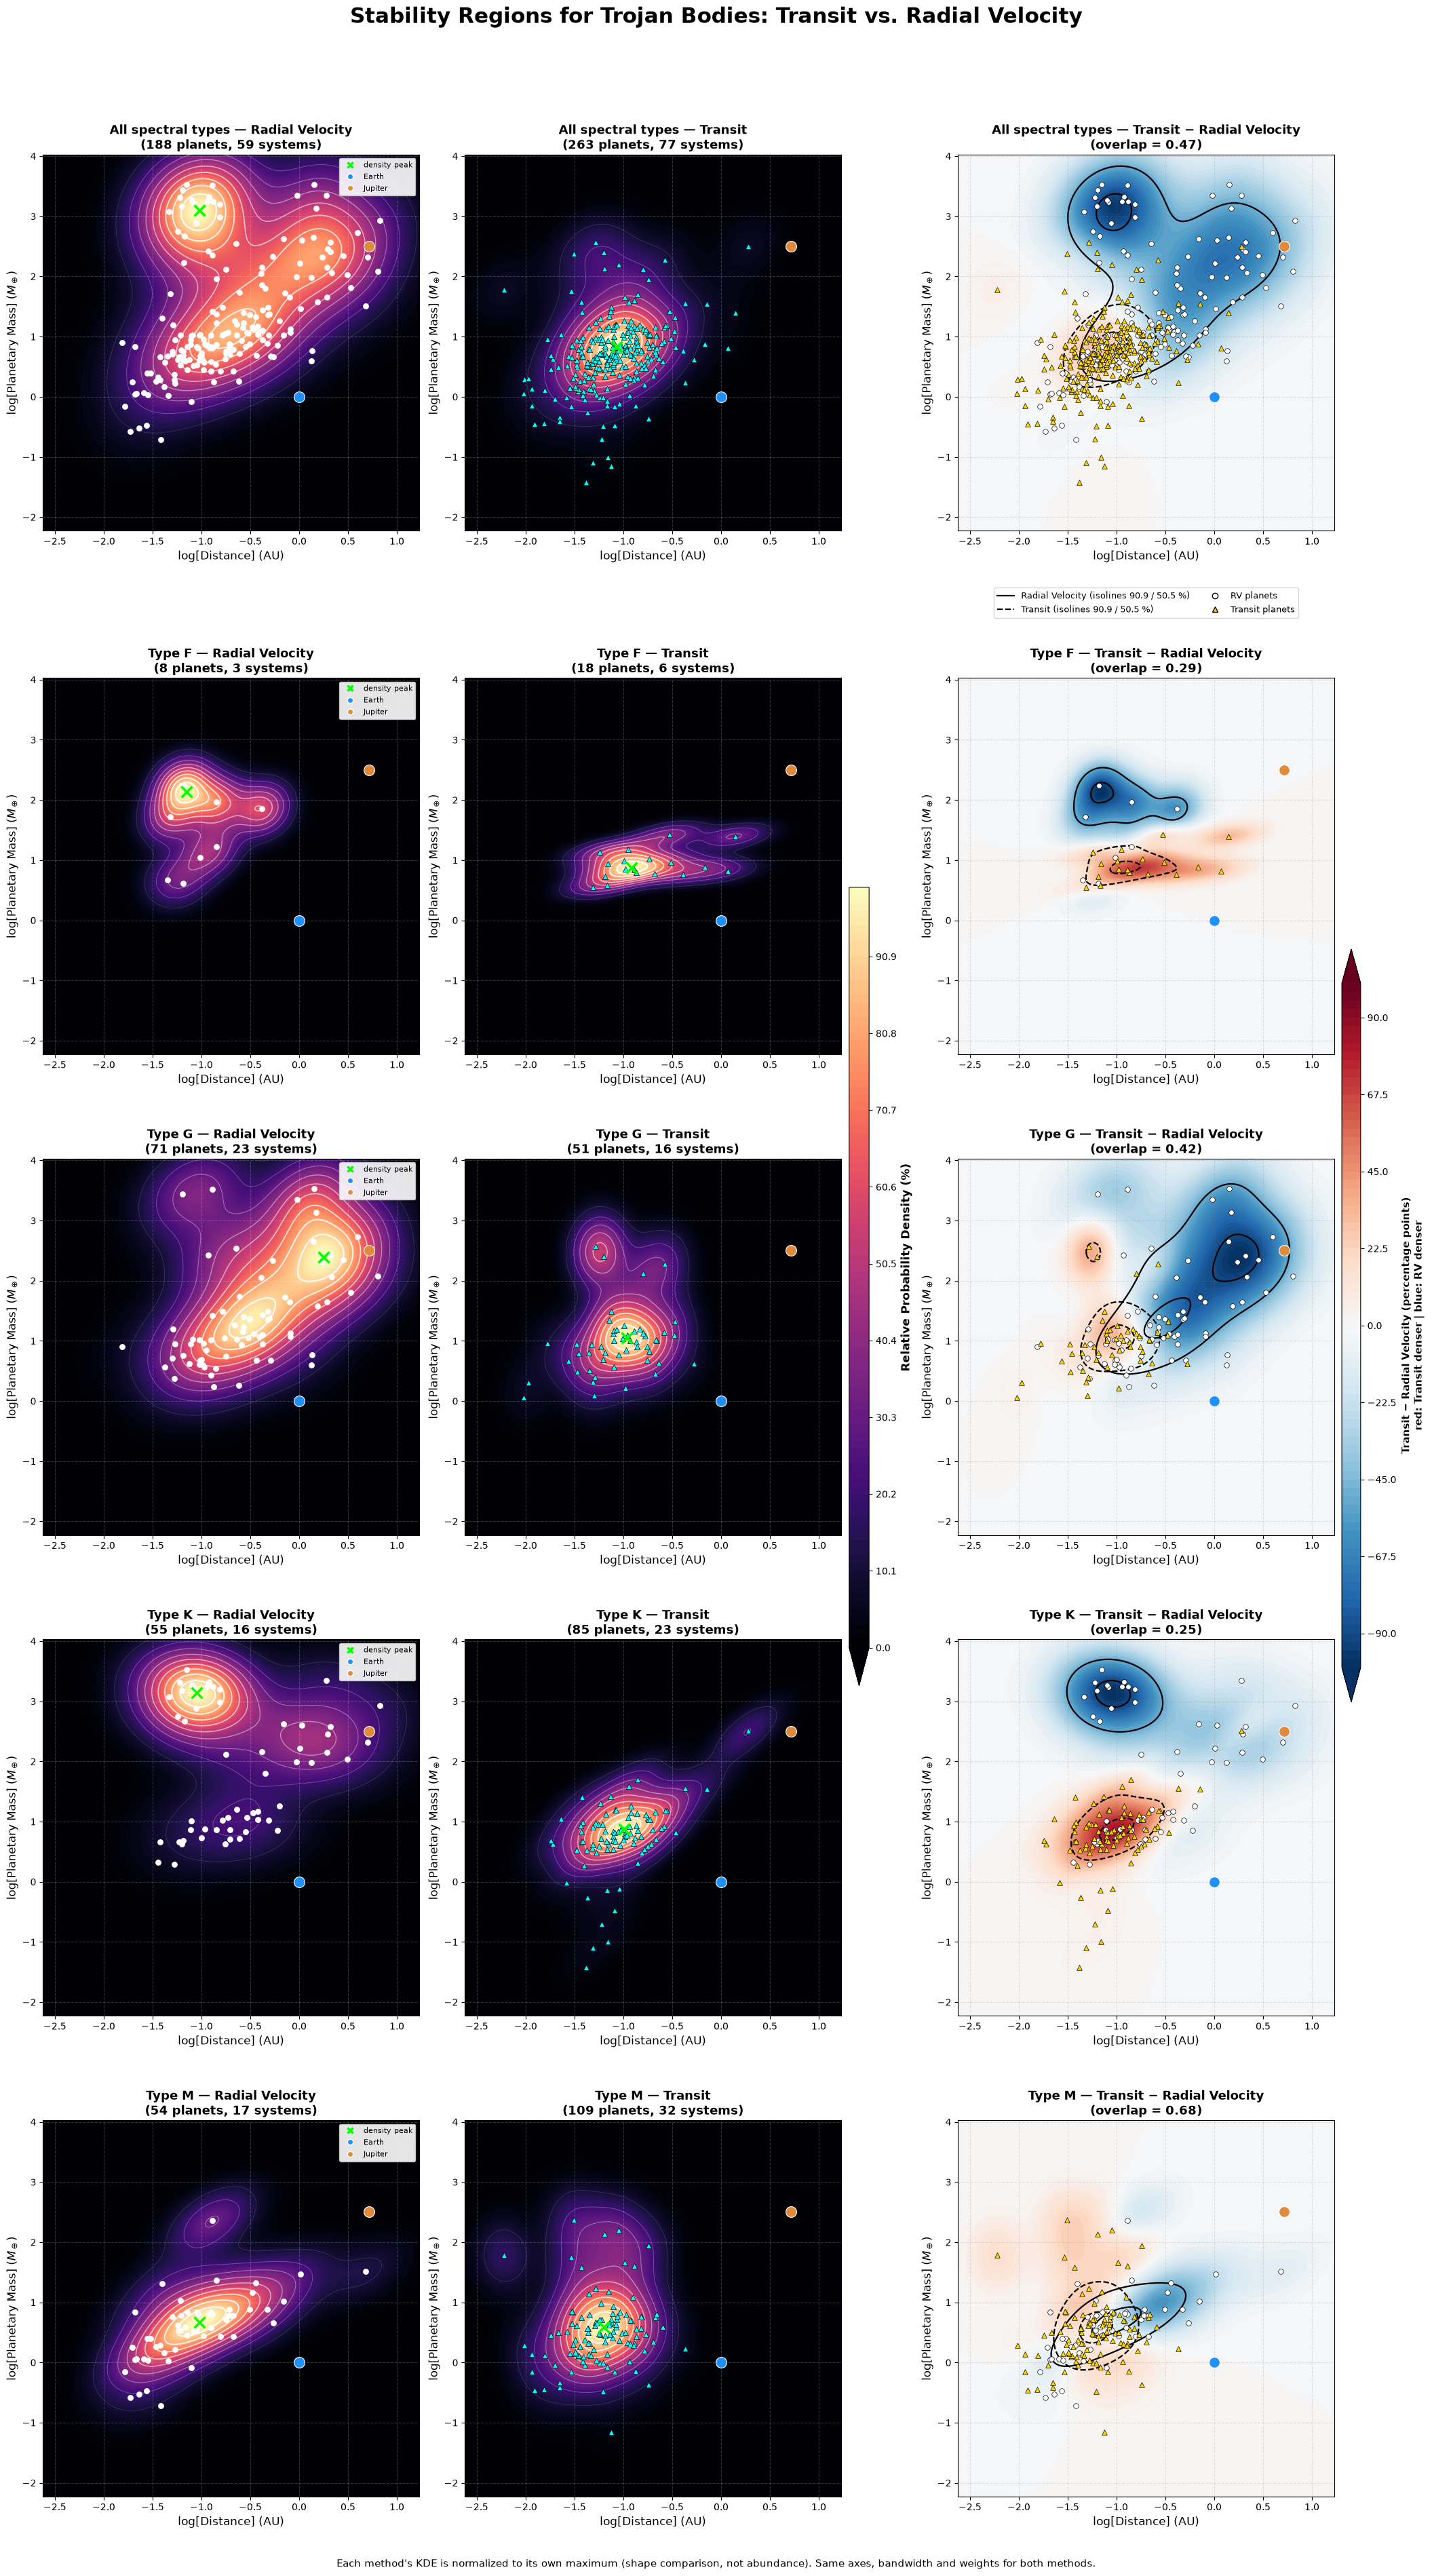


Comparación Transit vs. Radial Velocity:
           Muestra    Pesos  N_planetas_RV  N_planetas_Transit  N_sistemas_RV  N_sistemas_Transit  Solapamiento  Pico_RV_a_UA  Pico_RV_m_Mt  Pico_Transit_a_UA  Pico_Transit_m_Mt
All spectral types fraccion            188                 263             59                  77      0.472833      0.095582   1272.607229           0.084858           6.880502
            Type F fraccion              8                  18              3                   6      0.285060      0.070985    137.749073           0.121268           7.578844
            Type G fraccion             71                  51             23                  16      0.418644      1.764619    246.028730           0.107662          11.156666
            Type K fraccion             55                  85             16                  23      0.250965      0.090060   1401.771553           0.101442           7.578844
            Type M fraccion             54                 109      

In [2]:
ejecutar(("metodos",))

In [3]:
import os
import re
import sys
import math
import pickle
import hashlib
import itertools
import warnings
import contextlib
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.figure import Figure
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.ndimage import maximum_filter, label as _label_cc
from scipy.stats import gaussian_kde
from scipy.interpolate import RegularGridInterpolator
import tkinter as tk
from tkinter import filedialog, simpledialog, messagebox

try:
    from tqdm import tqdm  # pip install tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None, **kwargs):
        """
        Fallback mínimo si la librería 'tqdm' no está instalada: imprime el
        progreso como porcentaje sobre la misma línea de la terminal.
        """
        if total is None:
            try:
                total = len(iterable)
            except TypeError:
                total = None
        prefijo = f"{desc}: " if desc else ""
        for i, item in enumerate(iterable, start=1):
            yield item
            if total:
                pct = 100 * i / total
                print(f"\r{prefijo}{pct:5.1f}% ({i}/{total})", end="", flush=True)
        if total:
            print()

# ---------------------------------------------------------------------------
# PARÁMETROS GLOBALES Y UTILIDADES
# ---------------------------------------------------------------------------
N_BOOTSTRAP_INCERTIDUMBRE = 10000   # número de réplicas bootstrap por panel
BOOTSTRAP_GRID_RES = 250j          # malla del bootstrap

# ---- pesos del KDE ---------------------------------------------------------
#   "area"     : log10(A_estable + 1)
#   "fraccion" : A_est / (A_est + A_inest + A_colisión m2)   <- usa las tres regiones
#   "neto"     : log10(max(A_est - (A_inest + A_col), 0) + 1)
MODO_PESO_DEFECTO = "fraccion"

# ---- incertidumbre 1σ / 2σ / 3σ ---------------------------------------------
SIGMAS = (1, 2, 3)                 # k-sigma que se calculan y exportan a CSV
SIGMAS_DIBUJAR = (1, 2, 3)         # k-sigma que se dibujan como bandas anidadas
# "std": centro ± k·std(réplicas)  |  "percentil": cobertura gaussiana de k·σ
METODO_SIGMA_DIBUJO = "percentil"
ALPHA_BANDA_SIGMA = 0.07           # alpha de cada banda si se dibuja más de una
DIBUJAR_BANDAS_SIGMA = False       # False = sin franjas sombreadas 1σ/2σ/3σ (el bootstrap y los CSV siguen igual)

# ---- regiones de máxima densidad ---------------------------------------------
# Dos islas se consideran la MISMA región solo si están cerca en distancia (x) Y en masa (y):
# las separa un hueco < GAP_REGIONES_DEX en ambos ejes (log10).
GAP_REGIONES_DEX = 0.08
COLOR_LIMITES = "lime"             # color por defecto (verde)
# Color de las líneas a_min / a_max de cada región, en orden de distancia:
# 1ª región = verde, 2ª = roja, 3ª = azul (la 4ª, si existe, magenta)
COLORES_REGIONES = ["lime", "red", "dodgerblue", "magenta"]
# (estilo a_min, estilo a_max) por región; el estilo distingue la región
LS_REGIONES = [("-", "--"),
               ("-.", ":"),
               ((0, (5, 1.5)), (0, (1, 1))),
               ((0, (3, 1, 1, 1, 1, 1)), (0, (5, 5)))]

# ---- robustez de la incertidumbre de las regiones ----------------------------
BOOT_POR_SISTEMAS = True      # remuestrea SISTEMAS completos (los planetas de un sistema no son independientes)
KDE_COV_FIJA = True           # en el bootstrap, el kernel del KDE usa la covarianza del ajuste nominal
                              # (con bw_method escalar el ancho cambia en cada réplica y mete ruido)
METODO_ERROR_REGION = "percentil"   # "percentil": (P84-P16)/2 en log a  |  "std": desviación estándar
MODO_UMBRAL_REGION = "pico"   # "pico": densidad >= NIVEL_REGION_ESTABLE % del máximo
                              # "hdr" : región que encierra MASA_HDR de la probabilidad (no depende del pico)
MASA_HDR = 0.50

# Límites de ejes (log10) de la figura única del Sistema Solar.
# None = automático a partir de los datos. (y = (-2, 2) recortaría Júpiter, log10 M = 2.5)
LIM_SISTEMA_SOLAR_X = (-1.0, 2.0)   # log10(distancia / AU)
MARCA_X_SISTEMA_SOLAR = math.log10(46.0)   # log10(AU) de la región a resaltar: 46 AU (None = sin marca)
LIM_SISTEMA_SOLAR_Y = None          # log10(masa / M_Tierra)

# ---- regiones estables como ISLAS (picos locales) y su incertidumbre ----------
# "picos"  : cada isla de densidad (máximo local >= NIVEL_MIN_PICO %) es una región.
# "umbral" : método anterior (todo >= NIVEL_REGION_ESTABLE % del máximo global).
MODO_REGIONES = "picos"
NIVEL_MIN_PICO = 20.0          # % del máximo global: islas más débiles no se marcan (antes 30; bájalo para marcar más islas)
NIVEL_MIN_PICO_SOLAR = 10.0    # idem, solo en la figura del Sistema Solar (capta la región de ~1.6)
PICO_VENTANA_DEX = 0.4         # un máximo local debe ser el mayor en una ventana de esta anchura (dex)
TOL_ASIGNACION_DEX = 0.5       # bootstrap: tolerancia en log distancia para asignar un tramo a una región nominal
TOL_ASIGNACION_Y_DEX = 1.0     # idem en log masa (la asignación es en el plano a-m, no solo en a)
ERROR_ASIMETRICO = True        # a_min = a (+up / -dn) en UA; evita límites inferiores negativos
# Color de las franjas 1σ/2σ/3σ de cada región (la 1ª blanca; las demás con otro color)
COLORES_BANDAS_REGION = ["white", "cyan", "gold", "orchid"]

# [NUEVO] Umbral de cada isla según la altura de su pico (evita que una isla difusa se "inunde" hacia
# el núcleo más alto y se fusione con él, que era la causa de la región G expandida a ~3.2 AU):
#   True : umbral = nivel de NIVELES_REGIONES inmediatamente inferior a la altura del pico
#          (núcleo 100 % -> 90.9 | segundo pico ~85 % -> 80.8 | ~65 % -> 60.6 ...). Además, si la
#          componente conexa aún contiene el pico de una isla más alta, el umbral se sube hasta separarlas.
#   False: método anterior (NIVEL_REGION_ESTABLE % del pico propio).
NIVELES_POR_ALTURA = True

# [NUEVO] Número de regiones (islas de mayor densidad) por figura. None / no listado = todas las que
# detecte el método. Figura en fila (Spectral Type X):
REGIONES_FILA = {"F": 2,       # isla de ~1 M_Tierra + isla de masas neptunianas
                 "G": 2,       # región principal (90.9 %) + isla cercana a Júpiter
                 "K": 3,
                 "M": 1}       # solo la región acotada al 90.9 %
# Figuras por multiplicidad: (tipo, nº de planetas) -> nº de regiones
REGIONES_MULT = {("F", 3): 3,
                 ("K", 3): 3, ("K", 4): 3, ("K", 5): 1,
                 ("M", 3): 1, ("M", 4): 1, ("M", 5): 1, ("M", 7): 1}

DIBUJAR_ISOLINEAS = True           # isolíneas blancas difuminadas (False = sin isolíneas)

# ---- límites de masa de cada región (líneas horizontales / "cuadrados de masa") ---------------
# Para cada región se dibuja el RECTÁNGULO de la isla: las líneas verticales a_min / a_max (de altura
# completa) y las horizontales m_min / m_max entre a_min y a_max, con un relleno tenue del color de la región.
DIBUJAR_LIMITES_MASA = True
LIMITES_MASA_ANCHO_COMPLETO = False   # False: la línea cubre solo [a_min, a_max]; True: cruza todo el panel
RELLENO_CAJA_MASA = 0.08              # alpha del relleno del rectángulo de cada región (0 = sin relleno)

# ---- salida y ejecución --------------------------------------------------------
SALIDA_CARPETA = "graficos_magma_con_sistemas_azules"

# ---- método de detección -------------------------------------------------------
# Se lee del README de cada planeta ("Método de detección: Radial Velocity" / "Transit").
# nombre canónico -> subcarpeta de salida (cada método tiene sus figuras, CSV y caché propios)
METODOS_DETECCION = {"Radial Velocity": "Radial_Velocity", "Transit": "Transit"}
POR_METODO_DEFECTO = True          # True = figuras separadas por método | False = todos juntos (como antes)
RE_METODO_DETECCION = re.compile(r"M[eé]todo\s+de\s+detecci[oó]n[\s*_`]*:\s*([^\r\n]+)", re.IGNORECASE)
MOSTRAR_FIGURAS = True             # False = solo guarda (útil sin pantalla)

# ---- caché del KDE ------------------------------------------------------------
# El KDE + las regiones + el bootstrap de cada panel se guardan en <salida>/cache_kde/*.pkl.
# La clave del archivo es un hash de los datos del panel y de TODOS los parámetros que afectan
# al resultado: si cambias datos, pesos, ancho de banda, niveles, etc., se recalcula solo.
USAR_CACHE_KDE = True
FORZAR_RECALCULO_KDE = False       # True = ignora la caché y la sobrescribe
CACHE_KDE_NOMBRE = "cache_kde"
SEMILLA_BOOTSTRAP = 12345          # semilla fija -> resultados reproducibles (None = aleatoria)
_CACHE_VERSION = "v4"              # v4: umbral de cada isla por altura del pico + nº de regiones por figura
_CACHE_DIR = None

# ---- leyendas (tamaño y posición) ---------------------------------------------
# fs: fuente | ms: marcadores Tierra/Júpiter | ncol: columnas | y: posición vertical bajo el eje
# fs_cajas: cajas de a_min / a_max sobre el panel
LEYENDA_DEFECTO = {"fs": 9.0, "ms": 7, "ncol": 2, "y": -0.16, "fs_cajas": 8.5}
LEYENDA_POR_TIPO = {                # ajustes por tipo espectral (se suman a LEYENDA_DEFECTO)
    "F": {"fs": 9.5, "ncol": 2, "y": -0.18},
}
LEYENDA_SOLAR = {"fs": 12, "ms": 8, "ncol": 3, "y": -0.15, "fs_cajas": 10}
LEYENDA_COMPARACION_FS = 10.5      # leyenda de la figura Sistema Solar vs. G
ANCHO_PANEL_TIPO = 7.4             # ancho (pulgadas) por panel en plot_figuras_por_tipo
ANCHO_PANEL_MATRIZ = 7.2           # ídem en plot_matriz_tipo_multiplicidad
ANCHO_PANEL_FILA = 7.6             # ídem en plot_tipos_espectrales_fila

# ---- Sistema Solar -----------------------------------------------------------------
# Ya NO se mezcla con las estrellas tipo G: las figuras F, G, K, M se hacen sin él y el
# Sistema Solar tiene su propia figura unificada (etapa "solar").
SISTEMA_SOLAR = {
    "activo": True,
    "preguntar": True,             # True = pregunta con un diálogo si lo incluye
    "tipo_estrella": "G",          # solo se usa en la etapa "comparar" (Sistema Solar vs. G)
    "nombre_sistema": "Solar System",
    "n_planetas_total": 8,
    "marcador": "*", "color": "gold",
    # nombre: (a [UA], masa [M_tierra], A_estable, A_inestable, A_colisión_m2 [km²],
    #          zonas_estables, zonas_inestables, zonas_colisión_m2)   (colisión m1 = 0)
    "planetas": {
        "Mercury": (0.387, 0.0553, 3.01e12, 5.33e14, 2.15e12,  56, 9904, 40),
        "Venus":   (0.723, 0.815,  1.27e13, 1.85e15, 4.29e12,  68, 9909, 23),
        "Earth":   (1.000, 1.000,  2.59e13, 3.57e15, 7.92e12,  72, 9906, 22),
        "Mars":    (1.524, 0.107,  5.16e13, 8.24e15, 2.58e13,  62, 9907, 31),
        "Jupiter": (5.203, 317.8,  6.82e15, 9.00e16, 9.68e12, 704, 9295,  1),
        "Saturn":  (9.537, 95.16,  1.29e16, 3.13e17, 2.61e14, 397, 9595,  8),
        "Uranus":  (19.19, 14.54,  2.03e16, 1.30e18, 1.85e15, 154, 9832, 14),
        "Neptune": (30.07, 17.15,  5.57e16, 3.18e18, 4.53e15, 172, 9814, 14),
    },
}


def _mostrar_o_cerrar(fig):
    if MOSTRAR_FIGURAS:
        plt.show()
    plt.close(fig)


def _safe_log10(x):
    """log10 blindado: retorna log10(x + 1) para evitar log(0) = -inf."""
    return np.log10(np.asarray(x, dtype=float) + 1.0)


def _calcular_pesos(df_sub: pd.DataFrame, modo=None) -> np.ndarray:
    """
    Peso de cada planeta para el KDE, a partir de las áreas del resumen.txt.
      "area"     : log10(A_estable + 1)
      "fraccion" : A_estable / (A_estable + A_inestable + A_colisión_m2)
      "neto"     : log10(max(A_estable - (A_inestable + A_colisión_m2), 0) + 1)
    """
    modo = modo or MODO_PESO_DEFECTO
    est = df_sub["Area_Estable_km2"].to_numpy(dtype=float)
    ine = (df_sub["Area_Inestable"].to_numpy(dtype=float)
           if "Area_Inestable" in df_sub.columns else np.zeros_like(est))
    col = (df_sub["Area_Colision_m2"].to_numpy(dtype=float)
           if "Area_Colision_m2" in df_sub.columns else np.zeros_like(est))
    if modo == "area":
        return _safe_log10(est)
    if modo == "fraccion":
        total = est + ine + col
        return np.divide(est, total, out=np.zeros_like(est), where=total > 0)
    if modo == "neto":
        return _safe_log10(np.clip(est - (ine + col), 0.0, None))
    raise ValueError(f"modo_peso desconocido: {modo!r} (usa 'area', 'fraccion' o 'neto')")


def _pesos_validos(w) -> bool:
    w = np.asarray(w, dtype=float)
    return bool(np.isfinite(w).all() and w.sum() > 0 and np.ptp(w) >= 0)


def _asignar_estilos_sistema(df: pd.DataFrame) -> dict:
    """
    Genera combinaciones únicas de marcador/color para cada sistema estelar.
    Devuelve un dict {nombre_sistema: {'marker': ..., 'color': ...}}.
    El Sistema Solar siempre usa su estilo propio (estrella dorada).
    """
    if "Sistema" not in df.columns:
        df = df.copy()
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    sistemas_unicos = df["Sistema"].unique()
    marcadores_base = ["o", "s", "^", "D", "v", "p", "*", "h",
                       "H", "X", "d", "P", "<", ">"]
    colores_base = plt.cm.tab20.colors
    combinaciones = itertools.product(marcadores_base, colores_base)

    estilos = {}
    for sist, (marker, color) in zip(sistemas_unicos, combinaciones):
        estilos[sist] = {"marker": marker, "color": color}

    ss = SISTEMA_SOLAR
    if ss["activo"] and ss["nombre_sistema"] in estilos:
        estilos[ss["nombre_sistema"]] = {"marker": ss["marcador"], "color": ss["color"]}
    return estilos


def _calcular_limites_criticos(Z_pct: np.ndarray, X: np.ndarray):
    """
    Dado el campo de densidad KDE normalizado en porcentaje (0 a 100%) y su malla X,
    determina los límites críticos de la región más estable (por ejemplo, >= 85% / 90.9%).
    """
    Z_flat = Z_pct.flatten()
    niveles = np.linspace(np.percentile(Z_flat, 10), np.percentile(Z_flat, 98), 25)
    umbral = niveles[-4]
    indices_alta_densidad = np.where(Z_pct >= umbral)
    x_alta_densidad = X[indices_alta_densidad]
    if len(x_alta_densidad) == 0:
        return None, None
    return float(np.min(x_alta_densidad)), float(np.max(x_alta_densidad))


def _bootstrap_limites_criticos(x, y, weights, xlims, ylims,
                                n_bootstrap=None, grid_res=None, rng=None):
    """
    Estima la incertidumbre asociada al modelo (KDE) en la determinación de
    las distancias críticas a_min y a_max mediante bootstrap no paramétrico.
    """
    n_bootstrap = n_bootstrap or N_BOOTSTRAP_INCERTIDUMBRE
    grid_res = grid_res or BOOTSTRAP_GRID_RES
    if rng is None:
        rng = np.random.default_rng()

    n = len(x)
    log_min_boot, log_max_boot = [], []

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    positions_b = np.vstack([Xb.ravel(), Yb.ravel()])

    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap a_min/a_max", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]

        if x_b.var() == 0 or y_b.var() == 0 or w_b.sum() <= 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=0.6)
            Z_b = np.reshape(kde_b(positions_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue

        log_min_b, log_max_b = _calcular_limites_criticos(Z_b, Xb)
        if log_min_b is not None:
            log_min_boot.append(log_min_b)
            log_max_boot.append(log_max_b)

    return log_min_boot, log_max_boot


# ---------------------------------------------------------------------------
# INTERVALOS 1σ / 2σ / 3σ A PARTIR DEL BOOTSTRAP
# ---------------------------------------------------------------------------
def _sigma_log(valores, metodo=None):
    """Incertidumbre de un límite en dex (log10 UA) a partir de sus réplicas bootstrap."""
    v = np.asarray(valores, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5:
        return 0.0
    metodo = metodo or METODO_ERROR_REGION
    if metodo == "std":
        return float(np.std(v))
    p16, p84 = np.percentile(v, [15.865, 84.135])
    return float((p84 - p16) / 2.0)


def _umbral_region(Z_pct, nivel_pico):
    """Umbral de densidad (%) que define la región estable según MODO_UMBRAL_REGION."""
    if MODO_UMBRAL_REGION != "hdr":
        return nivel_pico
    z = np.sort(np.asarray(Z_pct).ravel())[::-1]
    tot = z.sum()
    if tot <= 0:
        return nivel_pico
    i = min(int(np.searchsorted(np.cumsum(z) / tot, MASA_HDR)), z.size - 1)
    return float(z[i])


def _kde_cov_fija(x, y, w, cov, Xb, Yb):
    """KDE gaussiano ponderado con covarianza de kernel FIJA (sin normalizar)."""
    Hi = np.linalg.inv(np.asarray(cov, dtype=float))
    Z = np.zeros_like(Xb)
    for xi, yi, wi in zip(x, y, w):
        if wi <= 0:
            continue
        dx, dy = Xb - xi, Yb - yi
        Z += wi * np.exp(-0.5 * (Hi[0, 0] * dx * dx + 2.0 * Hi[0, 1] * dx * dy + Hi[1, 1] * dy * dy))
    return Z


def _cobertura_gauss(k):
    """Cobertura de una gaussiana en ±kσ: 0.6827, 0.9545, 0.9973 para k = 1, 2, 3."""
    return math.erf(k / math.sqrt(2.0))


def _intervalo_sigma(valores_log, k, central=None, metodo=None):
    """
    Intervalo k-sigma (en log10 UA) de un límite a partir de sus réplicas bootstrap.
      "std"       : central ± k·std(réplicas)
      "percentil" : percentiles de las réplicas con la cobertura gaussiana de k·σ
    Devuelve (inf_log, sup_log) o None si hay menos de 5 réplicas válidas.
    """
    v = np.asarray(valores_log, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5:
        return None
    metodo = metodo or METODO_SIGMA_DIBUJO
    if metodo == "std":
        c = float(np.mean(v)) if central is None else float(central)
        s = float(np.std(v))
        return c - k * s, c + k * s
    cob = _cobertura_gauss(k)
    lo, hi = np.percentile(v, [50.0 * (1.0 - cob), 50.0 * (1.0 + cob)])
    return float(lo), float(hi)


def _dibujar_bandas_sigma(ax, valores_log, central, color, zorder, alpha_unico):
    """Bandas anidadas k-sigma (las más anchas primero). Con un solo k usa alpha_unico.
    Si DIBUJAR_BANDAS_SIGMA es False no dibuja nada (el bootstrap y los CSV no cambian)."""
    if not DIBUJAR_BANDAS_SIGMA:
        return
    ks = sorted(SIGMAS_DIBUJAR, reverse=True)
    alpha = alpha_unico if len(ks) == 1 else ALPHA_BANDA_SIGMA
    for k in ks:
        iv = _intervalo_sigma(valores_log, k, central)
        if iv is not None:
            ax.axvspan(iv[0], iv[1], color=color, alpha=alpha, zorder=zorder, linewidth=0)


def _filas_sigma(contexto: dict, boot: dict, ks=None):
    """
    boot: {nombre_limite: (centro_log10, réplicas_log10)}.
    Devuelve filas en formato largo con los intervalos k-sigma por ambos métodos
    ("std" y "percentil"), para comparar y detectar no-gaussianidad.
    (Los límites de masa "m_min_k"/"m_max_k" se expresan en M_Tierra, no en UA.)
    """
    ks = ks or SIGMAS
    filas = []
    for nombre, (central, vals) in boot.items():
        v = np.asarray(vals, dtype=float)
        v = v[np.isfinite(v)]
        if central is None or v.size < 5:
            continue
        valor_ua = 10 ** central
        sigma_ua = valor_ua * np.log(10) * float(np.std(v))
        for metodo in ("std", "percentil"):
            for k in ks:
                iv = _intervalo_sigma(v, k, central, metodo)
                filas.append({**contexto,
                              "Limite": nombre, "Valor_UA": valor_ua,
                              "Sigma_std_UA": sigma_ua, "N_replicas": int(v.size),
                              "Mediana_UA": 10 ** float(np.median(v)),
                              "Sigma_robusta_UA": valor_ua * np.log(10) * _sigma_log(v, "percentil"),
                              "Metodo": metodo, "k_sigma": k,
                              "Cobertura_%": 100.0 * _cobertura_gauss(k),
                              "Inf_UA": 10 ** iv[0], "Sup_UA": 10 ** iv[1]})
    return filas


def _guardar_tabla_sigma(filas, ruta):
    if not filas:
        return
    pd.DataFrame(filas).to_csv(ruta, index=False, encoding="utf-8-sig")
    print(f"Intervalos σ guardados en: {ruta}")
    n_rep = min(f["N_replicas"] for f in filas)
    if max(SIGMAS) >= 3:
        cola = n_rep * (1 - _cobertura_gauss(3)) / 2
        if cola < 10:
            print(f"   Aviso: con {n_rep} réplicas cada cola de 3σ queda apoyada en ~{cola:.1f} "
                  f"réplicas; el 3σ por percentil es poco fiable. Sube N_BOOTSTRAP_INCERTIDUMBRE "
                  f"a 5000-10000 si lo vas a reportar.")


def _con_sufijo(nombre, sufijo):
    base, ext = os.path.splitext(nombre)
    return f"{base}{sufijo}{ext}"


# ---------------------------------------------------------------------------
# CACHÉ DEL KDE (guardar / cargar resultados en una carpeta local)
# ---------------------------------------------------------------------------
def _set_cache_dir(base_dir):
    """Fija (y crea) la carpeta de caché: <base_dir>/cache_kde. Sin caché => None."""
    global _CACHE_DIR
    if not USAR_CACHE_KDE:
        _CACHE_DIR = None
        return None
    _CACHE_DIR = os.path.join(base_dir, CACHE_KDE_NOMBRE)
    os.makedirs(_CACHE_DIR, exist_ok=True)
    return _CACHE_DIR


def _hash_cache(*partes):
    """Hash estable de arrays y valores simples: identifica un cálculo de KDE."""
    h = hashlib.sha1()
    h.update(_CACHE_VERSION.encode())
    for p in partes:
        if isinstance(p, np.ndarray):
            h.update(np.ascontiguousarray(p).tobytes())
            h.update(str(p.shape).encode())
        else:
            h.update(repr(p).encode())
    return h.hexdigest()[:16]


def _cache_obtener(etiqueta, clave, calcular):
    """
    Si existe <cache>/kde_<etiqueta>_<clave>.pkl lo carga; si no, ejecuta calcular() y lo guarda.
    Con USAR_CACHE_KDE = False (o sin carpeta fijada) simplemente calcula.
    """
    if not USAR_CACHE_KDE or _CACHE_DIR is None:
        return calcular()
    nombre = re.sub(r"[^\w\-]+", "_", str(etiqueta)).strip("_")[:60]
    ruta = os.path.join(_CACHE_DIR, f"kde_{nombre}_{clave}.pkl")
    if os.path.exists(ruta) and not FORZAR_RECALCULO_KDE:
        try:
            with open(ruta, "rb") as f:
                res = pickle.load(f)
            print(f"   ✔ KDE cargado desde caché: {os.path.basename(ruta)}")
            return res
        except Exception as e:
            print(f"   ⚠ Caché ilegible ({e}); se recalcula.")
    res = calcular()
    try:
        with open(ruta, "wb") as f:
            pickle.dump(res, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f"   💾 KDE guardado en caché: {os.path.basename(ruta)}")
    except Exception as e:
        print(f"   ⚠ No se pudo guardar la caché ({e}).")
    return res


In [4]:
def plot_islands_por_tipo_estrella(df: pd.DataFrame, base_dir: str,
                                   tipos=("F", "G", "K", "M"), cmap: str = "magma",
                                   color_rocoso="brown", color_neptuniano="purple",
                                   modo_peso=None):
    """
    Genera el gráfico 2x2 con un panel por cada tipo espectral ("All systems — Type X").
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map by stellar type for: {metrica} [weights: {modo_peso}]...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map by stellar type.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    num_paneles = len(tipos)
    ncols = 2 if num_paneles > 1 else 1
    nrows = math.ceil(num_paneles / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(17.0, 11.5 * nrows), squeeze=False)
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Stellar Type",
                 fontsize=26, fontweight="bold", y=0.99)

    axes_flat = axes.flatten()

    tareas_paneles = [
        (i, axes_flat[i], df_f[df_f["Tipo_Estrella"] == tipo].copy(), f"All systems — Type {tipo}", tipo)
        for i, tipo in enumerate(tipos)
    ]

    filas_sigma = []
    for i, ax, df_subset, titulo, tipo in tqdm(tareas_paneles, desc="Generando paneles por tipo", unit="panel"):
        r_p = _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=True,
            color_rocoso=color_rocoso, color_neptuniano=color_neptuniano,
            modo_peso=modo_peso
        )
        filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": "todos"}, r_p["boot"])

    for idx in range(num_paneles, len(axes_flat)):
        axes_flat[idx].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    if nrows > 1:
        plt.subplots_adjust(hspace=0.65, wspace=0.28)

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella_{modo_peso}.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_por_tipo_{modo_peso}.csv"))


# ---------------------------------------------------------------------------
# 3. FUNCIÓN: GRÁFICO HORIZONTAL POR MULTIPLICIDAD GENERAL
# ---------------------------------------------------------------------------
def plot_islands_zonas_estables2(df: pd.DataFrame, base_dir: str, cmap: str = "magma",
                                 modo_peso=None):
    """
    Gráfico general horizontal por multiplicidad (sin separar por tipo estelar),
    con densidad normalizada (0 a 100%) y todos los sistemas en la leyenda.
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map for: {metrica} [weights: {modo_peso}]...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    estilos_sistema = _asignar_estilos_sistema(df)
    df_f = df[df[metrica] > 0].copy()

    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map.")
        return

    pnums_unicos = sorted(df_f["Num_Planetas"].unique())
    num_paneles = len(pnums_unicos) + 1

    fig, axes = plt.subplots(1, num_paneles, figsize=(7.8 * num_paneles, 10.0))
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Multiplicity",
                 fontsize=26, fontweight="bold", y=0.99)

    if num_paneles == 1:
        axes = [axes]

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]

    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    tareas_paneles = [(axes[0], df_f, "Global View: All systems", True)]
    for i, pnum in enumerate(pnums_unicos):
        df_sub = df_f[df_f["Num_Planetas"] == pnum].copy()
        tareas_paneles.append((axes[i + 1], df_sub, f"Systems with {pnum} planets", True))

    for ax, df_subset, titulo, mostrar_sist in tqdm(tareas_paneles, desc="Generando paneles", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=mostrar_sist,
            color_rocoso="brown", color_neptuniano="purple", modo_peso=modo_peso
        )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal_{modo_peso}.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)


# ---------------------------------------------------------------------------
# PARÁMETROS DE LOS PANELES COMPACTOS
# ---------------------------------------------------------------------------
JUPITER_UA, JUPITER_MASA = 5.2, 317.8
COLOR_TIERRA = "#1e90ff"
COLOR_JUPITER = "#e08a3c"

# Región más estable (líneas de región a_min / a_max): densidad relativa >= 90.9 %
NIVEL_REGION_ESTABLE = 90.9

# Zoom por tipo espectral en plot_figuras_por_tipo: {tipo: (margen_x, margen_y)} en dex.
# Para quitar el zoom: ZOOM_POR_TIPO = {}
ZOOM_POR_TIPO = {"F": (0.6, 0.8)}

# ISOLÍNEAS DIFUMINADAS: se desvanecen (menor opacidad y grosor) lejos del centro.
NIVELES_REGIONES = (90.9, 80.8, 70.7, 60.6, 50.5, 40.4, 30.3, 20.2, 10.1)
ALPHA_CENTRO, ALPHA_BORDE = 0.95, 0.15
LW_CENTRO, LW_BORDE = 1.6, 0.6


def _dibujar_isolineas_difuminadas(ax, X, Y, Z_pct, niveles=NIVELES_REGIONES,
                                   color="white"):
    """
    Dibuja una isolínea por nivel de densidad relativa (%). El nivel más alto
    (centro) es el más nítido y los niveles bajos se van desvaneciendo.
    """
    n = len(niveles)
    zmin, zmax = float(Z_pct.min()), float(Z_pct.max())
    for k, nv in enumerate(sorted(niveles, reverse=True)):
        if not (zmin < nv < zmax):
            continue
        t = k / (n - 1) if n > 1 else 0.0
        alpha = ALPHA_CENTRO + (ALPHA_BORDE - ALPHA_CENTRO) * t
        lw = LW_CENTRO + (LW_BORDE - LW_CENTRO) * t
        ax.contour(X, Y, Z_pct, levels=[nv], colors=[color],
                   linewidths=lw, alpha=alpha, zorder=4)


def _limites_por_nivel(Z_pct: np.ndarray, X: np.ndarray, nivel: float):
    """Mínimo y máximo de log(distancia) donde la densidad relativa >= nivel (%)."""
    xs = X[Z_pct >= nivel]
    if xs.size == 0:
        return None, None
    return float(xs.min()), float(xs.max())


def _regiones_por_umbral(Z_pct, X, umbral, gap_dex=None):
    """
    Tramos de log10(distancia) donde la densidad relativa >= umbral.
    Si la región de alta densidad se parte en dos (o más) tramos separados por un hueco
    de al menos gap_dex, se devuelven como regiones distintas: [(lo1, hi1), (lo2, hi2), ...].
    (Método "umbral": solo distancia; devuelve tuplas de 2 elementos.)
    """
    gap_dex = GAP_REGIONES_DEX if gap_dex is None else gap_dex
    xs = X[:, 0]
    cols = np.where((Z_pct >= umbral).any(axis=1))[0]
    if cols.size == 0:
        return []
    regiones = []
    ini = prev = cols[0]
    for i in cols[1:]:
        if (xs[i] - xs[prev]) > gap_dex + 1e-12:
            regiones.append((float(xs[ini]), float(xs[prev])))
            ini = i
        prev = i
    regiones.append((float(xs[ini]), float(xs[prev])))
    return regiones


def _fusionar_islas(tramos, gap_dex):
    """
    Fusiona islas SOLO si están cerca en distancia (x) Y en masa (y).
    Cada tramo: [lo, hi, ylo, yhi, ypico, zpico]. Dos islas con el mismo rango de distancia pero
    en masas distintas (p. ej. F: isla principal e isla cercana a gigantes gaseosos) NO se fusionan.
    """
    fusion = [list(t) for t in tramos]
    cambio = True
    while cambio:
        cambio = False
        for i, j in itertools.combinations(range(len(fusion)), 2):
            a, b = fusion[i], fusion[j]
            gx = max(a[0], b[0]) - min(a[1], b[1])      # < 0 si se solapan en x
            gy = max(a[2], b[2]) - min(a[3], b[3])      # < 0 si se solapan en y
            if gx <= gap_dex and gy <= gap_dex:
                fusion[i] = [min(a[0], b[0]), max(a[1], b[1]),
                             min(a[2], b[2]), max(a[3], b[3]),
                             a[4] if a[5] >= b[5] else b[4], max(a[5], b[5])]
                del fusion[j]
                cambio = True
                break
    return fusion


def _nivel_isla(h):
    """Mayor nivel de NIVELES_REGIONES que no supera la altura h (% del máximo global)."""
    for nv in sorted(NIVELES_REGIONES, reverse=True):
        if nv <= h + 1e-9:
            return float(nv)
    return float(min(NIVELES_REGIONES))


def _regiones_por_picos(Z_pct, X, Y, nivel_local=None, nivel_min=None, gap_dex=None, n_max=None):
    """
    Regiones estables como ISLAS de densidad. Para cada máximo local con Z >= nivel_min (%):
      - umbral = nivel de NIVELES_REGIONES inmediatamente inferior a la altura del pico
        (NIVELES_POR_ALTURA = True) o nivel_local % del pico propio (modo anterior);
      - isla = componente conexa de {Z >= umbral} que contiene al pico; si esa componente llegara
        a contener el pico de una isla MÁS ALTA (se "inundó" hacia ella) el umbral se sube hasta
        separarlas. Así una isla difusa (p. ej. cerca de Júpiter en G) no se expande sobre el núcleo.
    n_max: se conservan solo las n_max islas más altas (None = todas).
    Devuelve, ordenadas por distancia, tuplas (lo, hi, ylo, yhi, ypico): extensión en log10(distancia)
    y en log10(masa) de cada isla. Islas distintas no se fusionan aunque compartan rango de
    distancia (ver _fusionar_islas).
    """
    nivel_local = NIVEL_REGION_ESTABLE if nivel_local is None else nivel_local
    nivel_min = NIVEL_MIN_PICO if nivel_min is None else nivel_min
    gap_dex = GAP_REGIONES_DEX if gap_dex is None else gap_dex
    paso = float(abs(X[1, 0] - X[0, 0])) or 1e-3
    ventana = max(3, int(round(PICO_VENTANA_DEX / paso)))
    es_pico = (Z_pct == maximum_filter(Z_pct, size=ventana, mode="nearest")) & (Z_pct >= nivel_min)
    ij = np.argwhere(es_pico)
    if ij.size == 0:
        return []
    ij = ij[np.argsort(-Z_pct[ij[:, 0], ij[:, 1]])]
    cubiertos = np.zeros(Z_pct.shape, dtype=bool)
    picos_previos = []
    tramos = []
    for i, j in ij:
        if n_max is not None and len(tramos) >= n_max:
            break
        if cubiertos[i, j]:
            continue
        h = float(Z_pct[i, j])
        t = _nivel_isla(h) if NIVELES_POR_ALTURA else (nivel_local / 100.0) * h
        while True:
            lab, _n = _label_cc(Z_pct >= t)
            comp = lab == lab[i, j]
            if t >= h or not any(comp[p] for p in picos_previos):
                break
            t = min(t + 0.25, h)          # separar de la isla más alta
        cubiertos |= comp
        picos_previos.append((int(i), int(j)))
        xs, ys = X[comp], Y[comp]
        tramos.append([float(xs.min()), float(xs.max()), float(ys.min()), float(ys.max()),
                       float(Y[i, j]), h])
    fusion = _fusionar_islas(tramos, gap_dex)
    fusion.sort(key=lambda t: (t[0], t[2]))
    return [tuple(t[:5]) for t in fusion]


def _error_asimetrico(valor_ua, replicas_log):
    """(dn, up) en UA (o M_Tierra si es una masa) a partir de las réplicas bootstrap (log10); ambos >= 0.
    Con METODO_ERROR_REGION = "percentil" los percentiles 15.9 / 84.1 se miden respecto a la MEDIANA de
    las réplicas (antes respecto al valor nominal: si este caía fuera del intervalo, un lado daba 0)."""
    v = np.asarray(replicas_log, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5 or valor_ua <= 0:
        return 0.0, 0.0
    if METODO_ERROR_REGION == "std":
        la = np.log10(valor_ua)
        sg = float(np.std(v))
        lo, hi = la - sg, la + sg
        return max(0.0, valor_ua - 10 ** lo), max(0.0, 10 ** hi - valor_ua)
    lo, med, hi = np.percentile(v, [15.865, 50.0, 84.135])
    return max(0.0, 10 ** med - 10 ** lo), max(0.0, 10 ** hi - 10 ** med)


def _txt_lim(nombre, a, dn, up):
    """Etiqueta de un límite: a (+up/-dn) AU, o a ± σ AU si ERROR_ASIMETRICO = False."""
    if dn <= 0 and up <= 0:
        return f"$a_{{{nombre}}}$ = {a:.3f} AU"
    if ERROR_ASIMETRICO:
        return f"$a_{{{nombre}}}$ = ${a:.3f}^{{+{up:.3f}}}_{{-{dn:.3f}}}$ AU"
    return f"$a_{{{nombre}}}$ = {a:.3f} $\\pm$ {(dn + up) / 2:.3f} AU"


# ---------------------------------------------------------------------------
# LÍMITES EN MASA DE CADA REGIÓN
# ---------------------------------------------------------------------------
def _limites_masa_region(Z_pct, X, Y, lo, hi):
    """
    (Solo para el modo "umbral" o tramos sin información de masa.)
    Extensión en log10(masa) de la isla de densidad cuya distancia está en [lo, hi].
    Mismo criterio que las regiones en distancia: Z >= NIVEL_REGION_ESTABLE % del pico
    de la isla ("picos") o del máximo global ("umbral").
    Devuelve (ymin, ymax, y_del_pico) o None.
    En modo "picos" los límites de masa vienen directamente de la componente conexa de cada isla.
    """
    banda = (X >= lo - 1e-9) & (X <= hi + 1e-9)
    if not banda.any():
        return None
    zb = np.where(banda, Z_pct, -np.inf)
    pico = float(zb.max())
    ref = pico if MODO_REGIONES == "picos" else 100.0
    mask = banda & (Z_pct >= NIVEL_REGION_ESTABLE / 100.0 * ref)
    if not mask.any():
        return None
    ys = Y[mask]
    y_pico = float(Y[np.unravel_index(np.argmax(zb), zb.shape)])
    return float(ys.min()), float(ys.max()), y_pico


def _masa_region_nominal(malla, lmin, lmax):
    """(log m_min, log m_max) de la región con distancia en [lmin, lmax], desde la malla guardada.
    (Ya no se usa al dibujar: las masas de cada isla vienen en el resultado de calcular_kde_panel.)"""
    X, Y, Z = malla
    m = _limites_masa_region(Z, X, Y, lmin, lmax)
    return None if m is None else (m[0], m[1])


def _txt_masa(nombre, m, dn=None, up=None):
    """Etiqueta de un límite de masa: m (+up/-dn) M_Tierra (sin error si no hay réplicas)."""
    if dn is None or up is None or (dn <= 0 and up <= 0):
        return f"$m_{{{nombre}}}$ = {m:.2f} $M_\\oplus$"
    return f"$m_{{{nombre}}}$ = ${m:.2f}^{{+{up:.2f}}}_{{-{dn:.2f}}}$ $M_\\oplus$"


def _region_principal(regs, malla):
    """
    Región que contiene el máximo global de densidad (la "principal"). Si ninguna lo contiene,
    la más cercana en distancia. Las cajas sobre el panel muestran a_min / a_max de ESTA región,
    no el a_min de la primera y el a_max de la última (que mezclaba regiones distintas).
    """
    if not regs:
        return None
    if malla is None:
        return regs[0]
    X, Y, Z = malla
    i, j = np.unravel_index(np.argmax(Z), Z.shape)
    px, py = float(X[i, j]), float(Y[i, j])
    for r in regs:
        if r["lmin"] - 1e-9 <= px <= r["lmax"] + 1e-9:
            if r.get("m_min") is None or (math.log10(r["m_min"]) - 1e-9 <= py
                                          <= math.log10(r["m_max"]) + 1e-9):
                return r
    return min(regs, key=lambda r: abs((r["lmin"] + r["lmax"]) / 2.0 - px))


def _centro_tramo(t):
    """Centro (log a, log m) de un tramo; log m = None si el tramo solo trae distancia (modo umbral)."""
    cx = (t[0] + t[1]) / 2.0
    cy = (t[2] + t[3]) / 2.0 if len(t) >= 5 else None
    return cx, cy


def _dist_norm(c, c0):
    """Distancia normalizada entre dos centros: 1.0 = borde de la elipse de tolerancia."""
    d = abs(c[0] - c0[0]) / TOL_ASIGNACION_DEX
    if c[1] is not None and c0[1] is not None:
        d = math.hypot(d, (c[1] - c0[1]) / TOL_ASIGNACION_Y_DEX)
    return d


def _bootstrap_regiones(x, y, weights, xlims, ylims, umbral, regiones_nom,
                        n_bootstrap=None, grid_res=None, rng=None, bw=0.55,
                        grupos=None, cov=None, buscador=None):
    """
    Bootstrap de los bordes de CADA región nominal (distancia y masa). En cada réplica se recalculan
    los tramos y cada uno se asigna a la región nominal más cercana EN EL PLANO (log a, log m);
    si queda fuera de la elipse de tolerancia se descarta (si varios tramos caen en la misma
    región se fusionan). Devuelve una lista, una entrada por región nominal:
    {"min": [...], "max": [...], "ymin": [...], "ymax": [...]}  (log10;
    "min"/"max" en UA y "ymin"/"ymax" en M_Tierra).
      grupos : etiqueta de sistema de cada planeta -> se remuestrean SISTEMAS completos.
      buscador : callable(Z_pct, X, Y) -> [tramos]; por defecto el umbral global.
      cov    : covarianza del kernel del ajuste nominal -> ancho de banda fijo en todas las
               réplicas (si KDE_COV_FIJA). Sin ella se usa gaussian_kde(bw_method=bw).
    """
    n_bootstrap = n_bootstrap or N_BOOTSTRAP_INCERTIDUMBRE
    grid_res = grid_res or BOOTSTRAP_GRID_RES
    if rng is None:
        rng = np.random.default_rng()
    n = len(x)
    out = [{"min": [], "max": [], "ymin": [], "ymax": []} for _ in regiones_nom]
    centros = [_centro_tramo(t) for t in regiones_nom]

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    pos_b = np.vstack([Xb.ravel(), Yb.ravel()])
    usar_cov = bool(KDE_COV_FIJA and cov is not None)

    miembros = None
    if grupos is not None:
        _, inv = np.unique(np.asarray(grupos).astype(str), return_inverse=True)
        miembros = [np.where(inv == g)[0] for g in range(inv.max() + 1)]
        if len(miembros) < 3:
            miembros = None

    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap regiones", leave=False, unit="rep"):
        if miembros is not None:
            sel = rng.integers(0, len(miembros), size=len(miembros))
            idx = np.concatenate([miembros[s] for s in sel])
        else:
            idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]
        if x_b.var() == 0 or y_b.var() == 0 or w_b.sum() <= 0:
            continue
        try:
            if usar_cov:
                mult = np.bincount(idx, minlength=n)
                Z_b = _kde_cov_fija(x, y, weights * mult, cov, Xb, Yb)
            else:
                kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=bw)
                Z_b = np.reshape(kde_b(pos_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue

        if buscador is not None:
            tramos = buscador(Z_b, Xb, Yb)
        else:
            tramos = _regiones_por_umbral(Z_b, Xb, _umbral_region(Z_b, umbral))
        asign = {}
        for t in tramos:
            c = _centro_tramo(t)
            dist = [_dist_norm(c, c0) for c0 in centros]
            k = int(np.argmin(dist))
            if buscador is not None and dist[k] > 1.0:
                continue          # tramo que no corresponde a ninguna región nominal
            lo, hi = t[0], t[1]
            ylo, yhi = (t[2], t[3]) if len(t) >= 5 else (None, None)
            if k in asign:
                a = asign[k]
                con_y = a[2] is not None and ylo is not None
                asign[k] = (min(a[0], lo), max(a[1], hi),
                            min(a[2], ylo) if con_y else None,
                            max(a[3], yhi) if con_y else None)
            else:
                asign[k] = (lo, hi, ylo, yhi)
        for k, (lo, hi, ylo, yhi) in asign.items():
            out[k]["min"].append(lo)
            out[k]["max"].append(hi)
            if ylo is None:           # modo umbral: masa por banda en x
                m = _limites_masa_region(Z_b, Xb, Yb, lo, hi)
                if m is None:
                    continue
                ylo, yhi = m[0], m[1]
            out[k]["ymin"].append(ylo)
            out[k]["ymax"].append(yhi)
    return out


# ===========================================================================
# CAPA 1 — CÁLCULO (KDE + regiones + bootstrap), con caché en disco
#          No dibuja nada: devuelve un dict serializable.
# ===========================================================================

In [5]:
def calcular_kde_panel(df_subset, xlims, ylims, modo_peso=None, n_bootstrap=None,
                       nivel_min_pico=None, etiqueta="panel", n_regiones=None):
    """
    Calcula todo lo que necesita un panel y lo guarda en la caché (<salida>/cache_kde/).
    Si ya existe un resultado con los mismos datos y parámetros, lo carga sin recalcular.
    n_regiones: None = todas las islas detectadas; N = solo las N de mayor densidad
    (ver REGIONES_FILA / REGIONES_MULT; solo aplica con MODO_REGIONES = "picos").

    Devuelve un dict:
      "malla"    : (X, Y, Z_pct) o None
      "regiones" : [{"region", "lmin", "lmax", "a_min", "a_max", "s_min", "s_max",
                     "dn_min", "up_min", "dn_max", "up_max",
                     "m_min", "m_max", "m_pico", "dnm_min", "upm_min", "dnm_max", "upm_max",
                     "m_min_en_borde", "m_max_en_borde"}, ...]     (masas en M_Tierra)
      "boot"     : {"a_min_k": (centro_log, réplicas), "a_max_k": (...),
                    "m_min_k": (...), "m_max_k": (...), ...}
    """
    modo = modo_peso or MODO_PESO_DEFECTO
    nb = n_bootstrap or N_BOOTSTRAP_INCERTIDUMBRE
    nmp = NIVEL_MIN_PICO if nivel_min_pico is None else nivel_min_pico
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()
    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = _calcular_pesos(df_valid, modo)
    grupos = (np.asarray(df_valid["Sistema"].to_numpy(), dtype=str)
              if BOOT_POR_SISTEMAS and "Sistema" in df_valid.columns else None)

    clave = _hash_cache(
        x, y, weights, tuple(float(v) for v in xlims), tuple(float(v) for v in ylims),
        modo, nb, nmp, MODO_REGIONES, NIVEL_REGION_ESTABLE, PICO_VENTANA_DEX,
        GAP_REGIONES_DEX, TOL_ASIGNACION_DEX, TOL_ASIGNACION_Y_DEX, MODO_UMBRAL_REGION,
        MASA_HDR, KDE_COV_FIJA,
        BOOT_POR_SISTEMAS, METODO_ERROR_REGION, repr(BOOTSTRAP_GRID_RES), SEMILLA_BOOTSTRAP,
        NIVELES_POR_ALTURA, tuple(NIVELES_REGIONES), n_regiones,
        grupos if grupos is not None else "sin_grupos")

    def _calc():
        res = {"malla": None, "regiones": [], "boot": {}}
        if not (len(df_valid) >= 3 and x.var() > 0 and y.var() > 0
                and np.isfinite(weights).all() and weights.sum() > 0):
            return res
        try:
            kde = gaussian_kde(np.vstack([x, y]), weights=weights, bw_method=0.55)
            X, Y = np.mgrid[xlims[0]:xlims[1]:150j, ylims[0]:ylims[1]:150j]
            Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])).T, X.shape)
            Z_pct = (Z / Z.max()) * 100.0 if Z.max() > 0 else Z
            res["malla"] = (X, Y, Z_pct)

            if MODO_REGIONES == "picos":
                buscador = lambda Zg, Xg, Yg: _regiones_por_picos(
                    Zg, Xg, Yg, nivel_min=nmp, n_max=n_regiones)
            else:
                buscador = lambda Zg, Xg, Yg: _regiones_por_umbral(
                    Zg, Xg, _umbral_region(Zg, NIVEL_REGION_ESTABLE))
            regs = buscador(Z_pct, X, Y)
            if regs:
                boot_reg = _bootstrap_regiones(
                    x, y, weights, xlims, ylims, NIVEL_REGION_ESTABLE, regs,
                    n_bootstrap=nb, rng=np.random.default_rng(SEMILLA_BOOTSTRAP),
                    grupos=grupos, cov=np.asarray(kde.covariance), buscador=buscador)
                for k, t in enumerate(regs, start=1):
                    lmin, lmax = t[0], t[1]
                    bmin, bmax = boot_reg[k - 1]["min"], boot_reg[k - 1]["max"]
                    a_min, a_max = 10 ** lmin, 10 ** lmax
                    dn_min, up_min = _error_asimetrico(a_min, bmin)
                    dn_max, up_max = _error_asimetrico(a_max, bmax)
                    res["boot"][f"a_min_{k}"] = (lmin, bmin)
                    res["boot"][f"a_max_{k}"] = (lmax, bmax)

                    # --- límites en masa de la región (nominal + bootstrap) ---
                    # En modo "picos" vienen de la propia isla (t[2], t[3], t[4]);
                    # en modo "umbral" se calculan por banda en distancia.
                    extra = {}
                    mm = (t[2], t[3], t[4]) if len(t) >= 5 \
                        else _limites_masa_region(Z_pct, X, Y, lmin, lmax)
                    if mm is not None:
                        m_min, m_max = 10 ** mm[0], 10 ** mm[1]
                        bym, byM = boot_reg[k - 1]["ymin"], boot_reg[k - 1]["ymax"]
                        dnm_min, upm_min = _error_asimetrico(m_min, bym)
                        dnm_max, upm_max = _error_asimetrico(m_max, byM)
                        res["boot"][f"m_min_{k}"] = (mm[0], bym)
                        res["boot"][f"m_max_{k}"] = (mm[1], byM)
                        extra = {"m_min": m_min, "m_max": m_max, "m_pico": 10 ** mm[2],
                                 "dnm_min": dnm_min, "upm_min": upm_min,
                                 "dnm_max": dnm_max, "upm_max": upm_max,
                                 "m_min_en_borde": bool(mm[0] <= ylims[0] + 0.03),
                                 "m_max_en_borde": bool(mm[1] >= ylims[1] - 0.03)}

                    res["regiones"].append({
                        "region": k, "lmin": lmin, "lmax": lmax,
                        "a_min": a_min, "a_max": a_max,
                        "s_min": (dn_min + up_min) / 2.0, "s_max": (dn_max + up_max) / 2.0,
                        "dn_min": dn_min, "up_min": up_min,
                        "dn_max": dn_max, "up_max": up_max, **extra})
        except (np.linalg.LinAlgError, ValueError):
            pass
        return res

    return _cache_obtener(etiqueta, clave, _calc)


# ===========================================================================
# CAPA 2 — DISEÑO (solo dibuja a partir del resultado de la capa 1)
#          No calcula ningún KDE ni bootstrap.
# ===========================================================================
def dibujar_panel_kde(ax, df_subset, res, titulo, estilos_sistema, xlims, ylims,
                      cmap="magma", mostrar_ylabel=True, lineas_extra=None, leyenda=None):
    """
    Dibuja un panel compacto con los resultados `res` de calcular_kde_panel:
    mapa de densidad + isolíneas difuminadas, líneas de a_min / a_max por región (verticales, de altura
    completa), RECTÁNGULO de masas de cada región (líneas horizontales m_min / m_max entre a_min y
    a_max + relleno tenue), cajas con los valores de la región principal, puntos por sistema,
    Tierra y Júpiter y una leyenda debajo.
    `leyenda` es un dict como LEYENDA_DEFECTO (fs, ms, ncol, y, fs_cajas).
    """
    cfg = {**LEYENDA_DEFECTO, **(leyenda or {})}
    ax.set_facecolor("black")
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()

    # ---------------- Mapa de densidad ----------------
    if res["malla"] is not None:
        X, Y, Z_pct = res["malla"]
        ax.contourf(X, Y, Z_pct, levels=np.linspace(0.0, 100.0, 100),
                    cmap=cmap, extend="min", zorder=1)
        if DIBUJAR_ISOLINEAS:
            _dibujar_isolineas_difuminadas(ax, X, Y, Z_pct)

    # ---------------- Regiones (líneas a_min / a_max y m_min / m_max) ----------------
    regs, boot = res["regiones"], res["boot"]
    multi = len(regs) > 1
    handles_lim = []
    handles_masa = []
    for r in regs:
        k = r["region"]
        ls_min, ls_max = LS_REGIONES[(k - 1) % len(LS_REGIONES)]
        col_banda = COLORES_BANDAS_REGION[(k - 1) % len(COLORES_BANDAS_REGION)]
        col_reg = COLORES_REGIONES[(k - 1) % len(COLORES_REGIONES)]
        for lval, nom, ls in ((r["lmin"], "a_min", ls_min), (r["lmax"], "a_max", ls_max)):
            _dibujar_bandas_sigma(ax, boot[f"{nom}_{k}"][1], lval, col_banda, 3, 0.15)
            ax.axvline(lval, color=col_reg, linestyle=ls, linewidth=1.6, zorder=6)

        # límites en masa (líneas horizontales) de la propia isla: cierran el rectángulo de la región
        mm = ((math.log10(r["m_min"]), math.log10(r["m_max"]))
              if (DIBUJAR_LIMITES_MASA and r.get("m_min") is not None) else None)
        if mm is not None:
            if RELLENO_CAJA_MASA > 0 and not LIMITES_MASA_ANCHO_COMPLETO:
                ax.add_patch(Rectangle((r["lmin"], mm[0]), r["lmax"] - r["lmin"], mm[1] - mm[0],
                                       facecolor=col_reg, edgecolor="none",
                                       alpha=RELLENO_CAJA_MASA, zorder=3))
            for yv, ls in ((mm[0], ls_min), (mm[1], ls_max)):
                if LIMITES_MASA_ANCHO_COMPLETO:
                    ax.axhline(yv, color=col_reg, linestyle=ls, linewidth=1.6, zorder=6)
                else:
                    ax.hlines(yv, r["lmin"], r["lmax"], colors=col_reg, linestyles=ls,
                              linewidth=1.8, zorder=6)
            s_min = f"min,{k}" if multi else "min"
            s_max = f"max,{k}" if multi else "max"
            handles_masa += [
                Line2D([], [], color=col_reg, ls=ls_min, lw=1.6,
                       label=_txt_masa(s_min, 10 ** mm[0], r.get("dnm_min"), r.get("upm_min"))),
                Line2D([], [], color=col_reg, ls=ls_max, lw=1.6,
                       label=_txt_masa(s_max, 10 ** mm[1], r.get("dnm_max"), r.get("upm_max"))),
            ]

        sub_min = f"min,{k}" if multi else "min"
        sub_max = f"max,{k}" if multi else "max"
        handles_lim += [
            Line2D([], [], color=col_reg, ls=ls_min, lw=1.6,
                   label=_txt_lim(sub_min, r["a_min"], r["dn_min"], r["up_min"])),
            Line2D([], [], color=col_reg, ls=ls_max, lw=1.6,
                   label=_txt_lim(sub_max, r["a_max"], r["dn_max"], r["up_max"])),
        ]

    if regs:
        # Cajas sobre el panel: a_min y a_max de la región PRINCIPAL (la que contiene el máximo
        # global de densidad). Las demás regiones están en la leyenda.
        caja = dict(facecolor="white", alpha=0.95, edgecolor="black",
                    boxstyle="square,pad=0.2", linewidth=0.6)
        rp = _region_principal(regs, res["malla"])
        ax.text(0.0, 1.015, _txt_lim("min", rp["a_min"], rp["dn_min"], rp["up_min"]),
                transform=ax.transAxes, ha="left", va="bottom", fontsize=cfg["fs_cajas"],
                fontweight="bold", bbox=caja)
        ax.text(1.0, 1.015, _txt_lim("max", rp["a_max"], rp["dn_max"], rp["up_max"]),
                transform=ax.transAxes, ha="right", va="bottom", fontsize=cfg["fs_cajas"],
                fontweight="bold", bbox=caja)

    # ---------------- Líneas verticales extra opcionales ----------------
    handles_extra = []
    for etiqueta, ua, color, ls in (lineas_extra or []):
        ax.axvline(np.log10(ua), color=color, linestyle=ls, linewidth=1.4, zorder=6)
        handles_extra.append(Line2D([], [], color=color, ls=ls, lw=1.4,
                                    label=f"{etiqueta} = {ua:.3f} AU"))

    # ---------------- Puntos por sistema ----------------
    nombre_ss = SISTEMA_SOLAR["nombre_sistema"]
    handles_sis = []
    for sist in df_valid["Sistema"].unique():
        d = df_valid[df_valid["Sistema"] == sist]
        p = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        es_ss = (sist == nombre_ss)
        h = ax.scatter(np.log10(d["Distancia_UA"]), np.log10(d["Masa_Tierra"]),
                       marker=p["marker"], color=p["color"], s=95 if es_ss else 38,
                       edgecolor="black" if es_ss else "white",
                       linewidth=0.7 if es_ss else 0.5, label=sist,
                       zorder=10 if es_ss else 5)
        handles_sis.append(h)

    # ---------------- Tierra y Júpiter ----------------
    ax.scatter(0, 0, s=150, color=COLOR_TIERRA, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(0, -0.38, "Earth", color=COLOR_TIERRA, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9, clip_on=True)
    xj, yj = np.log10(JUPITER_UA), np.log10(JUPITER_MASA)
    ax.scatter(xj, yj, s=150, color=COLOR_JUPITER, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(xj, yj - 0.38, "Jupiter", color=COLOR_JUPITER, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9, clip_on=True)
    handles_ref = [
        Line2D([], [], marker="o", ls="", color=COLOR_TIERRA, markeredgecolor="white",
               markersize=cfg["ms"], label=r"Earth (1 AU, 1 $M_\oplus$)"),
        Line2D([], [], marker="o", ls="", color=COLOR_JUPITER, markeredgecolor="white",
               markersize=cfg["ms"], label=r"Jupiter (5.2 AU, 317.8 $M_\oplus$)"),
    ]

    # ---------------- Formato ----------------
    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=24)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")                       # alinear arriba; la leyenda cae debajo
    ax.set_xlabel("log[Distance] (AU)", fontsize=10)
    if mostrar_ylabel:
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(True, ls="--", color="white", alpha=0.15, zorder=2)

    # ---------------- Leyenda (tamaño y posición desde cfg) ----------------
    handles = handles_sis + handles_ref + handles_lim + handles_masa + handles_extra
    n = len(handles)
    ncol = cfg.get("ncol") or (2 if n <= 8 else 3)
    esc = cfg["fs"] / 6.3                     # los espaciados escalan con la fuente
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, cfg["y"]),
              ncol=ncol, fontsize=cfg["fs"], frameon=True, framealpha=0.95,
              handletextpad=0.3 * esc, columnspacing=0.8 * esc, borderpad=0.4 * esc,
              labelspacing=0.25 * esc, markerscale=max(1.0, 0.8 * esc))

    return {"regiones": regs, "boot": boot, "malla": res["malla"], "n_leyenda": n}


def _dibujar_panel_matriz(ax, df_subset, titulo, estilos_sistema, xlims, ylims,
                          cmap="magma", mostrar_ylabel=True, lineas_extra=None,
                          color_limites=COLOR_LIMITES, modo_peso=None, n_bootstrap=None,
                          nivel_min_pico=None, leyenda=None, etiqueta=None, n_regiones=None):
    """
    Atajo: capa 1 (calcular_kde_panel, con caché) + capa 2 (dibujar_panel_kde).
    Mantiene la firma que usan las funciones de figuras.
    n_regiones: None = todas las islas; N = las N de mayor densidad (REGIONES_FILA / REGIONES_MULT).
    """
    res = calcular_kde_panel(df_subset, xlims, ylims, modo_peso=modo_peso,
                             n_bootstrap=n_bootstrap, nivel_min_pico=nivel_min_pico,
                             etiqueta=etiqueta or titulo, n_regiones=n_regiones)
    return dibujar_panel_kde(ax, df_subset, res, titulo, estilos_sistema, xlims, ylims,
                             cmap=cmap, mostrar_ylabel=mostrar_ylabel,
                             lineas_extra=lineas_extra, leyenda=leyenda)


def _filas_resumen(tipo, pn, r_p):
    """Una fila por región (o una fila vacía si el panel no tiene región). Incluye masas."""
    regs = r_p["regiones"]
    if not regs:
        return [{"Tipo": tipo, "Num_Planetas": pn, "Region": np.nan, "N_regiones": 0,
                 "a_min_UA": np.nan, "sigma_a_min": np.nan,
                 "a_max_UA": np.nan, "sigma_a_max": np.nan}]
    return [{"Tipo": tipo, "Num_Planetas": pn, "Region": r["region"], "N_regiones": len(regs),
             "a_min_UA": r["a_min"], "sigma_a_min": r["s_min"],
             "a_min_menos": r["dn_min"], "a_min_mas": r["up_min"],
             "a_max_UA": r["a_max"], "sigma_a_max": r["s_max"],
             "a_max_menos": r["dn_max"], "a_max_mas": r["up_max"],
             "m_min_Mt": r.get("m_min"), "m_min_menos": r.get("dnm_min"), "m_min_mas": r.get("upm_min"),
             "m_max_Mt": r.get("m_max"), "m_max_menos": r.get("dnm_max"), "m_max_mas": r.get("upm_max"),
             "m_pico_Mt": r.get("m_pico"),
             "m_min_en_borde": r.get("m_min_en_borde"), "m_max_en_borde": r.get("m_max_en_borde")}
            for r in regs]


def _escribir_texto_regiones(res, ruta, titulo):
    """Texto con las regiones de mayor densidad: distancia y masa, con errores 1σ asimétricos."""
    def fmt(v, dn, up, d=3):
        if dn is None or up is None or pd.isna(dn) or pd.isna(up):
            return f"{v:.{d}f} (sin error)"
        return f"{v:.{d}f} (+{up:.{d}f} / -{dn:.{d}f})"
    L = [titulo, "=" * len(titulo),
         "Región = isla de densidad (umbral = nivel de la barra de color inmediatamente inferior "
         "a la altura de su pico; 90.9% para el núcleo). "
         f"Errores: 1σ (percentiles 16-84) de {N_BOOTSTRAP_INCERTIDUMBRE} réplicas bootstrap.", ""]
    for _, f in res.iterrows():
        if pd.isna(f["Region"]):
            L.append(f"Tipo {f['Tipo']} | {f['Num_Planetas']} planetas: sin región definida.")
            continue
        L.append(f"Tipo {f['Tipo']} | {f['Num_Planetas']} planetas | región {int(f['Region'])} de {int(f['N_regiones'])}")
        L.append(f"   Distancia: de {fmt(f['a_min_UA'], f['a_min_menos'], f['a_min_mas'])} "
                 f"a {fmt(f['a_max_UA'], f['a_max_menos'], f['a_max_mas'])} AU")
        if pd.notna(f.get("m_min_Mt")):
            L.append(f"   Masa:      de {fmt(f['m_min_Mt'], f['m_min_menos'], f['m_min_mas'], 2)} "
                     f"a {fmt(f['m_max_Mt'], f['m_max_menos'], f['m_max_mas'], 2)} M_Tierra "
                     f"(pico en ≈ {f['m_pico_Mt']:.2f} M_Tierra)")
            if f.get("m_min_en_borde") or f.get("m_max_en_borde"):
                L.append("   ⚠ un borde de masa coincide con el límite de la malla: es una cota, no un borde real.")
        L.append("")
    texto = "\n".join(L)
    with open(ruta, "w", encoding="utf-8") as fh:
        fh.write(texto)
    print(f"Texto de regiones guardado en: {ruta}")


def plot_matriz_tipo_multiplicidad(df: pd.DataFrame, base_dir: str,
                                   cmap: str = "magma",
                                   tipos=("F", "G", "K", "M"),
                                   lineas_extra=None,
                                   modo_peso=None):
    """
    Una sola figura:
      - una fila por tipo espectral (F, G, K, M),
      - una columna por multiplicidad (cada fila usa solo las que existen),
      - barra de color única y compartida (Relative Probability Density, %),
      - isolíneas difuminadas, líneas a_min / a_max (verticales) y m_min / m_max (horizontales),
      - leyenda individual bajo cada panel.

    Devuelve un DataFrame con a_min, a_max, m_min, m_max y sus σ por panel y región.
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar la matriz.")
        return pd.DataFrame()

    # Límites comunes a todos los paneles (incluyen Tierra y Júpiter)
    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    filas = []
    for tipo in tipos:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        if d_t.empty:
            continue
        filas.append((tipo, d_t, sorted(d_t["Num_Planetas"].unique())))
    if not filas:
        print("Ningún tipo espectral con datos.")
        return pd.DataFrame()

    nrows = len(filas)
    ncols = max(len(f[2]) for f in filas)

    # Altura de cada fila según el tamaño de su leyenda más grande
    alturas = []
    for tipo, d_t, mults in filas:
        cfg = _cfg_leyenda(tipo)
        max_filas_leyenda = 0
        for pn in mults:
            n_ent = _n_entradas_leyenda(d_t[d_t["Num_Planetas"] == pn], lineas_extra)
            max_filas_leyenda = max(max_filas_leyenda, _filas_leyenda(n_ent, cfg))
        alturas.append(6.0 + _alto_leyenda(max_filas_leyenda, cfg))

    fig = plt.figure(figsize=(ANCHO_PANEL_MATRIZ * ncols + 1.4, sum(alturas) + 1.0))
    gs = fig.add_gridspec(nrows, ncols + 1,
                          width_ratios=[1.0] * ncols + [0.05],
                          height_ratios=alturas,
                          left=0.05, right=0.95, top=0.955, bottom=0.01,
                          hspace=0.05, wspace=0.28)
    fig.suptitle("Stability Regions for Trojan Bodies by Spectral Type and Multiplicity",
                 fontsize=20, fontweight="bold", y=0.995)

    # Barra de color única y compartida
    cax = fig.add_subplot(gs[:, ncols])
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
    cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
    cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

    tareas = [(r, c, tipo, pn, d_t[d_t["Num_Planetas"] == pn].copy())
              for r, (tipo, d_t, mults) in enumerate(filas)
              for c, pn in enumerate(mults)]

    resumen = []
    filas_sigma = []
    for r, c, tipo, pn, d_sub in tqdm(tareas, desc="Generando paneles", unit="panel"):
        ax = fig.add_subplot(gs[r, c])
        r_p = _dibujar_panel_matriz(
            ax, d_sub, f"Type {tipo} Stars - {pn}-Planet Systems", estilos,
            xlims, ylims, cmap=cmap, mostrar_ylabel=(c == 0),
            lineas_extra=lineas_extra, modo_peso=modo_peso,
            leyenda=_cfg_leyenda(tipo), etiqueta=f"matriz_{tipo}_{pn}pl_{modo_peso}",
            n_regiones=REGIONES_MULT.get((tipo, int(pn))))
        resumen += _filas_resumen(tipo, pn, r_p)
        filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": pn}, r_p["boot"])

    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_Matriz_Tipo_Multiplicidad_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_Matriz_Tipo_Multiplicidad_{modo_peso}.pdf")
    fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
    fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_matriz_{modo_peso}.csv"))
    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# UNA FIGURA POR TIPO ESPECTRAL (siempre SIN el Sistema Solar)
#   - F: todos los paneles en una fila, de izquierda a derecha (1 x N)
#   - G, K, M: paneles en cuadrícula de 2 columnas
#   - Cada panel lleva sus propios nombres de eje X e Y
#   - Una barra de color compartida por figura
# ---------------------------------------------------------------------------
def plot_figuras_por_tipo(df: pd.DataFrame, base_dir: str,
                          cmap: str = "magma",
                          tipos=("F", "G", "K", "M"),
                          lineas_extra=None,
                          modo_peso=None):
    """
    Genera una figura por tipo espectral (Map_2D_Islands_Tipo_<X>_<modo>.png / .pdf).
    Los límites de ejes son comunes a todas las figuras para que sean comparables.
    El Sistema Solar NO forma parte de estas figuras (tiene la suya: analizar_kde_sistema_solar).
    Devuelve un DataFrame con a_min, a_max, m_min, m_max y sus σ por panel y región.
    """
    modo_peso = modo_peso or MODO_PESO_DEFECTO
    metrica = "Area_Estable_km2"
    print(f"\nGenerando una figura por tipo espectral [pesos: {modo_peso}]...")
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    # Seguridad: el Sistema Solar nunca entra en las figuras por tipo
    df = df[df["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]]
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar las figuras.")
        return pd.DataFrame()

    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    resumen = []
    filas_sigma = []
    for tipo in tipos:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        if d_t.empty:
            continue
        mults = sorted(d_t["Num_Planetas"].unique())
        n_pan = len(mults)
        cfg = _cfg_leyenda(tipo)

        # Zoom: límites propios de este tipo espectral (si está en ZOOM_POR_TIPO)
        xlims_t, ylims_t = xlims, ylims
        if tipo in ZOOM_POR_TIPO:
            mx, my = ZOOM_POR_TIPO[tipo]
            xt = np.log10(d_t["Distancia_UA"])
            yt = np.log10(d_t["Masa_Tierra"])
            xlims_t = (max(xt.min() - mx, xlims[0]), min(xt.max() + mx, xlims[1]))
            ylims_t = (max(yt.min() - my, ylims[0]), min(yt.max() + my, ylims[1]))

        # Disposición: F en una fila; G, K, M en cuadrícula de 2 columnas
        if tipo == "F":
            nrows, ncols = 1, n_pan
        else:
            ncols = 2 if n_pan > 1 else 1
            nrows = math.ceil(n_pan / ncols)

        # Altura de cada fila según su leyenda más grande
        alturas = []
        for r in range(nrows):
            max_filas_leyenda = 0
            for pn in mults[r * ncols:(r + 1) * ncols]:
                n_ent = _n_entradas_leyenda(d_t[d_t["Num_Planetas"] == pn], lineas_extra)
                max_filas_leyenda = max(max_filas_leyenda, _filas_leyenda(n_ent, cfg))
            alturas.append(6.0 + _alto_leyenda(max_filas_leyenda, cfg) + 1.1)

        fig_h = sum(alturas) + 1.3
        fig = plt.figure(figsize=(ANCHO_PANEL_TIPO * ncols + 1.6, fig_h))
        gs = fig.add_gridspec(nrows, ncols + 1,
                              width_ratios=[1.0] * ncols + [0.05],
                              height_ratios=alturas,
                              left=0.06, right=0.94,
                              top=1 - 1.15 / fig_h, bottom=0.01,
                              hspace=0.05, wspace=0.38)
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=20, fontweight="bold", y=1 - 0.1 / fig_h, va="top")

        # Barra de color compartida por la figura
        cax = fig.add_subplot(gs[:, ncols])
        sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
        ticks_barra = np.linspace(0.0, 90.9, 10)
        cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
        cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
        cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

        for idx, pn in enumerate(tqdm(mults, desc=f"Paneles tipo {tipo}", unit="panel")):
            r, c = divmod(idx, ncols)
            ax = fig.add_subplot(gs[r, c])
            d_pn = d_t[d_t["Num_Planetas"] == pn].copy()
            r_p = _dibujar_panel_matriz(
                ax, d_pn,
                f"Type {tipo} Stars - {pn}-Planet Systems", estilos,
                xlims_t, ylims_t, cmap=cmap,
                mostrar_ylabel=True,
                lineas_extra=lineas_extra, modo_peso=modo_peso,
                leyenda=cfg, etiqueta=f"tipo_{tipo}_{pn}pl_{modo_peso}",
                n_regiones=REGIONES_MULT.get((tipo, int(pn))))
            resumen += _filas_resumen(tipo, pn, r_p)
            filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": pn}, r_p["boot"])

        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_Tipo_{tipo}_{modo_peso}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_Tipo_{tipo}_{modo_peso}.pdf")
        fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
        fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        _mostrar_o_cerrar(fig)

    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_{modo_peso}.csv"))
    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# FIGURA ÚNICA DEL SISTEMA SOLAR (los 8 planetas en un solo gráfico unificado)
# ---------------------------------------------------------------------------

In [6]:
def analizar_kde_sistema_solar(df=None, base_dir=None, cmap="magma", modo_peso=None,
                               n_bootstrap=5000):
    """
    Figura única e independiente de las estrellas tipo G: KDE ponderado de los 8 planetas
    del Sistema Solar, con las líneas de cada región de máxima densidad (bootstrap para los
    errores) y la marca de MARCA_X_SISTEMA_SOLAR. Usa la caché del KDE y la leyenda LEYENDA_SOLAR.
    Guarda figura PNG/PDF, tabla por planeta (densidad relativa en su posición) y tabla σ.
    Con df=None usa los datos de SISTEMA_SOLAR["planetas"].
    """
    ss = SISTEMA_SOLAR
    modo = modo_peso or MODO_PESO_DEFECTO
    nombre = ss["nombre_sistema"]
    base_dir = base_dir or os.path.join(os.getcwd(), "graficos_sistema_solar")
    os.makedirs(base_dir, exist_ok=True)
    if USAR_CACHE_KDE and _CACHE_DIR is None:
        _set_cache_dir(base_dir)
    if df is None:
        df = construir_sistema_solar()

    d = df[(df["Sistema"] == nombre) & (df["Area_Estable_km2"] > 0) &
           (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].sort_values("Distancia_UA")
    if len(d) < 3:
        print("KDE del Sistema Solar omitido: se necesitan al menos 3 planetas con área estable.")
        return None
    w = _calcular_pesos(d, modo)
    if not _pesos_validos(w) or np.ptp(w) < 1e-12:
        print(f"KDE del Sistema Solar omitido con modo_peso=\"{modo}\": todos los pesos son nulos "
              "o iguales (A_inestable + A_colisión supera a A_estable en cada planeta).")
        return None

    # Cada planeta como "sistema" propio: un punto y una entrada de leyenda por planeta
    nombres = [str(p).replace(nombre + " ", "") for p in d["Planeta"]]
    d_plot = d.copy()
    d_plot["Sistema"] = nombres
    estilos = _asignar_estilos_sistema(d_plot)
    cmap_pl = plt.get_cmap("tab10")
    for i, nm in enumerate(nombres):
        estilos[nm] = {"marker": "o", "color": cmap_pl(i)}

    x = np.log10(d["Distancia_UA"].to_numpy(dtype=float))
    y = np.log10(d["Masa_Tierra"].to_numpy(dtype=float))
    xlims = LIM_SISTEMA_SOLAR_X or (x.min() - 0.5, x.max() + 0.5)
    ylims = LIM_SISTEMA_SOLAR_Y or (y.min() - 0.5, y.max() + 0.5)

    fig, ax = plt.subplots(figsize=(11.0, 12.5))
    r_p = _dibujar_panel_matriz(
        ax, d_plot, f"Solar System (weights: {modo})", estilos, xlims, ylims,
        cmap=cmap, modo_peso=modo, n_bootstrap=n_bootstrap,
        nivel_min_pico=NIVEL_MIN_PICO_SOLAR, leyenda=LEYENDA_SOLAR,
        etiqueta=f"SolarSystem_{modo}")
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, ax=ax, ticks=ticks_barra, extend="min", pad=0.02, fraction=0.046)
    cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
    cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")
    for xp, yp, nm in zip(x, y, nombres):
        ax.annotate(nm, (xp, yp), xytext=(6, 6), textcoords="offset points", color="white",
                    fontsize=12, fontweight="bold", zorder=11)
    if MARCA_X_SISTEMA_SOLAR is not None and xlims[0] < MARCA_X_SISTEMA_SOLAR < xlims[1]:
        xm = MARCA_X_SISTEMA_SOLAR
        ax.axvline(xm, color="cyan", ls=":", lw=1.8, zorder=7)
        ax.annotate(f"{10 ** xm:.0f} AU\n(log a={xm:.2f})", xy=(xm, ylims[1]),
                    xytext=(4, -6), textcoords="offset points", ha="left", va="top",
                    color="cyan", fontsize=10, fontweight="bold", zorder=8)

    ruta = os.path.join(base_dir, f"KDE_Sistema_Solar_{modo}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)

    # tabla por planeta
    tabla = pd.DataFrame({"Planeta": nombres, "a_UA": d["Distancia_UA"].values,
                          "Masa_Mtierra": d["Masa_Tierra"].values,
                          "Area_Estable_km2": d["Area_Estable_km2"].values,
                          "Area_Inestable_km2": d["Area_Inestable"].values,
                          "Area_Colision_m2_km2": d["Area_Colision_m2"].values,
                          "Peso_KDE": w})
    if r_p["malla"] is not None:
        X, Y, Z = r_p["malla"]
        interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
        dens = interp(np.column_stack([x, y]))
        bordes = np.append(np.linspace(0.0, 90.9, 10), 100.0)
        idx = np.clip(np.searchsorted(bordes, dens, side="right") - 1, 0, len(bordes) - 2)
        tabla["Densidad_rel_%"] = dens
        tabla["Intervalo_barra_%"] = [f"{bordes[i]:.1f}-{bordes[i + 1]:.1f}" for i in idx]
    tabla.to_csv(ruta.replace("KDE_Sistema_Solar", "kde_sistema_solar_planetas") + ".csv",
                 index=False, encoding="utf-8-sig")
    print(f"\nKDE del Sistema Solar (pesos: {modo})")
    print(tabla.to_string(index=False))
    for r in r_p["regiones"]:
        linea = (f"   Región {r['region']}: a_min = {r['a_min']:.3f} ± {r['s_min']:.3f} AU | "
                 f"a_max = {r['a_max']:.3f} ± {r['s_max']:.3f} AU (1σ)")
        if "m_min" in r:
            linea += (f" | m_min = {r['m_min']:.2f} M_T | m_max = {r['m_max']:.2f} M_T")
        print(linea)
    _guardar_tabla_sigma(_filas_sigma({"Muestra": nombre, "Pesos": modo}, r_p["boot"]),
                         ruta.replace("KDE_Sistema_Solar", "kde_sistema_solar_intervalos_sigma") + ".csv")
    return tabla


# ---------------------------------------------------------------------------
# COMPARACIÓN DEL SISTEMA SOLAR CON LOS SISTEMAS DEL MISMO TIPO (G, sin el Sistema Solar)
# ---------------------------------------------------------------------------
def _malla_kde(x, y, w, xlims, ylims, bw=0.55, res=150j):
    X, Y = np.mgrid[xlims[0]:xlims[1]:res, ylims[0]:ylims[1]:res]
    kde = gaussian_kde(np.vstack([x, y]), weights=w, bw_method=bw)
    Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])).T, X.shape)
    if Z.max() > 0:
        Z = Z / Z.max() * 100.0
    return X, Y, Z


def _ajuste_regiones(x, y, w, xlims, ylims, etiqueta="ajuste"):
    """KDE + regiones de máxima densidad (modo umbral, solo distancia) + bootstrap de sus bordes
    (con caché en disco)."""
    clave = _hash_cache(
        np.asarray(x, dtype=float), np.asarray(y, dtype=float), np.asarray(w, dtype=float),
        tuple(float(v) for v in xlims), tuple(float(v) for v in ylims),
        NIVEL_REGION_ESTABLE, GAP_REGIONES_DEX, MODO_UMBRAL_REGION, MASA_HDR,
        N_BOOTSTRAP_INCERTIDUMBRE, repr(BOOTSTRAP_GRID_RES), KDE_COV_FIJA, SEMILLA_BOOTSTRAP)

    def _calc():
        X, Y, Z = _malla_kde(x, y, w, xlims, ylims)
        regs = _regiones_por_umbral(Z, X, _umbral_region(Z, NIVEL_REGION_ESTABLE))
        boot, boot_reg = {}, []
        if regs:
            boot_reg = _bootstrap_regiones(x, y, w, xlims, ylims, NIVEL_REGION_ESTABLE, regs,
                                           rng=np.random.default_rng(SEMILLA_BOOTSTRAP))
            for k, (lmin, lmax) in enumerate(regs, start=1):
                boot[f"a_min_{k}"] = (lmin, boot_reg[k - 1]["min"])
                boot[f"a_max_{k}"] = (lmax, boot_reg[k - 1]["max"])
        return X, Y, Z, regs, boot_reg, boot

    return _cache_obtener(etiqueta, clave, _calc)


def analizar_sistema_solar(df: pd.DataFrame, base_dir: str, cmap="magma", modo_peso=None):
    """
    Compara el Sistema Solar con el resto de sistemas del mismo tipo espectral (G).
    `df` debe contener las estrellas Y el Sistema Solar (ejecutar() los une solo para esta etapa).
      1) KDE de G SIN el Sistema Solar (referencia) y sus regiones de máxima densidad.
      2) Para cada planeta solar: densidad relativa de esa referencia en su posición,
         intervalo de la barra de color, percentil entre los planetas G y si su distancia
         cae dentro de alguna región (nominal y ampliada a 3σ).
      3) Regiones de G con y sin el Sistema Solar (con 1σ/2σ/3σ) en un CSV.
      4) Figura Solar_System_vs_G_Type_<modo>.png/pdf.
    """
    ss = SISTEMA_SOLAR
    modo = modo_peso or MODO_PESO_DEFECTO
    nombre, tipo = ss["nombre_sistema"], ss["tipo_estrella"]
    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    dG = d[(d["Tipo_Estrella"] == tipo) & (d["Area_Estable_km2"] > 0) &
           (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)].copy()
    d_ss = dG[dG["Sistema"] == nombre]
    d_ref = dG[dG["Sistema"] != nombre]
    if d_ss.empty or len(d_ref) < 3:
        print("Análisis del Sistema Solar omitido: faltan planetas solares o sistemas de referencia.")
        return None
    w_ref = _calcular_pesos(d_ref, modo)
    if not _pesos_validos(w_ref):
        print(f"Análisis del Sistema Solar omitido con modo_peso=\"{modo}\": pesos nulos en la referencia.")
        return None

    xa, ya = np.log10(dG["Distancia_UA"].values), np.log10(dG["Masa_Tierra"].values)
    xlims = (min(xa.min(), 0.0) - 0.4, max(xa.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(ya.min(), 0.0) - 0.4, max(ya.max(), np.log10(JUPITER_MASA)) + 0.4)
    suf = f"_{modo}"

    print(f"\nAnálisis del Sistema Solar frente a estrellas tipo {tipo} (pesos: {modo})...")
    x_r, y_r = np.log10(d_ref["Distancia_UA"].values), np.log10(d_ref["Masa_Tierra"].values)
    X, Y, Z, regs, boot_reg, boot_ref = _ajuste_regiones(
        x_r, y_r, np.maximum(w_ref, 1e-12), xlims, ylims, etiqueta=f"{tipo}_sin_SS_{modo}")

    interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
    dens_ref = interp(np.column_stack([x_r, y_r]))
    xs_p, ys_p = np.log10(d_ss["Distancia_UA"].values), np.log10(d_ss["Masa_Tierra"].values)
    dens_p = interp(np.column_stack([xs_p, ys_p]))
    bordes = np.append(np.linspace(0.0, 90.9, 10), 100.0)
    idx_int = np.clip(np.searchsorted(bordes, dens_p, side="right") - 1, 0, len(bordes) - 2)

    # regiones nominales y ampliadas a 3σ
    reg3 = []
    for k, (lo, hi) in enumerate(regs):
        iv_lo = _intervalo_sigma(boot_reg[k]["min"], 3, lo)
        iv_hi = _intervalo_sigma(boot_reg[k]["max"], 3, hi)
        reg3.append((iv_lo[0] if iv_lo else lo, iv_hi[1] if iv_hi else hi))

    def _en(lx, lista):
        return any(lo <= lx <= hi for lo, hi in lista)

    filas_pl = []
    for i, (_, fila) in enumerate(d_ss.iterrows()):
        lx = xs_p[i]
        filas_pl.append({
            "Planeta": str(fila["Planeta"]).replace(nombre + " ", ""),
            "a_UA": fila["Distancia_UA"], "Masa_Mtierra": fila["Masa_Tierra"],
            "Densidad_rel_G_%": float(dens_p[i]),
            "Intervalo_barra_%": f"{bordes[idx_int[i]]:.1f}-{bordes[idx_int[i] + 1]:.1f}",
            "Percentil_en_planetas_G_%": float((dens_ref <= dens_p[i]).mean() * 100.0),
            "N_regiones_G": len(regs),
            "En_region_nominal": _en(lx, regs) if regs else None,
            "En_region_3sigma": _en(lx, reg3) if regs else None,
        })
    tabla = pd.DataFrame(filas_pl)
    tabla.to_csv(os.path.join(base_dir, f"analisis_sistema_solar_planetas{suf}.csv"),
                 index=False, encoding="utf-8-sig")
    print(tabla.to_string(index=False))

    # con y sin el Sistema Solar
    w_all = _calcular_pesos(dG, modo)
    if _pesos_validos(w_all):
        _, _, _, _, _, boot_con = _ajuste_regiones(
            xa, ya, np.maximum(w_all, 1e-12), xlims, ylims, etiqueta=f"{tipo}_con_SS_{modo}")
        filas = (_filas_sigma({"Muestra": f"{tipo} sin {nombre}", "Pesos": modo}, boot_ref) +
                 _filas_sigma({"Muestra": f"{tipo} con {nombre}", "Pesos": modo}, boot_con))
        if filas:
            pd.DataFrame(filas).to_csv(
                os.path.join(base_dir, f"comparacion_G_con_sin_sistema_solar{suf}.csv"),
                index=False, encoding="utf-8-sig")

    # figura
    fig, ax = plt.subplots(figsize=(10.5, 9.5))
    ax.set_facecolor("black")
    ax.contourf(X, Y, Z, levels=np.linspace(0.0, 100.0, 100), cmap=cmap, extend="min", zorder=1)
    if DIBUJAR_ISOLINEAS:
        _dibujar_isolineas_difuminadas(ax, X, Y, Z)
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, ax=ax, ticks=ticks_barra, extend="min", pad=0.02)
    cbar.set_label(f"Relative Probability Density (%) — {tipo} systems without Solar System",
                   fontsize=10, fontweight="bold")
    handles = []
    multi = len(regs) > 1
    for k, (lo, hi) in enumerate(regs, start=1):
        ls_min, ls_max = LS_REGIONES[(k - 1) % len(LS_REGIONES)]
        col_reg = COLORES_REGIONES[(k - 1) % len(COLORES_REGIONES)]
        for lval, vals, ls, nom in ((lo, boot_reg[k - 1]["min"], ls_min, "min"),
                                    (hi, boot_reg[k - 1]["max"], ls_max, "max")):
            _dibujar_bandas_sigma(ax, vals, lval, "white", 3, 0.15)
            ax.axvline(lval, color=col_reg, linestyle=ls, linewidth=1.6, zorder=6)
            sub = f"{nom},{k}" if multi else nom
            handles.append(Line2D([], [], color=col_reg, ls=ls, lw=1.6,
                                  label=f"$a_{{{sub}}}$ = {10 ** lval:.3f} AU ({tipo} sample)"))
    h1 = ax.scatter(x_r, y_r, s=18, color="white", alpha=0.55, edgecolor="none", zorder=5)
    h2 = ax.scatter(xs_p, ys_p, s=190, marker=ss["marcador"], color=ss["color"],
                    edgecolor="black", linewidth=0.9, zorder=9)
    handles = [h1, h2] + handles
    labels = [f"Type {tipo} planets (reference)", nombre] + [h.get_label() for h in handles[2:]]
    for xp, yp, pl in zip(xs_p, ys_p, tabla["Planeta"]):
        ax.annotate(pl, (xp, yp), xytext=(6, 6), textcoords="offset points",
                    color="white", fontsize=10, fontweight="bold", zorder=10)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_xlabel("log[Distance] (AU)", fontsize=13)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=13)
    ax.set_title(f"Solar System vs. Type {tipo} Stability Regions (weights: {modo})",
                 fontsize=13, fontweight="bold")
    ax.grid(True, ls="--", color="white", alpha=0.15, zorder=2)
    ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2,
              fontsize=LEYENDA_COMPARACION_FS, frameon=True)
    ruta = os.path.join(base_dir, f"Solar_System_vs_G_Type{suf}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    return tabla


# ---------------------------------------------------------------------------
# FIGURA EN FILA: UN PANEL POR TIPO ESPECTRAL (F, G, K, M)
# Reutiliza el atajo _dibujar_panel_matriz (cálculo con caché + dibujo), así que usa los pesos
# A_est/(A_est+A_inest+A_col_m2), las isolíneas y las líneas a_min/a_max y m_min/m_max por región.
# ---------------------------------------------------------------------------
def plot_tipos_espectrales_fila(df: pd.DataFrame, base_dir: str,
                                cmap: str = "magma",
                                tipos=("F", "G", "K", "M"),
                                modo_peso="fraccion",     # A_est / (A_est + A_inest + A_col_m2)
                                n_bootstrap=None,
                                tam_ticks=14,
                                tam_labels=14):
    """
    Una figura 1 x N con un panel por tipo espectral ("Spectral Type X"), sin el Sistema Solar.
      - Todos los paneles muestran eje X, eje Y y sus números (tamaño tam_ticks).
      - Cada panel lleva debajo su propia leyenda, con SOLO los sistemas de ese tipo
        de estrella (los sistemas quedan separados por tipo).
      - Pesos del KDE: modo_peso="fraccion" -> A_est / (A_est + A_inest + A_col_m2).
      - Nº de regiones por tipo: REGIONES_FILA (F 2, G 2, K 3, M 1).
    Devuelve un DataFrame con a_min, a_max, m_min, m_max y sus σ por tipo y región.
    """
    metrica = "Area_Estable_km2"
    print(f"\nGenerando figura en fila por tipo espectral [pesos: {modo_peso}]...")
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    df = df[df["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]]
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar la figura.")
        return pd.DataFrame()

    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    grupos = [(t, df_f[df_f["Tipo_Estrella"] == t]) for t in tipos]
    grupos = [(t, d) for t, d in grupos if not d.empty]
    if not grupos:
        print("Ningún tipo espectral con datos.")
        return pd.DataFrame()
    ncols = len(grupos)

    # Altura según la leyenda más larga
    max_filas = 0
    alto_leyenda = 0.0
    for t, d_t in grupos:
        cfg = _cfg_leyenda(t)
        filas_t = _filas_leyenda(_n_entradas_leyenda(d_t), cfg)
        max_filas = max(max_filas, filas_t)
        alto_leyenda = max(alto_leyenda, _alto_leyenda(filas_t, cfg))
    alto = 6.5 + alto_leyenda

    fig = plt.figure(figsize=(ANCHO_PANEL_FILA * ncols + 1.6, alto))
    gs = fig.add_gridspec(1, ncols + 1, width_ratios=[1.0] * ncols + [0.04],
                          left=0.05, right=0.96, top=0.93, bottom=0.01, wspace=0.35)

    cax = fig.add_subplot(gs[0, ncols])
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
    cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=tam_ticks - 2)
    cbar.set_label("Relative Probability Density (%)", fontsize=tam_labels, fontweight="bold")

    resumen, filas_sigma = [], []
    for c, (tipo, d_t) in enumerate(tqdm(grupos, desc="Paneles por tipo", unit="panel")):
        ax = fig.add_subplot(gs[0, c])
        r_p = _dibujar_panel_matriz(
            ax, d_t.copy(), f"Spectral Type {tipo}", estilos, xlims, ylims,
            cmap=cmap, mostrar_ylabel=True, modo_peso=modo_peso, n_bootstrap=n_bootstrap,
            leyenda=_cfg_leyenda(tipo), etiqueta=f"fila_{tipo}_{modo_peso}",
            n_regiones=REGIONES_FILA.get(tipo))
        # Ejes siempre visibles, con números grandes
        ax.tick_params(axis="both", labelsize=tam_ticks, labelbottom=True, labelleft=True)
        ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
        ax.set_title(f"Spectral Type {tipo}", fontsize=16, fontweight="bold", pad=24)
        leg = ax.get_legend()
        if leg is not None:
            leg.set_title(f"Type {tipo} systems", prop={"size": 9, "weight": "bold"})
        resumen += _filas_resumen(tipo, "todos", r_p)
        filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": "todos"}, r_p["boot"])

    ruta = os.path.join(base_dir, f"Map_2D_Islands_Fila_Tipo_Espectral_{modo_peso}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma,
                         os.path.join(base_dir, f"intervalos_sigma_fila_tipo_{modo_peso}.csv"))
    return pd.DataFrame(resumen)



# ---------------------------------------------------------------------------
# FIGURA ÚNICA 3 x 4: MÉTODOS DE DETECCIÓN EN FILAS, TIPOS ESPECTRALES EN COLUMNAS
# Fila 1: Radial Velocity | fila 2: Transit | fila 3: Transit - Radial Velocity.
# Los cálculos del KDE, pesos, regiones y bootstrap son los ya definidos arriba.
# ---------------------------------------------------------------------------
def _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n,
                                tam_ticks=14, tam_labels=14, comparacion=False):
    """Conserva la posición, escala y números del panel aun con datos insuficientes."""
    ax.set_facecolor("#f7f7f7" if comparacion else "black")
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")
    ax.set_title(titulo, fontsize=15, fontweight="bold", pad=34)
    ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
    ax.tick_params(axis="both", labelsize=tam_ticks, labelbottom=True, labelleft=True)
    ax.grid(True, ls="--", color="gray", alpha=0.25, zorder=0)
    ax.text(0.50, 0.50, f"Insufficient data (n = {n})",
            ha="center", va="center", transform=ax.transAxes,
            fontsize=13, fontweight="bold",
            color="black" if comparacion else "white")


def plot_figura_metodos_en_filas(df, base_dir, modo_peso="fraccion"):
    """
    Figura de 3 filas x 4 columnas, siempre en orden F, G, K, M.

    1) Radial Velocity: KDE, límites de regiones, áreas y leyenda del método.
    2) Transit: idénticos elementos, únicamente los planetas de Transit.
    3) Transit - Radial Velocity: diferencia de densidades relativas (puntos
       porcentuales), isolíneas de ambos métodos y solapamiento de las
       distribuciones discretizadas, cada una normalizada para sumar 1.

    Mantiene los parámetros globales del cálculo: ancho 0.55, pesos definidos
    por _calcular_pesos, bootstrap por sistemas y REGIONES_FILA. Los ejes son
    comunes a los doce paneles. Ni el Sistema Solar ni métodos desconocidos
    intervienen en los KDE de ninguna de las tres filas.

    Salidas en base_dir: PNG, PDF (300 dpi) y CSV de límites y errores 1σ.
    Devuelve: DataFrame con una fila por método, tipo y región (o una fila
    vacía para cada combinación sin región calculable).
    """
    os.makedirs(base_dir, exist_ok=True)
    _set_cache_dir(base_dir)
    modo = modo_peso or MODO_PESO_DEFECTO
    tipos = ("F", "G", "K", "M")
    metodos = ("Radial Velocity", "Transit")
    tam_ticks, tam_labels = 14, 14
    cmap = "magma"

    columnas = ("Sistema", "Tipo_Estrella", "Metodo_Deteccion", "Distancia_UA",
                "Masa_Tierra", "Area_Estable_km2")
    faltan = [col for col in columnas if col not in df.columns]
    if faltan:
        raise ValueError(f"Faltan columnas obligatorias en el DataFrame: {faltan}")

    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    d = d[d["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]].copy()
    # Los límites globales proceden de todos los datos válidos, no de un
    # subconjunto por método. Esto permite comparar todas las columnas.
    validos = (d["Area_Estable_km2"] > 0) & (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)
    d = d.loc[validos].copy()
    if d.empty:
        print("No hay planetas con distancias, masas y áreas estables positivas.")
        return pd.DataFrame()

    x_all = np.log10(d["Distancia_UA"])
    y_all = np.log10(d["Masa_Tierra"])
    xlims = (float(min(x_all.min(), 0.0) - 0.4),
             float(max(x_all.max(), np.log10(JUPITER_UA)) + 0.4))
    ylims = (float(min(y_all.min(), 0.0) - 0.8),
             float(max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5))

    # Únicamente los dos métodos conocidos entran en los paneles y el KDE.
    d = d[d["Metodo_Deteccion"].isin(metodos)].copy()
    estilos = _asignar_estilos_sistema(d)
    conjuntos = {(met, tipo): d[(d["Metodo_Deteccion"] == met) &
                                 (d["Tipo_Estrella"] == tipo)].copy()
                 for met in metodos for tipo in tipos}

    # Reservamos espacio para la leyenda más alta de CADA fila; el número
    # de líneas se estima con las utilidades originales del programa.
    cfgs = {tipo: _cfg_leyenda(tipo, {"y": -0.17, "fs_cajas": 8.0})
            for tipo in tipos}
    alto_panel = 7.15
    alto_leyendas = []
    for met in metodos:
        altos = []
        for tipo in tipos:
            sub = conjuntos[(met, tipo)]
            if len(sub) < 3:
                continue
            cfg = cfgs[tipo]
            # Sistemas + Tierra/Júpiter + 4 entradas por región prevista.
            n_entradas = sub["Sistema"].nunique() + 2 + 4 * REGIONES_FILA[tipo]
            filas = _filas_leyenda(n_entradas, cfg)
            altos.append(_alto_leyenda(filas, cfg))
        alto_leyendas.append(max(1.8, max(altos, default=0.0) + 1.1))

    # La tercera fila tiene leyendas breves de cuatro símbolos, más las
    # referencias Tierra/Júpiter; también ocupa su propio espacio.
    cfg_comp = {"fs": 10.0, "ncol": 2, "y": -0.17}
    alto_leyendas.append(max(1.7, _alto_leyenda(_filas_leyenda(6, cfg_comp), cfg_comp) + 0.9))
    alturas = [alto_panel, alto_leyendas[0], alto_panel, alto_leyendas[1],
               alto_panel, alto_leyendas[2]]
    ancho = ANCHO_PANEL_FILA * 4 + 2.4
    alto = sum(alturas) + 2.8

    print(f"\nGenerando figura 3 × 4 de métodos [pesos: {modo}]...")
    fig = plt.figure(figsize=(ancho, alto))
    gs = fig.add_gridspec(
        6, 5, height_ratios=alturas, width_ratios=[1, 1, 1, 1, 0.045],
        left=0.055, right=0.953, top=0.956, bottom=0.025,
        wspace=0.30, hspace=0.18)
    fig.suptitle("Stability Regions by Detection Method and Spectral Type",
                 fontsize=23, fontweight="bold", y=0.994)

    # Barras independientes: una común a las dos primeras filas y una para
    # Transit-RV. Los porcentajes son relativos al máximo de cada KDE.
    ticks_densidad = np.linspace(0.0, 90.9, 10)
    cax_dens = fig.add_subplot(gs[0:4, 4])
    sm_dens = ScalarMappable(norm=Normalize(vmin=0.0, vmax=100.0), cmap=cmap)
    sm_dens.set_array([])
    cb_dens = fig.colorbar(sm_dens, cax=cax_dens, ticks=ticks_densidad)
    cb_dens.ax.set_yticklabels([f"{v:.1f}" for v in ticks_densidad], fontsize=11)
    cb_dens.set_label("Relative Probability Density (%)",
                      fontsize=tam_labels, fontweight="bold")

    cax_diff = fig.add_subplot(gs[4, 4])
    sm_diff = ScalarMappable(norm=Normalize(vmin=-100.0, vmax=100.0), cmap="RdBu_r")
    sm_diff.set_array([])
    cb_diff = fig.colorbar(sm_diff, cax=cax_diff,
                           ticks=np.arange(-100, 101, 25), extend="neither")
    cb_diff.ax.tick_params(labelsize=11)
    cb_diff.set_label("Transit − Radial Velocity (percentage points)",
                      fontsize=tam_labels - 1, fontweight="bold")

    resumen = []
    filas_sigma = []
    # Se registran paneles computables para decidir la fila de comparación.
    resultados = {}

    for f, met in enumerate(metodos):
        for c, tipo in enumerate(tipos):
            sub = conjuntos[(met, tipo)]
            ax = fig.add_subplot(gs[2 * f, c])
            titulo = f"Spectral Type {tipo} — {met}"
            n = len(sub)
            res_vacio = {"regiones": [], "boot": {}, "malla": None, "n_leyenda": 0}
            resultado = res_vacio
            if n < 3:
                _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n,
                                            tam_ticks, tam_labels)
            else:
                # Caché inequívoca para cada método, tipo espectral y peso.
                # Se invoca el mismo cálculo (KDE + regiones + bootstrap) de
                # plot_tipos_espectrales_fila, sin alterar ningún algoritmo.
                resultado_kde = calcular_kde_panel(
                    sub, xlims, ylims, modo_peso=modo,
                    etiqueta=f"fila_{met}_{tipo}_{modo}",
                    n_regiones=REGIONES_FILA[tipo])
                if resultado_kde["malla"] is None:
                    _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n,
                                                tam_ticks, tam_labels)
                else:
                    resultado = dibujar_panel_kde(
                        ax, sub, resultado_kde, titulo, estilos, xlims, ylims,
                        cmap=cmap, mostrar_ylabel=True, leyenda=cfgs[tipo])
                    ax.set_title(titulo, fontsize=16, fontweight="bold", pad=45)
                    ax.tick_params(axis="both", labelsize=tam_ticks,
                                   labelbottom=True, labelleft=True)
                    ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
                    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
                    leg = ax.get_legend()
                    if leg is not None:
                        leg.set_title(f"Type {tipo} systems — {met}",
                                      prop={"size": 9, "weight": "bold"})
                    resultados[(met, tipo)] = (sub, resultado_kde)

            # El CSV registra cada combinación, aunque no haya regiones:
            # en ese caso los valores físicos aparecen como NaN.
            for fila in _filas_resumen(tipo, "todos", resultado):
                resumen.append({"Metodo_Deteccion": met, "N_planetas": n,
                                "N_sistemas": int(sub["Sistema"].nunique()), **fila})
            filas_sigma.extend(_filas_sigma({"Metodo_Deteccion": met,
                                              "Tipo": tipo, "Num_Planetas": "todos"},
                                             resultado["boot"]))

    # Comparación: se utilizan exactamente la misma malla espacial, pesos y
    # bandwidth de 0.55 para ambos métodos; solo se comparan tipos donde
    # ambos KDE son calculables y cada método tiene al menos 3 planetas.
    leyenda_comparacion = [
        Line2D([], [], color="black", ls="-", lw=1.6,
               label="RV isolines (90.9 / 50.5 %)") ,
        Line2D([], [], color="black", ls="--", lw=1.6,
               label="Transit isolines (90.9 / 50.5 %)"),
        Line2D([], [], marker="o", ls="", mfc="white", mec="black",
               markersize=8, label="RV planets"),
        Line2D([], [], marker="^", ls="", mfc="gold", mec="black",
               markersize=8, label="Transit planets"),
        Line2D([], [], marker="o", ls="", color=COLOR_TIERRA,
               markeredgecolor="white", markersize=8, label="Earth"),
        Line2D([], [], marker="o", ls="", color=COLOR_JUPITER,
               markeredgecolor="white", markersize=8, label="Jupiter"),
    ]
    for c, tipo in enumerate(tipos):
        ax = fig.add_subplot(gs[4, c])
        titulo = f"Spectral Type {tipo} — Transit − RV"
        nrv = len(conjuntos[("Radial Velocity", tipo)])
        ntr = len(conjuntos[("Transit", tipo)])
        if (("Radial Velocity", tipo) not in resultados or
                ("Transit", tipo) not in resultados):
            _panel_insuficiente_metodos(ax, titulo, xlims, ylims,
                                        min(nrv, ntr), tam_ticks, tam_labels,
                                        comparacion=True)
            continue

        campos = {}
        try:
            for met in metodos:
                sub = conjuntos[(met, tipo)]
                x = np.log10(sub["Distancia_UA"].to_numpy(dtype=float))
                y = np.log10(sub["Masa_Tierra"].to_numpy(dtype=float))
                w = _calcular_pesos(sub, modo)
                if not _pesos_validos(w) or x.var() == 0 or y.var() == 0:
                    raise ValueError("Datos insuficientes para KDE bidimensional")
                campos[met] = (sub, x, y,
                               _malla_kde(x, y, np.maximum(w, 1e-12),
                                          xlims, ylims, bw=0.55, res=150j))
        except (ValueError, np.linalg.LinAlgError) as error:
            print(f"   Tipo {tipo}: no se pudo comparar RV y Transit ({error}).")
            _panel_insuficiente_metodos(ax, titulo, xlims, ylims,
                                        min(nrv, ntr), tam_ticks, tam_labels,
                                        comparacion=True)
            continue

        X, Y, Z_rv = campos["Radial Velocity"][3]
        _, _, Z_tr = campos["Transit"][3]
        # Ambos campos ya están normalizados al máximo (0-100%). Para el
        # solapamiento se normaliza INDEPENDIENTEMENTE la masa de cada malla.
        p_rv = Z_rv / Z_rv.sum()
        p_tr = Z_tr / Z_tr.sum()
        overlap = float(np.minimum(p_rv, p_tr).sum())
        diferencia = Z_tr - Z_rv
        ax.set_facecolor("white")
        ax.contourf(X, Y, diferencia, levels=np.linspace(-100.0, 100.0, 81),
                    cmap="RdBu_r", vmin=-100.0, vmax=100.0,
                    extend="neither", zorder=1)
        for Z, estilo in ((Z_rv, "-"), (Z_tr, "--")):
            niveles = [niv for niv in ISOLINEAS_COMPARACION
                       if float(np.min(Z)) < niv < float(np.max(Z))]
            if niveles:
                ax.contour(X, Y, Z, levels=sorted(niveles),
                           colors="black", linestyles=estilo,
                           linewidths=1.6, zorder=4)
        ax.scatter(campos["Radial Velocity"][1], campos["Radial Velocity"][2],
                   marker="o", s=40, color="white", edgecolor="black",
                   linewidth=0.6, zorder=6)
        ax.scatter(campos["Transit"][1], campos["Transit"][2],
                   marker="^", s=43, color="gold", edgecolor="black",
                   linewidth=0.6, zorder=6)
        # Referencias visuales; ni Tierra ni Júpiter entran en los datos KDE.
        ax.scatter(0, 0, s=150, color=COLOR_TIERRA,
                   edgecolor="white", linewidth=0.8, zorder=9)
        ax.scatter(np.log10(JUPITER_UA), np.log10(JUPITER_MASA), s=150,
                   color=COLOR_JUPITER, edgecolor="white", linewidth=0.8, zorder=9)
        ax.set_xlim(xlims)
        ax.set_ylim(ylims)
        ax.set_box_aspect(1)
        ax.set_anchor("N")
        ax.set_title(f"{titulo}\n(overlap = {overlap:.2f})",
                     fontsize=15, fontweight="bold", pad=25)
        ax.set_xlabel("log[Distance] (AU)", fontsize=tam_labels)
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=tam_labels)
        ax.tick_params(axis="both", labelsize=tam_ticks,
                       labelbottom=True, labelleft=True)
        ax.grid(True, ls="--", color="gray", alpha=0.22, zorder=2)
        ax.legend(handles=leyenda_comparacion, loc="upper center",
                  bbox_to_anchor=(0.5, cfg_comp["y"]), ncol=cfg_comp["ncol"],
                  fontsize=cfg_comp["fs"], frameon=True, framealpha=0.96,
                  handletextpad=0.5, columnspacing=1.0, labelspacing=0.3)
        print(f"   Tipo {tipo}: RV={nrv}, Transit={ntr}, overlap={overlap:.3f}")

    ruta = os.path.join(base_dir, f"Map_2D_Islands_Fila_Metodos_{modo}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", dpi=300, bbox_inches="tight")
    _mostrar_o_cerrar(fig)

    # Columnas del CSV originales, incluyendo 1σ, errores asimétricos de los
    # cuatro límites de cada región y el identificador del método.
    tabla = pd.DataFrame(resumen)
    tabla.to_csv(ruta + ".csv", index=False, encoding="utf-8-sig")
    _guardar_tabla_sigma(filas_sigma, os.path.join(
        base_dir, f"intervalos_sigma_filas_metodos_{modo}.csv"))
    print(f"Figura y resumen por método guardados en: {ruta}.[png|pdf|csv]")
    return tabla


# ---------------------------------------------------------------------------
# KDE COMPARATIVO: TRÁNSITO vs. VELOCIDAD RADIAL
#   Por muestra (todos los tipos y cada tipo espectral) una fila con 3 paneles sobre la MISMA malla:
#     1) KDE de Radial Velocity   2) KDE de Transit   (ambos 0-100 %, barra de color compartida)
#     3) Diferencia Transit - Radial Velocity (puntos porcentuales) + isolíneas de cada método
#   Además un CSV con el solapamiento de las dos distribuciones y la posición de cada pico.
# ---------------------------------------------------------------------------

In [7]:
ISOLINEAS_COMPARACION = (90.9, 50.5)     # niveles (%) que se dibujan de cada método en el panel de diferencia

# Mínimo de planetas por método y umbrales para advertir muestras pequeñas.
# Se usan solo en la etapa opcional "metodos_mult"; no afectan otros cálculos.
N_MIN_COMPARACION_MULT = 3
AVISO_MIN_PLANETAS_MULT = 8
AVISO_MIN_SISTEMAS_MULT = 3


# ---------------------------------------------------------------------------
# AUXILIARES COMPARTIDOS POR LA COMPARACIÓN ORIGINAL Y LA DE MULTIPLICIDADES
# ---------------------------------------------------------------------------
def _preparar_malla_comparacion(dd, xlims, ylims, modo, n_min):
    """Calcula un KDE con los mismos filtros y parámetros de comparar_metodos.

    Devuelve (subconjunto, x, y, (X, Y, Z_%)) o None. La condición sobre
    la covarianza se comprueba mediante gaussian_kde, que detecta singularidad
    incluso cuando ambas varianzas marginales son positivas.
    """
    if len(dd) < n_min:
        return None
    x = np.log10(dd["Distancia_UA"].to_numpy(dtype=float))
    y = np.log10(dd["Masa_Tierra"].to_numpy(dtype=float))
    w = _calcular_pesos(dd, modo)
    if (not np.isfinite(x).all() or not np.isfinite(y).all()
            or not _pesos_validos(w) or x.var() == 0 or y.var() == 0):
        return None
    try:
        malla = _malla_kde(x, y, np.maximum(w, 1e-12), xlims, ylims,
                           bw=0.55, res=150j)
    except (np.linalg.LinAlgError, ValueError):
        return None
    Z = malla[2]
    if not np.isfinite(Z).all() or Z.sum() <= 0:
        return None
    return dd, x, y, malla


def _metricas_mallas_comparacion(mallas):
    """Solapamiento de KDE discretizados y máximos en unidades físicas.

    Cada KDE ya está normalizado a su máximo para dibujar. Para el índice de
    solapamiento se renormaliza además su suma discreta a la unidad, tal como
    hace comparar_metodos originalmente.
    """
    picos = {"Radial Velocity": (np.nan, np.nan), "Transit": (np.nan, np.nan)}
    for met, paquete in mallas.items():
        X, Y, Z = paquete[3]
        i, j = np.unravel_index(np.argmax(Z), Z.shape)
        picos[met] = (10 ** float(X[i, j]), 10 ** float(Y[i, j]))

    solapamiento = np.nan
    if "Radial Velocity" in mallas and "Transit" in mallas:
        Z_rv = mallas["Radial Velocity"][3][2]
        Z_tr = mallas["Transit"][3][2]
        P_rv = Z_rv / Z_rv.sum()
        P_tr = Z_tr / Z_tr.sum()
        solapamiento = float(np.minimum(P_rv, P_tr).sum())
    return solapamiento, picos


def _dibujar_fila_comparacion_metodos(axes_fila, mallas, nombre, xlims, ylims,
                                     cmap="magma", leyenda_diferencia=False,
                                     conteos=None, detalle_diferencia=False,
                                     regiones=None, estilos_sistema=None,
                                     conteo_diferencia=None):
    """Dibuja RV | Transit | Transit − RV sin duplicar el estilo entre etapas.

    `mallas` contiene solamente los KDE calculables. Los restantes paneles
    conservan sus ejes y muestran "Insufficient data". `regiones` es opcional:
    contiene resultados de calcular_kde_panel para dibujar límites y errores
    bootstrap con dibujar_panel_kde, sin cambiar el KDE de comparación.
    """
    metodos = ("Radial Velocity", "Transit")
    puntos = {"Radial Velocity": dict(marker="o", color="white"),
              "Transit": dict(marker="^", color="cyan")}
    conteos = conteos or {}
    solap, picos = _metricas_mallas_comparacion(mallas)
    ambos = all(met in mallas for met in metodos)

    for c, met in enumerate(metodos):
        ax = axes_fila[c]
        n, ns = conteos.get(met, (len(mallas[met][0]),
                                    mallas[met][0]["Sistema"].nunique()) if met in mallas else (0, 0))
        titulo = f"{nombre} — {met}\n({n} planets, {ns} systems)"
        if met not in mallas:
            _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n,
                                        tam_ticks=10, tam_labels=12)
            continue

        dd, x, y, (X, Y, Z) = mallas[met]
        res_reg = (regiones or {}).get(met)
        if res_reg is not None and res_reg.get("malla") is not None:
            # Dibujo original de regiones, límites en distancia/masa, barras de
            # incertidumbre y leyenda; se conserva el KDE original del panel.
            dibujar_panel_kde(ax, dd, res_reg, titulo, estilos_sistema or {},
                              xlims, ylims, cmap=cmap, mostrar_ylabel=True,
                              leyenda=_cfg_leyenda(None, {"y": -0.15, "fs": 8.0,
                                                          "fs_cajas": 7.5}))
            # Las cajas a_min/a_max de la función original quedan en y=1.015;
            # aquí se colocan dentro del margen superior del panel para que
            # no se superpongan al título de dos líneas de la comparación.
            for txt in ax.texts:
                if (txt.get_transform() == ax.transAxes and
                        abs(txt.get_position()[1] - 1.015) < 1e-6):
                    txt.set_position((txt.get_position()[0], 0.985))
                    txt.set_va("top")
        else:
            ax.set_facecolor("black")
            ax.contourf(X, Y, Z, levels=np.linspace(0.0, 100.0, 100),
                        cmap=cmap, extend="min", zorder=1)
            if DIBUJAR_ISOLINEAS:
                _dibujar_isolineas_difuminadas(ax, X, Y, Z)

        # Marcadores idénticos a la comparación original (también con regiones).
        ax.scatter(x, y, s=34, edgecolor="black" if met == "Transit" else "white",
                   linewidth=0.5, zorder=12, **puntos[met])
        ax.plot(*np.log10(picos[met]), marker="x", color="lime", ms=11,
                mew=2.5, ls="", zorder=13)
        ax.set_title(titulo, fontsize=13, fontweight="bold")

    ax = axes_fila[2]
    if ambos:
        X, Y, Z_rv = mallas["Radial Velocity"][3]
        Z_tr = mallas["Transit"][3][2]
        ax.set_facecolor("white")
        ax.contourf(X, Y, Z_tr - Z_rv, levels=np.linspace(-100.0, 100.0, 81),
                    cmap="RdBu_r", extend="both", zorder=1)
        for Z, ls in ((Z_rv, "-"), (Z_tr, "--")):
            niv = [v for v in ISOLINEAS_COMPARACION if Z.min() < v < Z.max()]
            if niv:
                ax.contour(X, Y, Z, levels=sorted(niv), colors="black",
                           linestyles=ls, linewidths=1.6, zorder=4)
        for met in metodos:
            _, x, y, _ = mallas[met]
            ax.scatter(x, y, s=30, edgecolor="black", linewidth=0.5, zorder=5,
                       marker=puntos[met]["marker"],
                       color="white" if met == "Radial Velocity" else "gold")
        if detalle_diferencia:
            if conteo_diferencia is None:
                n_total = sum(conteos.get(m, (0, 0))[0] for m in metodos)
                n_sistemas = sum(conteos.get(m, (0, 0))[1] for m in metodos)
            else:
                n_total, n_sistemas = conteo_diferencia
            sub = f"({n_total} planets, {n_sistemas} systems; overlap = {solap:.2f})"
        else:
            sub = f"(overlap = {solap:.2f})"
        nombre_dif = "Transit − RV" if detalle_diferencia else "Transit − Radial Velocity"
        ax.set_title(f"{nombre} — {nombre_dif}\n{sub}",
                     fontsize=12 if detalle_diferencia else 13, fontweight="bold")
        if leyenda_diferencia:
            ax.legend(handles=[
                Line2D([], [], color="black", ls="-", lw=1.6,
                       label="Radial Velocity (isolines 90.9 / 50.5 %)"),
                Line2D([], [], color="black", ls="--", lw=1.6,
                       label="Transit (isolines 90.9 / 50.5 %)"),
                Line2D([], [], marker="o", ls="", mfc="white", mec="black", label="RV planets"),
                Line2D([], [], marker="^", ls="", mfc="gold", mec="black", label="Transit planets")],
                loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2,
                fontsize=9, frameon=True)
    else:
        # La diferencia no tiene significado si falta al menos un KDE.
        n_menor = min(conteos.get(m, (0, 0))[0] for m in metodos)
        nombre_dif = "Transit − RV" if detalle_diferencia else "Transit − Radial Velocity"
        titulo = f"{nombre} — {nombre_dif}"
        _panel_insuficiente_metodos(ax, titulo, xlims, ylims, n_menor,
                                    tam_ticks=10, tam_labels=12, comparacion=True)

    for c, ax in enumerate(axes_fila):
        ax.scatter(0, 0, s=130, color=COLOR_TIERRA,
                   edgecolor="white", linewidth=0.8, zorder=15)
        ax.scatter(np.log10(JUPITER_UA), np.log10(JUPITER_MASA),
                   s=130, color=COLOR_JUPITER,
                   edgecolor="white", linewidth=0.8, zorder=15)
        ax.set_xlim(xlims)
        ax.set_ylim(ylims)
        ax.set_box_aspect(1)
        ax.set_xlabel("log[Distance] (AU)", fontsize=12)
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=12)
        ax.tick_params(labelsize=10)
        ax.grid(True, ls="--", color="white" if c < 2 else "gray",
                alpha=0.2, zorder=2)

    # En modo regiones, conservar su leyenda detallada para las incertidumbres;
    # en modo clásico, reproducir la leyenda breve de la comparación original.
    if not regiones or not any((regiones.get(m) or {}).get("malla") is not None
                              for m in metodos):
        axes_fila[0].legend(handles=[
            Line2D([], [], marker="x", ls="", color="lime", mew=2.5, label="density peak"),
            Line2D([], [], marker="o", ls="", color=COLOR_TIERRA, mec="white", label="Earth"),
            Line2D([], [], marker="o", ls="", color=COLOR_JUPITER, mec="white", label="Jupiter")],
            loc="upper right", fontsize=8, frameon=True, framealpha=0.9)
    return solap, picos


def _barras_color_comparacion(fig, axes, cmap="magma"):
    """Dos barras compartidas, iguales para comparación global y multiplicidad."""
    sm = ScalarMappable(norm=Normalize(vmin=0.0, vmax=100.0), cmap=cmap)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes[:, :2].ravel().tolist(),
                      ticks=np.linspace(0.0, 90.9, 10), pad=0.01,
                      fraction=0.025, aspect=40, extend="min")
    cb.ax.set_yticklabels([f"{v:.1f}" for v in np.linspace(0.0, 90.9, 10)], fontsize=10)
    cb.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

    sm_dif = ScalarMappable(norm=Normalize(vmin=-100.0, vmax=100.0), cmap="RdBu_r")
    sm_dif.set_array([])
    cb2 = fig.colorbar(sm_dif, ax=axes[:, 2].tolist(),
                       pad=0.02, fraction=0.05, aspect=40, extend="both")
    cb2.set_label("Transit − Radial Velocity (percentage points)\n"
                  "red: Transit denser | blue: RV denser",
                  fontsize=11, fontweight="bold")
    fig.text(0.5, -0.005,
             "Each method's KDE is normalized to its own maximum (shape comparison, not abundance). "
             "Same axes, bandwidth and weights for both methods.",
             ha="center", va="top", fontsize=11)


def comparar_metodos(df: pd.DataFrame, base_dir: str, cmap: str = "magma",
                     tipos=("F", "G", "K", "M"), modo_peso=None, n_min=3):
    """
    KDE comparativo Radial Velocity vs. Transit (mismos ejes, mismo ancho de banda y mismos pesos).
    Solo se dibuja una muestra si ambos métodos tienen al menos n_min planetas (con pesos válidos).
    Guarda KDE_comparacion_metodos_<modo>.png/.pdf y comparacion_metodos_<modo>.csv en base_dir.
    Devuelve el DataFrame de métricas (solapamiento = suma de min(P_RV, P_Transit), 0-1).
    """
    modo = modo_peso or MODO_PESO_DEFECTO
    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    d = d[(d["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]) &
          (d["Metodo_Deteccion"].isin(METODOS_DETECCION)) &
          (d["Area_Estable_km2"] > 0) & (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)]
    if d.empty:
        print("\n⚠ Comparación de métodos omitida: ningún planeta tiene método de detección válido.")
        print("  Métodos leídos de los README (cuenta de planetas):")
        print(df["Metodo_Deteccion"].value_counts().to_string())
        print("  Debe existir en cada README una línea tipo 'Método de detección: Radial Velocity' o "
              "'Método de detección: Transit'.")
        return pd.DataFrame()

    xa, ya = np.log10(d["Distancia_UA"]), np.log10(d["Masa_Tierra"])
    xlims = (min(xa.min(), 0.0) - 0.4, max(xa.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(ya.min(), 0.0) - 0.8, max(ya.max(), np.log10(JUPITER_MASA)) + 0.5)

    muestras = [("All spectral types", d)] + [(f"Type {t}", d[d["Tipo_Estrella"] == t]) for t in tipos]
    filas_ok = []
    for nombre, dm in muestras:
        mallas = {}
        for met in METODOS_DETECCION:
            dd = dm[dm["Metodo_Deteccion"] == met]
            paquete = _preparar_malla_comparacion(dd, xlims, ylims, modo, n_min)
            if paquete is None:
                break
            mallas[met] = paquete
        if len(mallas) == len(METODOS_DETECCION):
            filas_ok.append((nombre, mallas))
        else:
            print(f"   Comparación: se omite '{nombre}' (algún método con < {n_min} planetas o pesos inválidos).")
    if not filas_ok:
        print("\n⚠ Comparación de métodos omitida: ninguna muestra tiene suficientes planetas en ambos métodos.")
        print(d.groupby(["Tipo_Estrella", "Metodo_Deteccion"]).size().unstack(fill_value=0).to_string())
        return pd.DataFrame()

    nrows = len(filas_ok)
    fig, axes = plt.subplots(nrows, 3, figsize=(21.0, 7.2 * nrows), squeeze=False,
                             constrained_layout=True)
    fig.suptitle("Stability Regions for Trojan Bodies: Transit vs. Radial Velocity",
                 fontsize=22, fontweight="bold", y=1.04)
    metricas = []
    for r, (nombre, mallas) in enumerate(filas_ok):
        conteos = {m: (len(mallas[m][0]), mallas[m][0]["Sistema"].nunique())
                   for m in METODOS_DETECCION}
        solap, pk = _dibujar_fila_comparacion_metodos(
            axes[r], mallas, nombre, xlims, ylims, cmap=cmap,
            leyenda_diferencia=(r == 0), conteos=conteos)
        metricas.append({"Muestra": nombre, "Pesos": modo,
                         "N_planetas_RV": conteos["Radial Velocity"][0],
                         "N_planetas_Transit": conteos["Transit"][0],
                         "N_sistemas_RV": conteos["Radial Velocity"][1],
                         "N_sistemas_Transit": conteos["Transit"][1],
                         "Solapamiento": solap,
                         "Pico_RV_a_UA": pk["Radial Velocity"][0],
                         "Pico_RV_m_Mt": pk["Radial Velocity"][1],
                         "Pico_Transit_a_UA": pk["Transit"][0],
                         "Pico_Transit_m_Mt": pk["Transit"][1]})

    _barras_color_comparacion(fig, axes, cmap=cmap)
    ruta = os.path.join(base_dir, f"KDE_comparacion_metodos_{modo}")
    fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    tabla = pd.DataFrame(metricas)
    tabla.to_csv(os.path.join(base_dir, f"comparacion_metodos_{modo}.csv"),
                 index=False, encoding="utf-8-sig")
    print("\nComparación Transit vs. Radial Velocity:")
    print(tabla.to_string(index=False))
    return tabla


# ---------------------------------------------------------------------------
# COMPARACIÓN POR TIPO ESPECTRAL Y MULTIPLICIDAD DEL SISTEMA (ETAPA OPTATIVA)
# ---------------------------------------------------------------------------
def _grupos_comparacion_mult(multiplicidades, agrupar_mult=None):
    """Devuelve (etiqueta, tupla_de_multiplicidades) ordenados por el menor n.

    Las multiplicidades no incluidas en un agrupamiento explícito conservan
    su fila individual; se impiden los solapamientos que duplicarían planetas.
    """
    disponibles = sorted({int(v) for v in multiplicidades
                          if pd.notna(v) and np.isfinite(v)
                          and float(v).is_integer() and int(v) >= 2})
    if agrupar_mult is None:
        return [(str(n), (n,)) for n in disponibles]
    if not isinstance(agrupar_mult, dict):
        raise TypeError("agrupar_mult debe ser un dict o None")
    usados = set()
    grupos = []
    for etiqueta, valores in agrupar_mult.items():
        if not isinstance(valores, (tuple, list, set)) or not valores:
            raise ValueError(f"Grupo de multiplicidad inválido: {etiqueta!r}")
        nums = tuple(sorted(set(int(v) for v in valores)))
        if any(n < 2 for n in nums) or any(float(v) != int(v) for v in valores):
            raise ValueError(f"El grupo {etiqueta!r} contiene multiplicidades no enteras o < 2")
        repetidos = usados.intersection(nums)
        if repetidos:
            raise ValueError(f"Multiplicidades repetidas entre grupos: {sorted(repetidos)}")
        usados.update(nums)
        presentes = tuple(n for n in nums if n in disponibles)
        if presentes:
            grupos.append((str(etiqueta), presentes))
    grupos.extend((str(n), (n,)) for n in disponibles if n not in usados)
    return sorted(grupos, key=lambda p: (min(p[1]), max(p[1]), p[0]))


def comparar_metodos_por_multiplicidad(df: pd.DataFrame, base_dir: str,
                                       cmap: str = "magma", tipos=("F", "G", "K", "M"),
                                       modo_peso=None, n_min=N_MIN_COMPARACION_MULT,
                                       agrupar_mult=None, con_regiones=False):
    """Comparación de métodos por multiplicidad dentro de cada tipo espectral.

    Genera una figura de N filas x 3 columnas por tipo F/G/K/M. Mantiene los
    mismos ejes globales en todas las figuras. Si un tipo no tiene ninguna fila
    con los dos KDE calculables, no produce figura, pero sí filas en el CSV.

    `agrupar_mult`: p. ej. {"2-3": (2, 3), "4": (4,), "5+": (5, 6, 7, 8)}.
    Las multiplicidades no agrupadas siguen apareciendo como filas propias.
    `con_regiones`: calcula y dibuja límites a_min/a_max y m_min/m_max con
    bootstrap por sistemas, usando las funciones existentes y caché exclusiva.
    En grupos fusionados, n_regiones=None (no existe una clave única en
    REGIONES_MULT); para una multiplicidad simple se usa REGIONES_MULT[(tipo,n)].
    """
    os.makedirs(base_dir, exist_ok=True)
    _set_cache_dir(base_dir)
    modo = modo_peso or MODO_PESO_DEFECTO
    metodos = ("Radial Velocity", "Transit")
    columnas = ("Sistema", "Tipo_Estrella", "Metodo_Deteccion", "Num_Planetas",
                "Distancia_UA", "Masa_Tierra", "Area_Estable_km2")
    faltan = [col for col in columnas if col not in df.columns]
    if faltan:
        raise ValueError(f"Faltan columnas obligatorias: {faltan}")
    if not isinstance(n_min, int) or n_min < 3:
        raise ValueError("n_min debe ser entero >= 3 para el KDE bidimensional")

    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    for col in ("Num_Planetas", "Distancia_UA", "Masa_Tierra", "Area_Estable_km2"):
        d[col] = pd.to_numeric(d[col], errors="coerce")
    d = d[(d["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]) &
          d["Metodo_Deteccion"].isin(metodos) &
          d["Tipo_Estrella"].isin(tipos) &
          np.isfinite(d["Distancia_UA"]) & np.isfinite(d["Masa_Tierra"]) &
          np.isfinite(d["Area_Estable_km2"]) &
          (d["Area_Estable_km2"] > 0) &
          (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)].copy()

    columnas_csv = ["Tipo", "Num_Planetas", "Pesos", "N_planetas_RV",
                    "N_planetas_Transit", "N_sistemas_RV", "N_sistemas_Transit",
                    "Solapamiento", "Pico_RV_a_UA", "Pico_RV_m_Mt",
                    "Pico_Transit_a_UA", "Pico_Transit_m_Mt", "Estado", "Detalle"]
    ruta_csv = os.path.join(base_dir, f"comparacion_metodos_mult_{modo}.csv")
    if d.empty:
        tabla = pd.DataFrame(columns=columnas_csv)
        tabla.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
        print("\n⚠ Comparación por multiplicidad: no hay datos válidos RV/Transit.")
        return tabla

    # Repetir exactamente los márgenes y referencias de comparar_metodos,
    # una única vez ANTES de dividir por tipo o multiplicidad.
    xa = np.log10(d["Distancia_UA"])
    ya = np.log10(d["Masa_Tierra"])
    xlims = (float(min(xa.min(), 0.0) - 0.4),
             float(max(xa.max(), np.log10(JUPITER_UA)) + 0.4))
    ylims = (float(min(ya.min(), 0.0) - 0.8),
             float(max(ya.max(), np.log10(JUPITER_MASA)) + 0.5))

    # No se pierden los grupos con KDE no calculable: sus métricas llevan NaN.
    filas_csv = []
    estilos = _asignar_estilos_sistema(d) if con_regiones else None
    for tipo in tipos:
        d_tipo = d[d["Tipo_Estrella"] == tipo].copy()
        d_tipo["Num_Planetas"] = pd.to_numeric(d_tipo["Num_Planetas"], errors="coerce")
        grupos = _grupos_comparacion_mult(d_tipo["Num_Planetas"], agrupar_mult)
        if not grupos:
            continue

        filas_tipo = []
        hay_comparacion = False
        for etiqueta, mults in tqdm(grupos, desc=f"KDE por multiplicidad Tipo {tipo}", unit="fila"):
            d_fila = d_tipo[d_tipo["Num_Planetas"].isin(mults)].copy()
            mallas, subconjuntos, conteos = {}, {}, {}
            problemas = []
            for met in metodos:
                sub = d_fila[d_fila["Metodo_Deteccion"] == met].copy()
                subconjuntos[met] = sub
                n_pl, n_sis = len(sub), int(sub["Sistema"].nunique())
                conteos[met] = (n_pl, n_sis)
                if n_pl < AVISO_MIN_PLANETAS_MULT or n_sis < AVISO_MIN_SISTEMAS_MULT:
                    print(f"   ⚠ Tipo {tipo}, multiplicidad {etiqueta}, {met}: "
                          f"muestra pequeña: KDE poco fiable ({n_pl} planetas, "
                          f"{n_sis} sistemas).")
                paquete = _preparar_malla_comparacion(sub, xlims, ylims, modo, n_min)
                if paquete is None:
                    problemas.append("RV" if met == "Radial Velocity" else "Transit")
                else:
                    mallas[met] = paquete
            ambos = len(mallas) == 2
            hay_comparacion |= ambos
            solap, picos = _metricas_mallas_comparacion(mallas)
            if not problemas:
                estado = "ok"
                detalle = ""
            elif "RV" in problemas:
                estado = "datos insuficientes RV"
                detalle = "También faltan datos Transit" if "Transit" in problemas else ""
            else:
                estado = "datos insuficientes Transit"
                detalle = ""
            filas_csv.append({
                "Tipo": tipo,
                "Num_Planetas": int(mults[0]) if len(mults) == 1 and agrupar_mult is None else etiqueta,
                "Pesos": modo,
                "N_planetas_RV": conteos["Radial Velocity"][0],
                "N_planetas_Transit": conteos["Transit"][0],
                "N_sistemas_RV": conteos["Radial Velocity"][1],
                "N_sistemas_Transit": conteos["Transit"][1],
                "Solapamiento": solap,
                "Pico_RV_a_UA": picos["Radial Velocity"][0],
                "Pico_RV_m_Mt": picos["Radial Velocity"][1],
                "Pico_Transit_a_UA": picos["Transit"][0],
                "Pico_Transit_m_Mt": picos["Transit"][1],
                "Estado": estado, "Detalle": detalle,
            })
            filas_tipo.append((etiqueta, mults, subconjuntos, mallas, conteos))

        if not hay_comparacion:
            print(f"   ⚠ Tipo {tipo}: ninguna multiplicidad tiene ambos métodos calculables; "
                  "se omite la figura, pero se conserva en el CSV.")
            continue

        nrows = len(filas_tipo)
        print(f"\nGenerando comparación por multiplicidad: Tipo {tipo} "
              f"({nrows} filas, pesos: {modo})...")
        fig, axes = plt.subplots(nrows, 3, figsize=(21.0, 7.2 * nrows),
                                 squeeze=False, constrained_layout=True)
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo}: "
                     "Transit vs. Radial Velocity by Multiplicity",
                     fontsize=20, fontweight="bold", y=1.0 + 0.11 / nrows)
        primera_diferencia = True
        for r, (etiqueta, mults, subconjuntos, mallas, conteos) in enumerate(
                tqdm(filas_tipo, desc=f"Dibujando Tipo {tipo}", unit="fila")):
            res_regiones = {}
            if con_regiones:
                for met in metodos:
                    if met not in mallas:
                        continue
                    # Número de regiones solo definido para multiplicidad única;
                    # las agrupaciones utilizan todas las regiones detectadas.
                    n_reg = REGIONES_MULT.get((tipo, mults[0])) if len(mults) == 1 else None
                    met_id = met.replace(" ", "_")
                    valores = "_".join(map(str, mults))
                    etiqueta_cache = f"mult_{met_id}_{tipo}_{valores}pl_{modo}"
                    res_regiones[met] = calcular_kde_panel(
                        subconjuntos[met], xlims, ylims, modo_peso=modo,
                        etiqueta=etiqueta_cache, n_regiones=n_reg)
            nombre = f"Type {tipo} — {etiqueta}-planet systems"
            ambos = len(mallas) == 2
            _dibujar_fila_comparacion_metodos(
                axes[r], mallas, nombre, xlims, ylims, cmap=cmap,
                leyenda_diferencia=primera_diferencia and ambos,
                conteos=conteos, detalle_diferencia=True,
                regiones=res_regiones, estilos_sistema=estilos,
                conteo_diferencia=(len(subconjuntos["Radial Velocity"]) +
                                   len(subconjuntos["Transit"]),
                                   len(set(subconjuntos["Radial Velocity"]["Sistema"]).union(
                                       subconjuntos["Transit"]["Sistema"]))))
            if ambos:
                primera_diferencia = False

        _barras_color_comparacion(fig, axes, cmap=cmap)
        ruta = os.path.join(base_dir, f"KDE_comparacion_metodos_mult_Tipo_{tipo}_{modo}")
        fig.savefig(ruta + ".png", dpi=300, bbox_inches="tight")
        fig.savefig(ruta + ".pdf", dpi=300, format="pdf", bbox_inches="tight")
        _mostrar_o_cerrar(fig)
        print(f"   Figuras guardadas: {ruta}.png / .pdf")

    tabla = pd.DataFrame(filas_csv, columns=columnas_csv)
    tabla.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
    print(f"\nMétricas por multiplicidad guardadas en: {ruta_csv}")
    return tabla


# ---------------------------------------------------------------------------
# EJECUCIÓN
# ---------------------------------------------------------------------------

In [8]:
ETAPAS = ("fila", "tipo", "matriz", "islas", "solar", "comparar", "metodos", "metodos_mult", "filas_metodos")
ETAPAS_DEFECTO = ("fila", "tipo", "solar", "metodos")


def _etapas_figuras(d, sub, etapas, sufijo_txt=""):
    """Ejecuta las etapas de figuras sobre el DataFrame d y escribe todo en la carpeta sub."""
    resumenes = []
    if "fila" in etapas:
        res = plot_tipos_espectrales_fila(d, sub, modo_peso="fraccion")
        if not res.empty:
            res.to_csv(os.path.join(sub, "limites_estabilidad_fila_fraccion.csv"), index=False)
            _escribir_texto_regiones(
                res, os.path.join(sub, "regiones_distancia_masa_fila.txt"),
                "Regiones de mayor probabilidad por tipo espectral (todos los sistemas)" + sufijo_txt)
            resumenes.append(res.assign(Figura="fila"))
    if "tipo" in etapas:
        res = plot_figuras_por_tipo(d, sub)
        if not res.empty:
            res.to_csv(os.path.join(sub, f"limites_estabilidad_{MODO_PESO_DEFECTO}.csv"), index=False)
            _escribir_texto_regiones(
                res, os.path.join(sub, "regiones_distancia_masa_tipo.txt"),
                "Regiones de mayor probabilidad por tipo espectral y multiplicidad" + sufijo_txt)
            resumenes.append(res.assign(Figura="tipo"))
    if "matriz" in etapas:
        res = plot_matriz_tipo_multiplicidad(d, sub)
        if res is not None and not res.empty:
            resumenes.append(res.assign(Figura="matriz"))
    if "islas" in etapas:
        plot_islands_por_tipo_estrella(d, sub)
    return resumenes


def ejecutar(etapas=ETAPAS_DEFECTO, por_metodo=None):
    """
    Lee las carpetas y genera las figuras pedidas. F, G, K, M se hacen SIN el Sistema Solar.
      "fila"     : una fila, un panel por tipo espectral (F, G, K, M)
      "tipo"     : una figura por tipo espectral con sus multiplicidades (3, 4, 5, 6 planetas...)
      "matriz"   : matriz única tipo espectral x multiplicidad
      "islas"    : figuras de islas por tipo de estrella
      "solar"    : figura ÚNICA del Sistema Solar (8 planetas en un solo gráfico)
      "comparar" : Sistema Solar vs. estrellas tipo G (tablas + figura)
      "metodos"  : KDE comparativo Transit vs. Radial Velocity (RV | Transit | diferencia) en
                   <salida>/comparacion_metodos/ (no depende de por_metodo)
      "metodos_mult": comparación RV/Transit por multiplicidad dentro de cada tipo,
                       en <salida>/comparacion_metodos_mult/; incluye métricas CSV.
      "filas_metodos": figura única 3x4; filas RV, Transit, diferencia y columnas F/G/K/M
                       (no depende de por_metodo, y no incluye el Sistema Solar)
    por_metodo = True  : las etapas fila/tipo/matriz/islas se hacen por separado para cada método de
                         detección (Radial Velocity, Transit), en <salida>_por_metodo/<método>/ con
                         caché propia, y se guarda limites_estabilidad_por_metodo.csv.
    por_metodo = False : todos los sistemas juntos (comportamiento anterior).
    None = POR_METODO_DEFECTO. "solar" y "comparar" no dependen del método (el Sistema Solar no
    tiene método de detección): "comparar" usa todas las estrellas G.
    El KDE de cada panel se guarda en cache_kde/ y se reutiliza en las siguientes ejecuciones.
    Ejemplo en notebook: ejecutar(("tipo",))  |  ejecutar(ETAPAS)  |  ejecutar(("fila",), por_metodo=False)
    (En un notebook, reinicia el kernel o haz importlib.reload si cambiaste este archivo.)
    """
    etapas = tuple(etapas)
    por_metodo = POR_METODO_DEFECTO if por_metodo is None else por_metodo
    df, base = extraer_datos_personalizados()
    if df.empty:
        print("No se encontraron sistemas. Verifica los README y archivos resumen.")
        return
    # Las estrellas (F, G, K, M) quedan siempre sin el Sistema Solar
    df = df[df["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]].reset_index(drop=True)

    df_ss = pd.DataFrame()
    if {"solar", "comparar"} & set(etapas):
        df_ss = preparar_sistema_solar()

    out = os.path.join(base, SALIDA_CARPETA + ("_por_metodo" if por_metodo else ""))
    os.makedirs(out, exist_ok=True)
    df.to_csv(os.path.join(out, "datos_extraidos.csv"), index=False, encoding="utf-8-sig")

    etapas_fig = tuple(e for e in etapas if e in ("fila", "tipo", "matriz", "islas"))
    if etapas_fig:
        if por_metodo:
            print("\nPlanetas / sistemas por método de detección y tipo espectral:")
            print(df.groupby(["Metodo_Deteccion", "Tipo_Estrella"])
                    .agg(Sistemas=("Sistema", "nunique"), Planetas=("Planeta", "count")).to_string())
            fuera = df[~df["Metodo_Deteccion"].isin(METODOS_DETECCION)]
            if not fuera.empty:
                print(f"\n⚠ {len(fuera)} planetas ({fuera['Sistema'].nunique()} sistemas) sin método válido "
                      f"{list(METODOS_DETECCION)} (README sin la línea 'Método de detección' u otro método): "
                      f"no se grafican. Valores: {sorted(fuera['Metodo_Deteccion'].unique())}")
            resumenes = []
            for metodo, carpeta in METODOS_DETECCION.items():
                d = df[df["Metodo_Deteccion"] == metodo].reset_index(drop=True)
                if len(d) < 3:
                    print(f"\n[{metodo}] menos de 3 planetas: se omite.")
                    continue
                sub = os.path.join(out, carpeta)
                os.makedirs(sub, exist_ok=True)
                _set_cache_dir(sub)                       # caché propia de cada método
                print(f"\n{'=' * 70}\nMÉTODO: {metodo}  ({d['Sistema'].nunique()} sistemas, "
                      f"{len(d)} planetas)\n{'=' * 70}")
                with _rotular_figuras(metodo):
                    for r in _etapas_figuras(d, sub, etapas_fig, sufijo_txt=f" — {metodo}"):
                        resumenes.append(r.assign(Metodo_Deteccion=metodo))
            if resumenes:
                ruta = os.path.join(out, "limites_estabilidad_por_metodo.csv")
                pd.concat(resumenes, ignore_index=True).to_csv(ruta, index=False, encoding="utf-8-sig")
                print(f"\nResumen conjunto guardado en: {ruta}")
        else:
            _set_cache_dir(out)
            _etapas_figuras(df, out, etapas_fig)

    if "solar" in etapas and not df_ss.empty:
        sub = os.path.join(out, "sistema_solar")
        _set_cache_dir(sub)
        analizar_kde_sistema_solar(df_ss, sub)
    if "comparar" in etapas and not df_ss.empty:
        _set_cache_dir(out)
        analizar_sistema_solar(pd.concat([df, df_ss], ignore_index=True), out)
    if "metodos" in etapas:
        sub = os.path.join(out, "comparacion_metodos")
        os.makedirs(sub, exist_ok=True)
        comparar_metodos(df, sub)
    if "metodos_mult" in etapas:
        sub = os.path.join(out, "comparacion_metodos_mult")
        os.makedirs(sub, exist_ok=True)
        comparar_metodos_por_multiplicidad(df, sub)
    if "filas_metodos" in etapas:
        _set_cache_dir(out)
        plot_figura_metodos_en_filas(df, out, modo_peso="fraccion")
    print(f"Gráficos guardados en: {out}")


def ejecutar_sistema_solar(carpeta_salida=None, modos=("area", "fraccion", "neto")):
    """Figura única del Sistema Solar, sin diálogos: python mapas_estabilidad_robusto.py kde_solar"""
    carpeta = carpeta_salida or os.path.join(os.getcwd(), "graficos_sistema_solar")
    os.makedirs(carpeta, exist_ok=True)
    _set_cache_dir(carpeta)
    return {m: analizar_kde_sistema_solar(base_dir=carpeta, modo_peso=m) for m in modos}

In [9]:
# Entrada. Ejemplo: RUTA_CSV = r"C:\Datos\datos_extraidos.csv"
RUTA_CSV = ""  # Vacío: extraer desde carpetas con cuadros de diálogo Tkinter

# Directorio raíz de resultados; vacío = ubicación predeterminada del script
CARPETA_SALIDA = ""

# Configuración del nuevo análisis
MODO_PESO = MODO_PESO_DEFECTO       # "fraccion" (sin modificar el valor global)
N_MIN = N_MIN_COMPARACION_MULT      # 3 planetas por método, como mínimo
AGRUPAR_MULT = None                # O bien {"2-3": (2, 3), "4": (4,), "5+": (5, 6, 7, 8)}
CON_REGIONES = False               # True calcula regiones + incertidumbres bootstrap
MOSTRAR_FIGURAS = True             # Mostrar figuras inline y guardarlas en disco



🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_M (Tipo M)...
✅ Lectura completada. Se extrajeron datos de 163 planetas.

Método de detección encontrado (planetas):
Metodo_Deteccion  Metodo_Fuente 
Radial Velocity   README planeta     54
Transit           README planeta    109


KDE por multiplicidad Tipo M: 100%|██████████| 4/4 [00:00<00:00, 21.37fila/s]


   ⚠ Tipo M, multiplicidad 5, Radial Velocity: muestra pequeña: KDE poco fiable (7 planetas, 2 sistemas).
   ⚠ Tipo M, multiplicidad 7, Radial Velocity: muestra pequeña: KDE poco fiable (0 planetas, 0 sistemas).
   ⚠ Tipo M, multiplicidad 7, Transit: muestra pequeña: KDE poco fiable (7 planetas, 1 sistemas).

Generando comparación por multiplicidad: Tipo M (4 filas, pesos: fraccion)...


Dibujando Tipo M: 100%|██████████| 4/4 [00:01<00:00,  3.63fila/s]


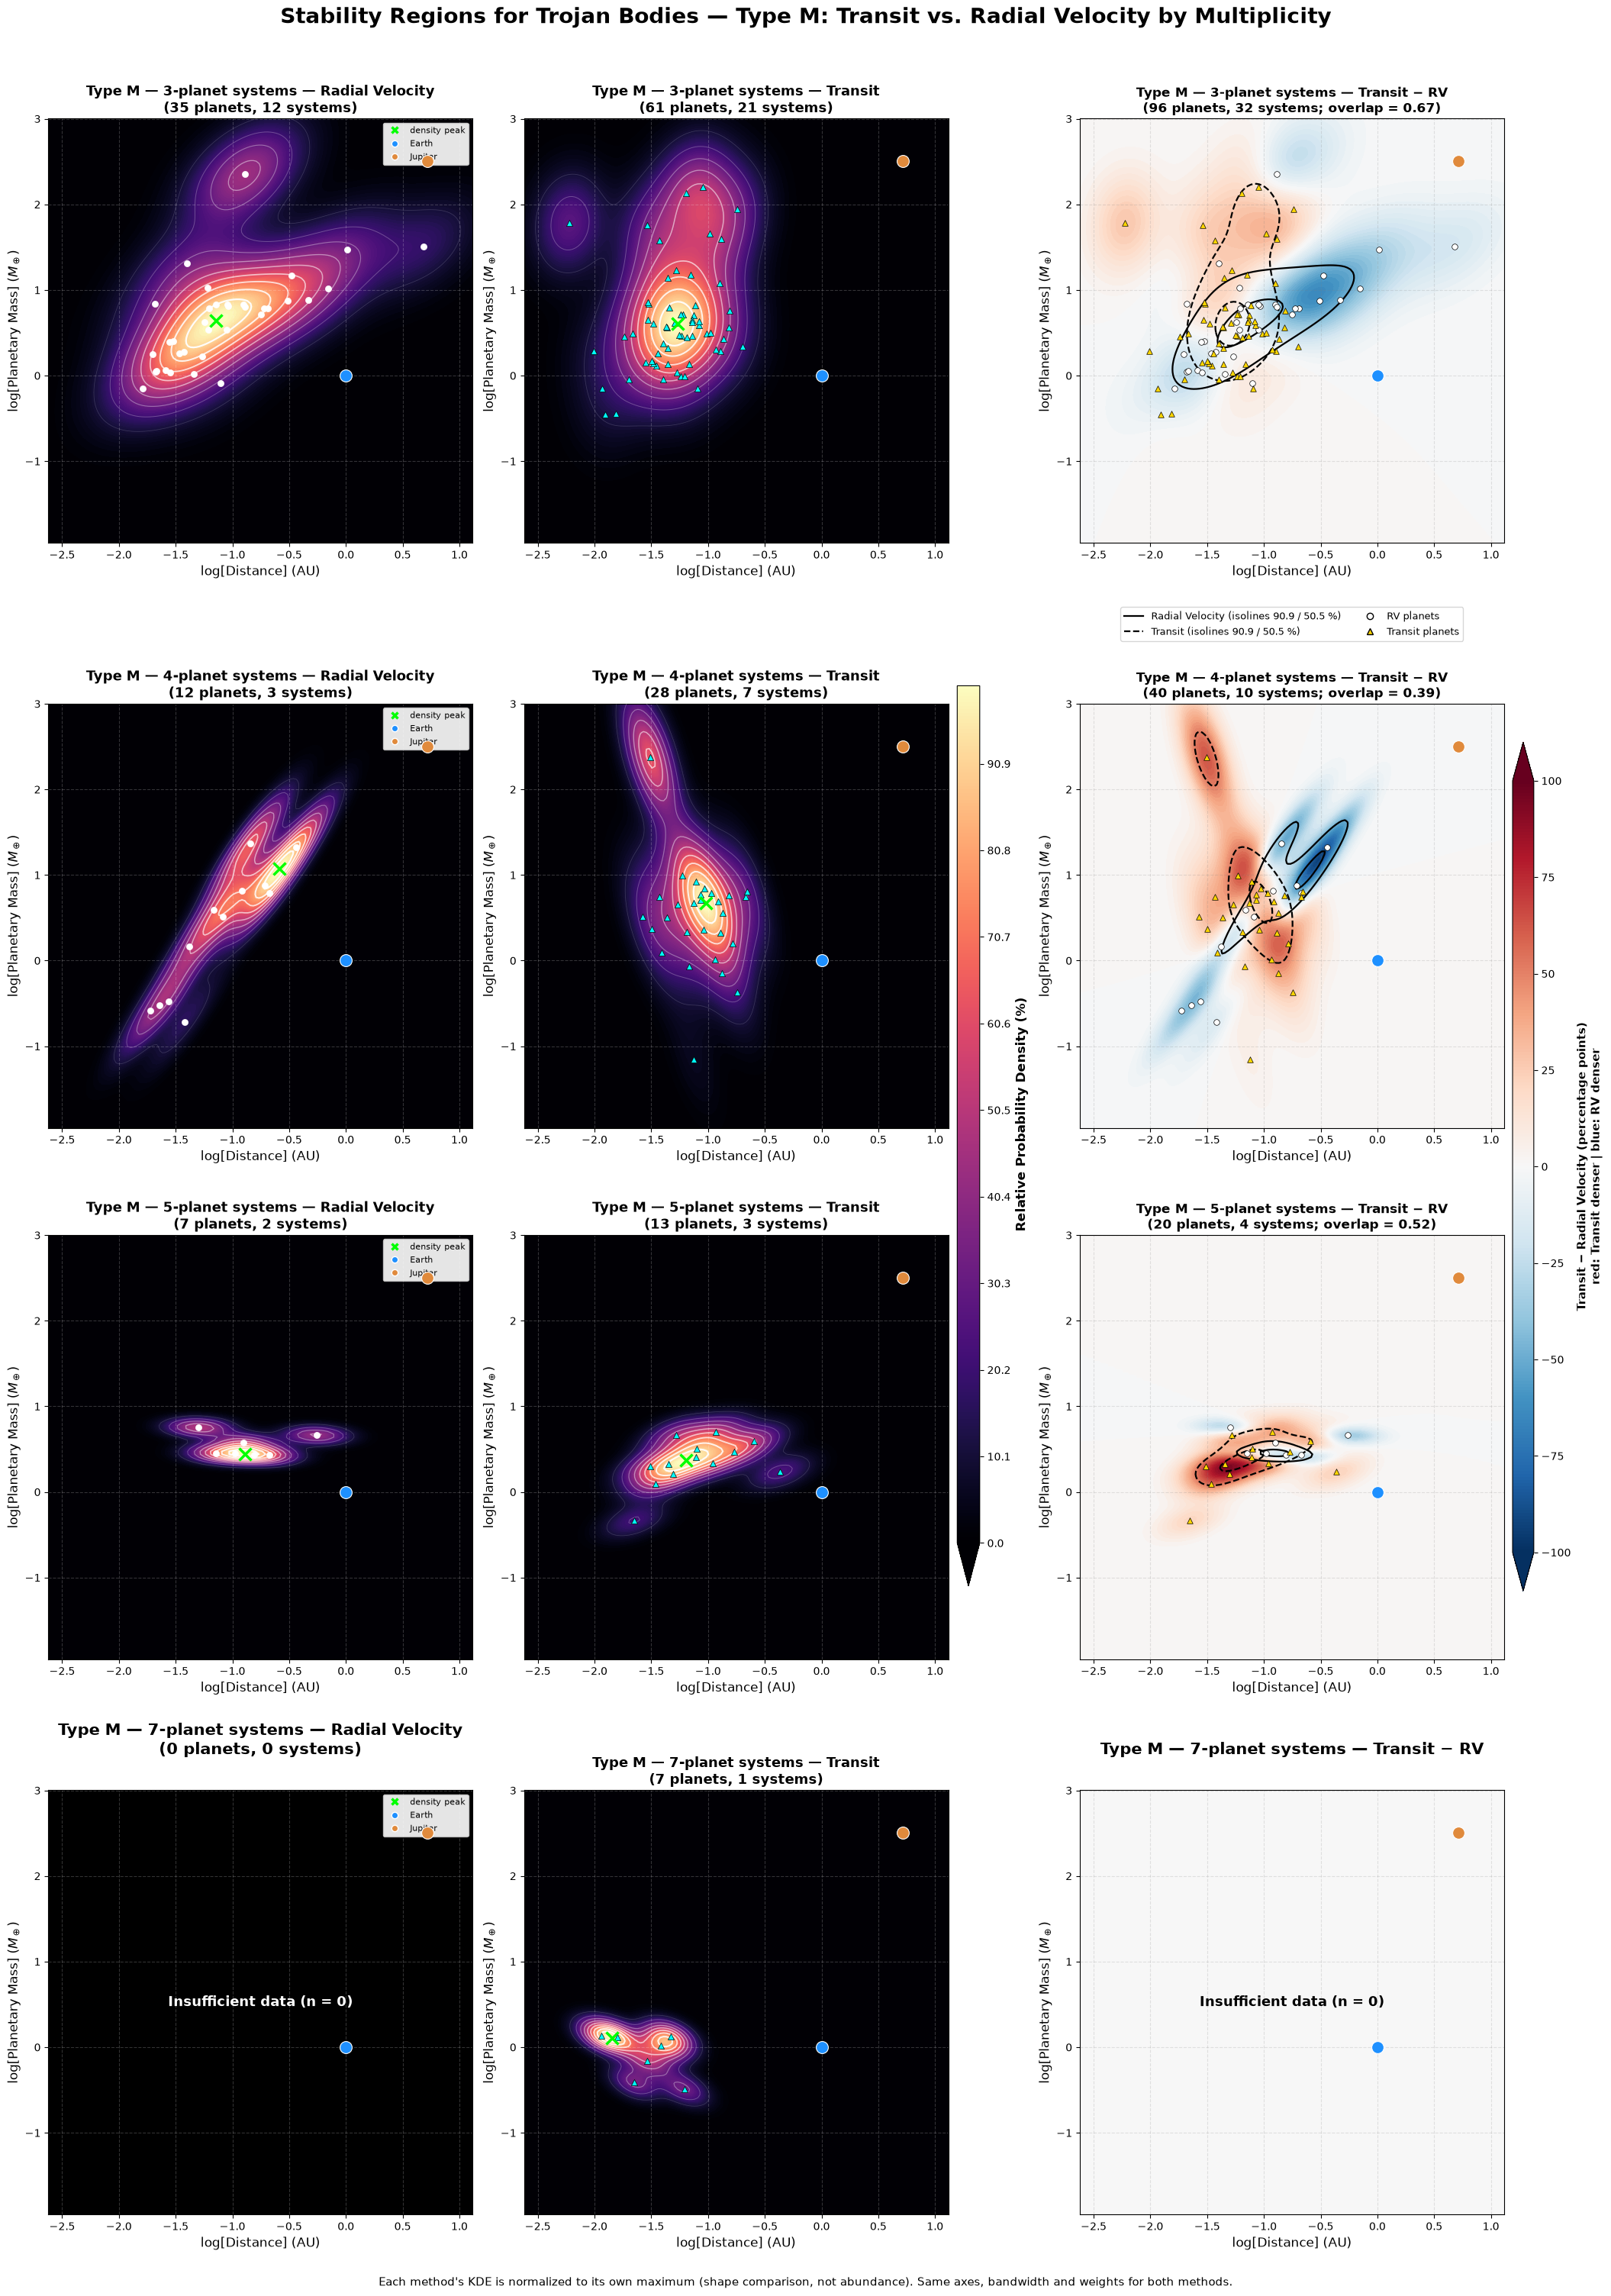

   Figuras guardadas: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_M\graficos_magma_con_sistemas_azules_por_metodo\comparacion_metodos_mult\KDE_comparacion_metodos_mult_Tipo_M_fraccion.png / .pdf

Métricas por multiplicidad guardadas en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Resultados_Estrellas_M\graficos_magma_con_sistemas_azules_por_metodo\comparacion_metodos_mult\comparacion_metodos_mult_fraccion.csv

Resultados guardados en: C:\Users\darkm\Desktop\archivos_Investigación\Investigacion\Resultados_Estrellas_M\graficos_magma_con_sistemas_azules_por_metodo\comparacion_metodos_mult


,Tipo,Num_Planetas,Pesos,N_planetas_RV,N_planetas_Transit,N_sistemas_RV,N_sistemas_Transit,Solapamiento,Pico_RV_a_UA,Pico_RV_m_Mt,Pico_Transit_a_UA,Pico_Transit_m_Mt,Estado,Detalle
0,M,3,fraccion,35,61,12,21,0.669683,0.072151,4.365831,0.054052,4.043878,ok,
1,M,4,fraccion,12,28,3,7,0.392124,0.257121,11.818482,0.096310,4.713415,ok,
2,M,5,fraccion,7,13,2,3,0.523000,0.128559,2.757109,0.064279,2.365463,ok,
3,M,7,fraccion,0,7,0,1,NaN,NaN,NaN,0.014316,1.281639,datos insuficientes RV,


In [13]:
from IPython.display import display

if RUTA_CSV.strip():
    # Cargar datos preparados previamente, sin depender de ventanas Tkinter.
    df = pd.read_csv(os.path.expanduser(RUTA_CSV), encoding="utf-8-sig")
    base = os.path.dirname(os.path.abspath(os.path.expanduser(RUTA_CSV)))
else:
    # Mismo extractor del script original. Requiere Jupyter local con escritorio.
    df, base = extraer_datos_personalizados()

if df.empty:
    print("No se encontraron datos. Comprueba RUTA_CSV o las carpetas seleccionadas.")
    tabla_metricas = pd.DataFrame()
else:
    df = df[df["Sistema"] != SISTEMA_SOLAR["nombre_sistema"]].reset_index(drop=True)
    carpeta_raiz = (os.path.expanduser(CARPETA_SALIDA) if CARPETA_SALIDA.strip() else
                    os.path.join(base, SALIDA_CARPETA +
                                 ("_por_metodo" if POR_METODO_DEFECTO else "")))
    os.makedirs(carpeta_raiz, exist_ok=True)
    df.to_csv(os.path.join(carpeta_raiz, "datos_extraidos.csv"),
              index=False, encoding="utf-8-sig")
    carpeta_comparacion = os.path.join(carpeta_raiz, "comparacion_metodos_mult")
    tabla_metricas = comparar_metodos_por_multiplicidad(
        df,
        carpeta_comparacion,
        modo_peso=MODO_PESO,
        n_min=N_MIN,
        agrupar_mult=AGRUPAR_MULT,
        con_regiones=CON_REGIONES,
    )
    print(f"\nResultados guardados en: {os.path.abspath(carpeta_comparacion)}")
    display(tabla_metricas)
